# WikiText (Wikipedia) word-level pipeline

This is the Google Colab notebook as it was run for the paper's word-level experiments. API keys, Hugging Face
tokens and Google Sheet / Drive IDs are replaced by placeholders (`os.environ["GOOGLE_API_KEY"]`, `<HF_TOKEN>`,
`<GOOGLE_SHEET_ID>`); one screenshot was removed. The notebook reads and writes Google Drive files and Google
Sheets through `gspread`; the workbooks in `data/` are exports of those sheets (`data/Wiki_text.xlsx`, `data/SFT_qlora_Wiki_Text.xlsx`). To run it outside
Colab, replace that I/O with reads of the exported workbooks. The reconstructions were decoded with
gemini-2.0-flash, which has since been retired.

Naming map (notebook -> paper):

| Notebook | Paper |
|---|---|
| Benchmark Way, fixed-step deletion (`benchmark` sheet) | Step |
| Way 1, word-length deletion (`adaptive_..._length_deletion` sheet) | WordLen |
| Way 2, word frequency with 3 / 6 classes (`wf_3classes` / `wf_6classes`) | WordFreq-3 / WordFreq-6 |
| Way 3, optimization for word frequency (`wf_optimal`) | LP |
| "Without Prepolish" (`wf_optimal_without_prepolish`) | an LP variant calibrated without the second decoder pass; not in the paper's tables |
| "LLM for restoration", `restored_*` columns | first decoder pass |
| "LLM for polishment", `polished_*` columns | second decoder pass; its outputs are the reconstructions the paper scores ("Without Polished" = a single pass) |
| Way 4, SFT | QLoRA fine-tuned Llama-3.2-3B-Instruct decoder |
| Way 4.1, base model used by SFT | the same model without fine-tuning (zero-shot) |

The WikiText notebook behind the word-level rows of Table 25 and the QLoRA fine-tuning and base-model comparison behind its Llama rows (`analysis/compute_wiki_llama_rows.py` recomputes those rows from the workbook).


# WikiText Dataset Summary

## Data Source

In [ ]:
import pandas as pd
from datasets import load_dataset

ds= load_dataset("Salesforce/wikitext",'wikitext-103-raw-v1')

In [ ]:
ds

In [ ]:
dft = ds["train"].to_pandas()
dft.head(10)

In [ ]:
dfv = ds["validation"].to_pandas()
dfv.tail(10)

In [ ]:
dfts = ds["test"].to_pandas()
dfts.tail(10)

In [ ]:
df = pd.concat([dft, dfv, dfts], axis=0, ignore_index=True)
df.head(10)

In [ ]:
df.shape[0]

In [ ]:
!pip install --quiet tiktoken
import tiktoken

# 初始化 tokenizer
enc = tiktoken.get_encoding("cl100k_base")

# 定义统计函数
def count_tokens(text: str) -> int:
    """统计文本的 token 数"""
    return len(enc.encode(str(text)))

# 在 df 里添加 token 数列
df["token_count"] = df["text"].apply(count_tokens)

df = df[
    (df["token_count"] >= 250) &
    (df["token_count"] <= 550)
]

df

In [ ]:
# 2️⃣ 去空字符串
df = df[df["text"].str.strip() != ""]

# 3️⃣ 去重
df = df.drop_duplicates(subset=["text"])

print("去重后数据量:", len(df))

In [ ]:
df_sample = df[
    (df["token_count"] >= 350) &
    (df["token_count"] <= 500)
]

df_sample.shape[0]

In [ ]:
df_sample_5000 = df_sample.sample(n=5000, random_state=42)

In [ ]:
df_sample_5000

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
out_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/Wiki_datasource/"

file_path = out_path + "df_sample_5000.json"

df_sample_5000.to_json(file_path, orient="records", lines=True)

In [ ]:
df_sample_200 =df_sample_5000.sample(n=200)

In [ ]:
df_sample_200 = df_sample_200.reset_index()
df_sample_200

In [ ]:
df = df_sample_200.drop(columns=["index"], errors="ignore")

In [ ]:
import tiktoken
import pandas as pd

enc = tiktoken.get_encoding("cl100k_base")

def count_tokens(text) -> int:
    if not isinstance(text, str) or not text.strip():
        return 0
    return len(enc.encode(text))

# 在 DataFrame 中新增一列 token_count
df["token_count"] = df["wiki_text"].apply(count_tokens)
df["char_length"] = df["wiki_text"].apply(
    lambda x: len(x) if isinstance(x, str) else 0
)

In [ ]:
!pip install lz4
import zlib,gzip,bz2,lzma,lz4.frame
import lzma

def compute_compression_ratios(text: str):
    raw = text.encode("utf-8")
    n = len(raw)

    gzip_ratio = len(gzip.compress(raw)) / n
    lzma_ratio = len(lzma.compress(raw)) / n
    bz2_ratio = len(bz2.compress(raw)) / n
    lz4_ratio=len(lz4.frame.compress(raw)) / n

    return {
        "gzip": gzip_ratio,
        "bz2": bz2_ratio,
        "lzma": lzma_ratio,
        "lz4":lz4_ratio
    }
df["compression"] = df["wiki_text"].apply(compute_compression_ratios)
df.head(10)

In [ ]:
import ast,re
df["lzma_ratio"] = df["compression"].apply(lambda x: x["lzma"])
df["lz4_ratio"] = df["compression"].apply(lambda x: x["lz4"])
df["gzip_ratio"] = df["compression"].apply(lambda x: x["gzip"])
#df["gzip_ratio"] = df["compression"].apply(
#    lambda s: ast.literal_eval(s)["gzip"]
#)

df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("datasource")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="datasource", rows="5000", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Way1: Updated Word Deletion starting from small word

Way 1: Updated small/long word length deletion

Fixed the compression ratio.

The algorithm incrementally modifies the input text until the compression ratio falls within the target interval  [r−ϵ,r). After each modification, the current ratio

ratio(x′)=∣𝑥′∣/∣𝑥∣

is evaluated, and the algorithm terminates immediately once the target interval is satisfied.

Stage C: Partial whitespace deletion

Before modifying word tokens, the algorithm first attempts to reduce the text length by progressively removing spaces between tokens.

Specifically, the algorithm decreases the probability of keeping a space between adjacent tokens using a sequence of probabilities:

0.98 → 0.95 → 0.9 → 0.8 → 0.7 → 0.5 → 0.3 → 0.1 → 0.0

During this stage:

punctuation remains attached to adjacent tokens

words and numbers remain unchanged

only spaces are partially removed

After each adjustment of the space-retention probability, the compression ratio is checked for early termination.

Stage 1: Progressive vowel deletion in long words

If whitespace deletion alone is insufficient, the algorithm modifies long words.

We first identify all alphabetic tokens with length ≥ 3 and sort them by descending length.

For each word w, let V(w) denote the indices of its vowels. The algorithm then applies progressively stronger edits:

delete 1 vowel from w
delete 2 vowels

…

delete all vowels (yielding a consonant skeleton)

After each deletion, the overall compression ratio is evaluated. If the ratio falls within [r−ϵ,r), the algorithm terminates early.

This stage reflects natural vowel-drop phenomena (e.g., “documentation → dcmnttn”).

Stage 2: Short-word modification

If Stage 1 is still insufficient to meet the compression target, the algorithm transitions to modifications of shorter words while preserving token order.

The following operations are applied sequentially:

Length-2 words: delete exactly one character (e.g., “at” → “a”)

Length-1 words: remove the token entirely

Length-2 words (full deletion): delete the whole token

Each operation is followed by an early stopping check.

Stage A (Fallback 1): Further long-word reduction

If the compression target is still unmet, long words (length ≥ 3) are further shortened by removing additional characters while preserving at least one character per word.

The algorithm progressively reduces the retained fraction of characters using the sequence:

0.8 → 0.6 → 0.5 → 0.4 → 0.3 → 0.2

After each modification, the compression ratio is checked for early stopping.

Stage E (Fallback 2): Punctuation deletion

If necessary, punctuation tokens are removed next. Each punctuation deletion is followed by a compression-ratio check.

Stage D (Fallback 3): Numeric token deletion

If punctuation removal is insufficient, numeric tokens (e.g., “2026”, “123”) are removed.

Stage F (Final fallback): Character-level deletion

As a final fallback, the algorithm randomly removes remaining characters (excluding whitespace) until the compression ratio falls within the target interval.

Early Stopping

The algorithm is monotonic in deletion cost: each transformation strictly reduces the text length. Therefore, the earliest point at which the compression ratio satisfies the target interval yields the minimally destructive distortion.

这个压缩方法的目标是：
在不破坏太多语义的前提下，通过逐步删除元音和简化短词，让文本达到指定的压缩率。


确定目标压缩区间

假设目标是保留 90%（ratio=0.9），允许 2% 的误差：

* 最小允许长度：88%

* 最大长度：90%

压缩必须落在 [88%, 90%) 之间。



### dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "adaptive_length_deletion"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
!pip install lz4
import zlib,gzip,bz2,lzma,lz4.frame
import lzma

def compute_compression_ratios(text: str):
    raw = text.encode("utf-8")
    n = len(raw)

    gzip_ratio = len(gzip.compress(raw)) / n
    lzma_ratio = len(lzma.compress(raw)) / n
    bz2_ratio = len(bz2.compress(raw)) / n
    lz4_ratio=len(lz4.frame.compress(raw)) / n

    return {
        "gzip": gzip_ratio,
        "bz2": bz2_ratio,
        "lzma": lzma_ratio,
        "lz4":lz4_ratio
    }
df["compression"] = df["Articles"].apply(compute_compression_ratios)
df.head(10)

In [ ]:
import ast,re
df["lzma_ratio"] = df["compression"].apply(lambda x: x["lzma"])
df["lz4_ratio"] = df["compression"].apply(lambda x: x["lz4"])
df["gzip_ratio"] = df["compression"].apply(lambda x: x["gzip"])
#df["gzip_ratio"] = df["compression"].apply(
#    lambda s: ast.literal_eval(s)["gzip"]
#)

df.head(10)

### *Adaptive Word Deletion Strategy

In [ ]:
import re
import random

VOWELS = "aeiouAEIOU"


def detokenize_partial_space(tokens, keep_space_prob=1.0):
    """
    keep_space_prob=1.0 -> 全保留空格（等价于原 detokenize 的加空格逻辑）
    keep_space_prob=0.0 -> 全删空格（等价于 drop_spaces=True）
    0<p<1              -> 只保留一部分空格（其余空格不加）
    """
    out = []
    for tok in tokens:
        if tok == "":
            continue
        if not out:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):  # 标点紧贴
                out.append(tok)
            else:
                if random.random() < keep_space_prob:
                    out.append(" " + tok)
                else:
                    out.append(tok)
    return "".join(out)


def compress_gradual_vowel_full(
        text,
        target_ratio=1.0,
        margin=0.02   # target=0.9 → [0.88, 0.90)
    ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    original_len = len(text)

    # ---- 定义目标范围 ----
    max_len = int(original_len * target_ratio)
    min_len = int(original_len * (target_ratio - margin))

    new_tokens = tokens[:]
    keep_space_prob = 1.0  # Step C：只删除“部分空格”（不删标点/数字）

    def current_text():
        return detokenize_partial_space(new_tokens, keep_space_prob=keep_space_prob)

    def current_len():
        return len(current_text())

    def acceptable():
        L = current_len()
        return (min_len <= L < max_len)

    # =====================================================
    # Step C：先删除空格（不删除标点/数字）——只删一部分空格（逐级）
    # =====================================================
    for p in (0.98, 0.95, 0.9, 0.8, 0.7, 0.5, 0.3, 0.1, 0.0):
        keep_space_prob = p
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 1：长词逐级删除元音（k=1→2→…→all）
    # =====================================================
    long_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) >= 3
    ]
    long_positions.sort(key=lambda x: len(x[1]), reverse=True)

    for idx, word in long_positions:
        vowels = [i for i, c in enumerate(word) if c in VOWELS]
        if not vowels:
            continue

        for k in range(1, len(vowels) + 1):
            del_positions = random.sample(vowels, k)
            w = word
            for pos in sorted(del_positions, reverse=True):
                w = w[:pos] + w[pos + 1:]
            new_tokens[idx] = w

            if acceptable():
                final = current_text()
                return final, len(final) / original_len

        # 删除所有元音
        w = "".join(c for c in word if c not in VOWELS)
        new_tokens[idx] = w

        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 2：短词删除策略（保持原顺序）
    # =====================================================
    short2_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 2
    ]

    # Step 2.1: len=2 -> 删除一个字母
    for idx, tok in short2_positions:
        pos = random.choice([0, 1])
        new_tokens[idx] = tok[:pos] + tok[pos + 1:]
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.2: 删除长度=1 的词
    short1_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 1
    ]

    for idx, tok in short1_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.3: 删除整个长度=2 的词
    for idx, tok in short2_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step A（兜底 1）：长词继续删辅音/字符（按比例/逐级）
    # =====================================================
    for keep_frac in (0.8, 0.6, 0.5, 0.4, 0.3, 0.2):
        for idx, tok in enumerate(new_tokens):
            if tok.isalpha() and len(tok) >= 3:
                L = len(tok)
                keep_len = max(1, int(L * keep_frac + 0.9999))  # ceil
                if keep_len >= L:
                    continue

                keep_pos = {0}
                if keep_len > 1:
                    rest = list(range(1, L))
                    keep_pos |= set(random.sample(rest, keep_len - 1))

                new_tokens[idx] = "".join(tok[i] for i in range(L) if i in keep_pos)

                if acceptable():
                    final = current_text()
                    return final, len(final) / original_len

    # =====================================================
    # Step E（兜底 2）：先删除标点 token（标点在数字之前）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if re.match(r"^[^\w\s]$", tok):
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step D（兜底 3）：再删除数字 token（例如 2026, 123）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if tok.isdigit():
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step F（最终兜底）：随机删除其他字符（字符级）
    # =====================================================
    text_now = current_text()
    chars = list(text_now)

    delete_positions = [i for i, c in enumerate(chars) if c.strip() != ""]
    random.shuffle(delete_positions)

    for pos in delete_positions:
        chars[pos] = ""
        candidate = "".join(chars)
        L = len(candidate)
        if min_len <= L < max_len:
            return candidate, L / original_len

    final = "".join(chars)
    return final, len(final) / original_len


In [ ]:
#text = "The information processing system was originally designed for efficiency and clarity."
text=df["wiki_text"].iloc[75]
compressed, ratio = compress_gradual_vowel_full(text, 0.10, margin=0.02)

print(compressed)
print("Actual ratio:", ratio)


In [ ]:
# 固定压缩率
fixed_ratios = {
    "ratio_90": 0.90,
    "ratio_80": 0.80,
    "ratio_70": 0.70,
    "ratio_60": 0.60,
    "ratio_50": 0.50,
    "ratio_40": 0.40,
    "ratio_30": 0.30,
    "ratio_20": 0.20,
    "ratio_10": 0.10
}

# ---------------------------
# A. 先处理固定 ratio
# ---------------------------

for name, r in fixed_ratios.items():
    col_text = f"{name}_text"
    col_ratio = f"{name}_actual"

    df[[col_text, col_ratio]] = df["wiki_text"].apply(
        lambda x: pd.Series(compress_gradual_vowel_full(x, target_ratio=r, margin=0.02))
    )


# ---------------------------
# B. 再处理 gzip_ratio（每行不同）
# ---------------------------

df[["ratio_lzma_text", "ratio_lzma_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["wiki_text"],
            target_ratio=round(row["lzma_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)
df[["ratio_lz4_text", "ratio_lz4_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["wiki_text"],
            target_ratio=round(row["lz4_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)
df[["ratio_gzip_text", "ratio_gzip_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["wiki_text"],
            target_ratio=round(row["gzip_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)

In [ ]:
df.head(10)

In [ ]:
lst=df[df["ratio_lz4_text"]==""].index
print(lst)

In [ ]:
for i in lst:
  text=df.at[i,"wiki_text"]
  target_ratio=round(df.at[i,"lz4_ratio"],2)
  compressed, ratio = compress_gradual_vowel_full(text, target_ratio, margin=0.03)
  df.at[i,"ratio_lz4_text"]=compressed
  df.at[i,"ratio_lz4_actual"]=ratio


In [ ]:
import pandas as pd

names = ["90", "80", "70", "60", "50", "40", "30", "20", "10", "gzip", "lzma", "lz4"]

def build_char_dicts(row):
    char_dict = {}
    actual_dict = {}

    for name in names:
        text_col = f"ratio_{name}_text"
        actual_col = f"ratio_{name}_actual"
        key = f"deleted_char_{name}"

        if text_col in row and pd.notna(row[text_col]):
            char_dict[key] = row[text_col]

        if actual_col in row and pd.notna(row[actual_col]):
            actual_dict[key] = row[actual_col]

    return pd.Series([char_dict, actual_dict])

df[["df_char", "actual_ratio_char"]] = df.apply(build_char_dicts, axis=1)

In [ ]:
cols = [

    "ratio_90_actual", "ratio_80_actual", "ratio_70_actual", "ratio_60_actual",
    "ratio_lz4_actual", "ratio_lzma_actual","lz4_ratio", "lzma_ratio"
]

summary = df[cols].agg(["mean", "std"])
summary

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("adaptive_length_deletion")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="adaptive_length_deletion", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Char_restoration and polishment

In [ ]:
import ast, re
df["df_char"] = df["df_char"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)


In [ ]:
keys_char = ["deleted_char_90", "deleted_char_80", "deleted_char_lz4", "deleted_char_70", "deleted_char_60", "deleted_char_lzma","deleted_char_gzip","deleted_char_50", "deleted_char_40", "deleted_char_30", "deleted_char_20", "deleted_char_10"]

In [ ]:
import os

import pandas as pd
import time
import ast
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")


def build_prompt(input_text):
    return f"""
You are a linguistic reconstruction and refinement model.

Your task is to recover and polish a corrupted text into fluent, natural, and grammatically correct English.

The input may contain missing letters, missing short words, or partially deleted content.

### Core Requirements:

1. **Faithful Reconstruction:**
   - Restore the text to its closest original form.
   - Do NOT paraphrase or introduce new meaning.
   - Only recover missing or corrupted parts.

2. **Fluency & Readability:**
   - Ensure the output is smooth, natural, and human-readable.
   - Fix grammatical issues and awkward phrasing caused by corruption.

3. **Structural Preservation (Strict):**
   - Maintain **1:1 sentence correspondence** (no merging or splitting).
   - Preserve the original order and structure exactly.
   - This is critical for alignment-based evaluation.

4. **Semantic Integrity & Zero Hallucination:**
   - Do not add, remove, or speculate any information.
   - If content is ambiguous, improve grammar without inventing meaning.

### Output Policy:
- Return ONLY the final reconstructed and polished text.
- No explanations or meta text.

Input:
{input_text}

Output:
""".strip()


def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")

            time.sleep(2 * (attempt + 1))

    return corrupted_text
# =========================
# ✅ 你要恢复的 dict keys

# =========================
# ✅ 先创建输出列（直接写成列，不用 dict 列）
# =========================
for k in keys_char:
    out_col = k.replace("deleted_", "polished_")   # deleted_char_90 -> restored_char_90
    if out_col not in df.columns:
       df[out_col] = ""

# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
for idx in range(len(df)):
    print(f"\n---- Index {idx} ----")

    char_dict = df.at[idx, "df_char"]

    # ✅ 👇 就加在这里（紧跟在读取之后）
    if isinstance(char_dict, str):
        char_dict = ast.literal_eval(char_dict)

    # ✅ 再判断 dict
    if isinstance(char_dict, dict):
        for k in keys_char:
            if k in char_dict:
                corrupted = char_dict[k]
                out_col = k.replace("deleted_", "polished_")

                polished = restore_text(corrupted)

                df.at[idx, out_col] = polished
                print(out_col,"Polished:")
                print(polished)



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("adaptive_length_deletion")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="adaptive_length_deletion", rows="300", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric performance

### Updated quick bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"


def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = scorer.score(hyp_list, ref_list)
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:
df["polished_char_bert_chunk"] = None
df["polished_char_bert_sentence"] = None

polished_text_cols =["polished_char_90", "polished_char_80", "polished_char_70", "polished_char_60",
   "polished_char_lz4", "polished_char_lzma", "polished_char_gzip","polished_char_50",
    "polished_char_40", "polished_char_30", "polished_char_20", "polished_char_10"]

In [ ]:
df["polished_char_bert_chunk"] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_char_{ratio}"

    originals = df[col_gt].apply(clean_text).tolist()
    restoreds = df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- 🔥 存入 dict（关键修改）--------
    for i, (p, r, f) in enumerate(zip(P, R, F1)):
        df.at[i, "polished_char_bert_chunk"][col_pred] = {
            "P": float(p),
            "R": float(r),
            "F1": float(f)
        }

In [ ]:
col_out = "polished_char_bert_sentence"

df[col_out] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_char_{ratio}"

    all_refs = []
    all_hyps = []
    row_map = []

    # ===============================
    # 1️⃣ Collect sentences
    # ===============================
    for idx in range(len(df)):
        original = clean_text(df.at[idx, col_gt])
        restored = clean_text(df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
        all_hyps,
        all_refs,
        model_type=MODEL,
        lang="en",
        verbose=False,
        batch_size=64
    )

    # ===============================
    # 3️⃣ Aggregate per row
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    # ===============================
    # 4️⃣ 🔥 写入 dict（关键）
    # ===============================
    for idx in range(len(df)):
        df.at[idx, col_out][col_pred] = row_sentence_scores[idx]

In [ ]:
import numpy as np
import pandas as pd

ratios = [90, 80, "lz4", 70, 60, "lzma", "gzip", 50, 40, 30, 20, 10]

rows = [
    "P_chunk_mean", "P_chunk_std",
    "R_chunk_mean", "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",
    "P_sent_mean", "P_sent_std",
    "R_sent_mean", "R_sent_std",
    "F1_sent_mean", "F1_sent_std"
]

summary = pd.DataFrame(index=rows, columns=ratios)

for ratio in ratios:

    key = f"polished_char_{ratio}"

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    chunk_scores = [
        d.get(key)
        for d in df["polished_char_bert_chunk"]
        if isinstance(d, dict) and key in d
    ]

    if len(chunk_scores) == 0:
        continue

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level
    # =========================
    sent_lists = [
        d.get(key)
        for d in df["polished_char_bert_sentence"]
        if isinstance(d, dict) and key in d
    ]

    all_sent_scores = [
        s
        for sent_list in sent_lists
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # 写入（关键）
    # =========================
    summary.loc["P_chunk_mean", ratio] = P_chunk.mean()
    summary.loc["P_chunk_std",  ratio] = P_chunk.std()

    summary.loc["R_chunk_mean", ratio] = R_chunk.mean()
    summary.loc["R_chunk_std",  ratio] = R_chunk.std()

    summary.loc["F1_chunk_mean", ratio] = F1_chunk.mean()
    summary.loc["F1_chunk_std",  ratio] = F1_chunk.std()

    summary.loc["P_sent_mean", ratio] = P_sent.mean()
    summary.loc["P_sent_std",  ratio] = P_sent.std()

    summary.loc["R_sent_mean", ratio] = R_sent.mean()
    summary.loc["R_sent_std",  ratio] = R_sent.std()

    summary.loc["F1_sent_mean", ratio] = F1_sent.mean()
    summary.loc["F1_sent_std",  ratio] = F1_sent.std()

summary

### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer


restore_cols = ["polished_char_90","polished_char_80","polished_char_lz4","polished_char_70","polished_char_60","polished_char_lzma",
                "polished_char_gzip","polished_char_50","polished_char_40","polished_char_30","polished_char_20","polished_char_10"]
restore_suffixes = [c.replace("polished_char_", "") for c in restore_cols]

df["char_cer"] = None
df["char_wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "wiki_text"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_char_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "char_cer"] = cer_dict
    df.at[idx, "char_wer"] = wer_dict



In [ ]:
import ast
import numpy as np
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "char_cer"]
        if isinstance(cer_dict, str):
            cer_dict = ast.literal_eval(cer_dict)

        wer_dict = df.at[idx, "char_wer"]
        if isinstance(wer_dict, str):
            wer_dict = ast.literal_eval(wer_dict)

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
summary_cer

### LLM for restoration

In [ ]:
import os
!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")


# 示例损坏文本
corrupted_text = "Th quck brwn fx jmps ovr th lzy dg."

# 你的恢复 prompt（可替换）
prompt = f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
"""

# 调用 Gemini API
#response = model.generate_content(prompt)
response = model.generate_content(
    prompt,
    generation_config={
        "temperature": 0.1,
        "max_output_tokens": 1024,
        "top_p": 0.9,
        "top_k": 40
    }
)

# 输出结果
print(response.text)

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()

def build_prompt_sen_v2(corrupted_text):
    return f"""
You are a linguistic reconstruction model whose goal is to recover missing content from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Reconstruct the text to be as close as possible in meaning and structure to the original,
BUT you must avoid verbatim reproduction of any copyrighted text.
If exact wording is uncertain, use a natural alternative that preserves the original meaning.

Requirements:
- Restore missing parts only.
- Preserve sentence boundaries and order.
- Do NOT add new information or change the meaning.
- Do NOT quote or reproduce long verbatim spans from any known source.

Corrupted input:
{corrupted_text}

Reconstructed output:
""".strip()

def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


cols_to_restore = ["ratio_70_text","ratio_60_text", "ratio_lzma_text",
"ratio_gzip_text", "ratio_50_text","ratio_40_text", "ratio_30_text",  "ratio_20_text", "ratio_10_text"]


for col in cols_to_restore:
    curr_col = col.replace("ratio_", "").replace("_text", "")
    output_col = f"restored_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")


    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        if idx==88:
          restored = restore_text_sen(corrupted)
        else:
          restored = restore_text(corrupted)

        print(output_col,"Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
cols_to_restore = ["restored_90","restored_80","restored_70","restored_60","restored_lzma","restored_lz4",
                   "restored_50","restored_40","restored_gzip","restored_30",
                   "restored_20","restored_10"]

df[df[cols_to_restore].eq("").any(axis=1)].index.tolist()


In [ ]:
for idx in lst:
    for output_col in cols_to_restore:
        curr_col=output_col.split("_")[1]
        input_col=f"ratio_{curr_col}_text"
        corrupted = df.at[idx,input_col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text_sen(corrupted)


        print(output_col,"Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored

In [ ]:
import os
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])#os.environ["GOOGLE_API_KEY"])
                #

model = genai.GenerativeModel("gemini-2.5-pro")


def build_prompt_sen_v2(corrupted_text):
    return f"""
You are a linguistic reconstruction model whose task is to recover missing content from corrupted input.

The text may contain missing letters, missing short words, or partially deleted characters.

Reconstruct the text so that it preserves the original meaning and overall sentence structure,
while explicitly avoiding verbatim reproduction of any copyrighted or memorized text.
If the exact original wording is unclear or may be copyrighted, you MUST use a different but semantically equivalent expression.

Requirements:
- Restore missing parts only; do not rewrite intact content unnecessarily.
- Preserve the number, order, and boundaries of sentences.
- Do NOT add new information or remove existing meaning.
- Use natural language; paraphrasing at the phrase or clause level is allowed when needed.
- Do NOT quote or reproduce long verbatim spans from any known source.

Corrupted input:
{corrupted_text}

Reconstructed output:
""".strip()


def build_prompt_sen_v3(corrupted_text):
    return f"""
You are a linguistic reconstruction model whose task is to recover missing content from corrupted input.

The text may contain missing letters, missing short words, or partially deleted characters.


Corrupted input:
{corrupted_text}

Reconstructed output:
""".strip()


def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen_v3(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空




for idx in lst:
    for output_col in cols_to_restore:

        # ✅ 只跑空的那些
        if df.at[idx, output_col] != "":
            continue

        curr_col = output_col.split("_")[1]
        input_col = f"ratio_{curr_col}_text"
        corrupted = df.at[idx, input_col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text_sen(corrupted)

        print(output_col, "Restored:")
        print(restored)

        df.at[idx, output_col] = restored

In [ ]:
df.at[171,"restored_lzma"]="""The U.S. economy still growing, says Fed. Most of the U.S. saw the economy continue to expand in December and early January, the U.S. Federal Reserve said in its latest Beige Book report. Of the 12 U.S. regions it identifies for the study, 11 showed strong economic growth, with only the Cleveland area falling behind with a "mixed rating." Consumer spending was higher in December than November, and festive sales were also up on 2003. Employment picture also improved, the Fed said. "Labor markets firmed in a number of districts, but wage pressures generally remained modest," the Beige Book said. "Several districts reported higher prices for building materials and manufacturing inputs, but mostly reported steady or only slightly higher overall price levels." The report added that residential real estate activity remained strong and that commercial real estate activity strengthened in most districts. "Leasing was especially brisk in Washington D.C., and New York City, two of the nation's strongest commercial markets," the Fed said."""

In [ ]:
df.at[171,"restored_lzma"]

In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_length_deletion_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_length_deletion_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])#os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    # 修复了原代码中的变量名引用错误 (input_text)
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()

# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑
cols_to_restore = ["restored_90","restored_80","restored_lz4","restored_70","restored_60",
                   "restored_lzma","restored_50","restored_40","restored_gzip",
                   "restored_30","restored_20","restored_10"]
for col in cols_to_restore:
    curr_suffix = col.split("_")[1]
    output_col = f"polished_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        if df.at[idx, output_col]:
            continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_length_deletion_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_length_deletion_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric performance

#### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
original="""Benitez joy as Reds take control..Liverpool boss Rafael Benitez was satisfied after his team's 3-1 win over Bayer Leverkusen despite conceding a goal in the last minute..."Before the game if you had said the score will be 3-1 I would have happily accepted that," said Benitez. "But you must realise that you have to concentrate right to the very last seconds of a game at this level. "I have confidence that we can complete the task in Germany. I am always confident and we must be positive."..Benitez defended goalkeeper Jerzy Dudek, whose failure to hold on to Dimitar Berbatov's weak drive allowed Franca to score with the last kick of the game - and give the German team a lifeline for the second leg. "For me it was not Jerzy Dudek's fault," added Benitez. "He had played a very good game - and had we scored our other chances, nobody would be talking about about their goal. It would not have mattered. "If we had scored our other chances it would not have been worth remembering that last goal. "In my opinion Jerzy played well, made two very fine saves - and I am happy with him. "If we lose 2-0 we are out but I think we can score in Germany - certainly one, and that will make all the difference." And the Liverpool boss is looking forward to having skipper Steven Gerrard, who was suspended for the Anfield leg, back for the return in Germany..."Steven Gerrard is a key player for us," said Benitez. "When he is on the pitch he makes everyone else play better - and the opposition pay special attention to him - which gives space for others. "Steven is one of the best players in the world, but I need a team that is not about just one player. There must be 11 players on the pitch all doing well." """

restored="""Benitez Roads central.. Liverpool boss Rafa Benitez satisfied after' 3- 1 Bayer Leverkusen despite conceding last minute..." Before score well 3- 1 would happily accepted that," Benitez." must realise that concentrate right very last seconds this level." confidence that complete task Germany. always confident must positive.".. Benitez defended goalkeeper Jerzy Dudek, whose flair held Dimitar Berbatov' drive allowed France score with last kick- German lifeline second." For e it is not on Jerzy Dudek' s fault," added Benitez." we did played a very good game- and if we scored our three chances, nobody would be talking about about their luck. it would not have mattered." If we had scored our three chances it would not have worth remembering that last goal." If you punish Jerzy played well, made very nice saves- and I am happy with him." If we were 2- 0 we are talking about it I think we can score in Germany- certainly now, and that will make a lot difference." and the Liverpool boss is looking forward to having skipper Steven Gerrard, who was suspended for the Anfield leg, back for the return in Germany..." Steven Gerrard is a key player for us," said Benitez." When he is on the pitch he makes everyone else play better- and he opposition pay special attention to him- which gives space for others." Steven is one of the best players in the world, but I do admire that it is not just one player. There must be 11 players on the pitch all doing well." """

polished="""Benitez, the Liverpool boss, expressed satisfaction after their 3-1 victory over Bayer Leverkusen, despite conceding a last-minute goal. He acknowledged that a score of 3-1 would have been a happy outcome. Benitez emphasized the importance of maintaining focus in the final moments of the match. He expressed confidence in their ability to complete the task against Germany. Benitez defended goalkeeper Jerzy Dudek, whose impressive saves prevented Dimitar Berbatov from scoring and allowed France to score with the last kick, which was considered a lifeline for Germany. Benitez stated that it was not Dudek’s fault and that they had played a very good game. He believed that if they had scored their three chances, the last goal would not have been as significant. Benitez praised Dudek’s performance, highlighting his excellent saves and expressing his happiness with him. He mentioned that if they had been 2-0, the last goal would not have been as memorable. Benitez acknowledged that Dudek’s performance was crucial and that he made everyone else play better. He also noted that the opposition paid special attention to him, creating space for others. Benitez regarded Steven Gerrard as a key player for Liverpool. He emphasized that Gerrard’s presence on the pitch elevates the performance of his teammates and draws the attention of the opposition, creating opportunities for others. Benitez admired Gerrard’s skill but also recognized that it was not just one player who contributed to the team’s success. He stressed the importance of all 11 players performing well on the pitch."""

In [ ]:
import re
from bert_score import score as bertscore

def clean_text(txt):
    if txt is None:
        return ""
    return re.sub(r"\s+", " ", str(txt)).strip()

def compute_bertscore(ref, hyp, model="distilroberta-base"):
    """
    输入两段文本 → 输出 P, R, F1
    """
    P, R, F1 = bertscore([hyp], [ref], model_type=model, lang="en", verbose=False)
    return float(P[0]), float(R[0]), float(F1[0])




In [ ]:
ori = clean_text(original)
res = clean_text(restored)
pol = clean_text(polished)

# Restored vs Original
P_res, R_res, F1_res = compute_bertscore(ori, res)

# Polished vs Original
P_pol, R_pol, F1_pol = compute_bertscore(ori, pol)

print("=== Restored vs Original ===")
print(f"P = {P_res:.4f}, R = {R_res:.4f}, F1 = {F1_res:.4f}")

print("\n=== Polished vs Original ===")
print(f"P = {P_pol:.4f}, R = {R_pol:.4f}, F1 = {F1_pol:.4f}")


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
df.head(2)

In [ ]:
df["polished_bert_chunk"] = None
df["polished_bert_sentence"] = None

polished_text_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                      "polished_50","polished_gzip","polished_40","polished_30","polished_20","polished_10"]

for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    # ✅ 只遍历这些列
    for col in polished_text_cols:
        #if col not in df.columns:
        #    continue

        restored = clean_text(df.at[idx, col])

        # 1️⃣ Chunk-level BERTScore
        P, R, F1 = bertscore(
            [restored], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # 2️⃣ Sentence-level pairs
        res_sents = sent_tokenize(restored)
        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # 🔥 batch sentence-level BERTScore
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # ✅ key 对齐 polished_text_cols
    sent_score = {col: [] for col in polished_text_cols}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    df.at[idx, "polished_bert_chunk"] = chunk_dict
    df.at[idx, "polished_bert_sentence"] = sent_score


In [ ]:
import ast
mask = df["bert_sentence"].apply(lambda x: isinstance(x, str))

df.loc[mask, "bert_sentence"] = df.loc[mask, "bert_sentence"].apply(ast.literal_eval)


In [ ]:
import numpy as np
wanted = {"polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                      "polished_50","polished_gzip","polished_40","polished_30","polished_20","polished_10"}
restore_cols = [c for c in df.columns if c in wanted]

rows = ["P_chunk", "R_chunk", "F1_chunk", "P_sent", "R_sent", "F1_sent"]
summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_bert_sentence"][col]

        # chunk-level
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # 写入 DataFrame（取平均）
    summary.loc["P_chunk", col] = np.mean(P_chunk_list)
    summary.loc["R_chunk", col] = np.mean(R_chunk_list)
    summary.loc["F1_chunk", col] = np.mean(F1_chunk_list)

    summary.loc["P_sent", col] = np.mean(P_sent_all)
    summary.loc["R_sent", col] = np.mean(R_sent_all)
    summary.loc["F1_sent", col] = np.mean(F1_sent_all)


In [ ]:
summary

In [ ]:
import numpy as np
import pandas as pd


restore_cols=["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                      "polished_50","polished_gzip","polished_40","polished_30","polished_20","polished_10"]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer


restore_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                "polished_gzip","polished_50","polished_40","polished_30","polished_20","polished_10"]
restore_suffixes = [c.replace("polished_", "") for c in restore_cols]

df["cer"] = None
df["wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "Articles"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict



In [ ]:
import ast
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "cer"]
        if isinstance(cer_dict, str):
            cer_dict = ast.literal_eval(cer_dict)

        wer_dict = df.at[idx, "wer"]
        if isinstance(wer_dict, str):
            wer_dict = ast.literal_eval(wer_dict)

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
summary_cer

#### BLEURT + NLI

Since the BLEURT/NLI cross-encoder is limited to 512 tokens, we apply a contiguous sliding-window segmentation with overlap on both the reference and the candidate texts. We compute the metric per aligned window pair and aggregate scores using (length-weighted) mean to reflect global fidelity, while additionally reporting a lower-tail statistic (e.g., p10/min) to capture localized degradations that may be masked by averaging.

In [ ]:
# ===========================
# Long-text Eval (Stable)
# BLEURT (Elron/bleurt-base-512) + NLI (cross-encoder/nli-roberta-base)
# - contiguous windows + overlap
# - zip-aligned (NO all-pairs)
# - hard max_length=512 (truncation + assert)
# - aggregates: BLEURT mean/p10/min, NLI max_contra/contra_rate/safe
# ===========================

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# -----------------------------
# 0) Utils
# -----------------------------
def norm_text(s: str) -> str:
    s = str(s).replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def per_side_budget(max_length=512, safety_margin=16):
    # RoBERTa-like pair uses ~4 special tokens: <s> A </s></s> B </s>
    special = 4
    return max(32, (max_length - special) // 2 - safety_margin)

def make_windows(text, tokenizer, chunk_size, stride):
    ids = tokenizer.encode(norm_text(text), add_special_tokens=False)
    windows = []
    for start in range(0, len(ids), stride):
        piece = ids[start:start + chunk_size]
        if not piece:
            break
        windows.append(piece)
        if start + chunk_size >= len(ids):
            break
    return windows

def aligned_windows(text_a, text_b, tokenizer, chunk_size, stride):
    wa = make_windows(text_a, tokenizer, chunk_size, stride)
    wb = make_windows(text_b, tokenizer, chunk_size, stride)
    n = min(len(wa), len(wb))
    return wa[:n], wb[:n]

def agg_scores(scores):
    if scores is None or len(scores) == 0:
        return {"mean": None, "p10": None, "min": None, "n": 0}
    arr = np.array(scores, dtype=float)
    return {
        "mean": float(arr.mean()),
        "p10": float(np.quantile(arr, 0.10)),
        "min": float(arr.min()),
        "n": int(arr.size),
    }

def encode_pairs(texts_a, texts_b, tokenizer, device, max_length=512):
    enc = tokenizer(
        texts_a, texts_b,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    ).to(device)
    # Hard guarantee: never silently exceed 512
    L = enc["input_ids"].shape[1]
    assert L <= max_length, f"Tokenizer did not truncate: seq_len={L} > {max_length}"
    return enc


# -----------------------------
# 1) Load models (GPU if available)
# -----------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

bleurt_tokenizer = AutoTokenizer.from_pretrained("Elron/bleurt-base-512")
bleurt_model = AutoModelForSequenceClassification.from_pretrained("Elron/bleurt-base-512").to(device).eval()

nli_tokenizer = AutoTokenizer.from_pretrained("cross-encoder/nli-roberta-base")
nli_model = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-roberta-base").to(device).eval()

LABELS = ["contradiction", "entailment", "neutral"]


# -----------------------------
# 2) BLEURT long-text via windows
# -----------------------------
def bleurt_long(ref_text, cand_text,
                tokenizer, model,
                max_length=512, stride_ratio=0.7, batch_size=16,
                safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wref, wcand = aligned_windows(ref_text, cand_text, tokenizer, chunk_size, stride)
    if len(wref) == 0:
        return {"scores": [], **agg_scores([]), "chunk_size": chunk_size, "stride": stride}

    refs = [tokenizer.decode(x) for x in wref]
    cands = [tokenizer.decode(x) for x in wcand]

    scores = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(refs), batch_size):
            enc = encode_pairs(refs[i:i+batch_size], cands[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            s = model(**enc).logits.squeeze(-1)  # regression scores
            scores.extend(s.detach().cpu().tolist())

    return {"scores": [float(x) for x in scores], **agg_scores(scores), "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 3) NLI safety long-text via windows (risk-first)
# -----------------------------
def nli_safety_long(premise_text, hyp_text,
                    tokenizer, model,
                    max_length=512, stride_ratio=0.7, batch_size=16,
                    contra_th=0.5, safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wp, wh = aligned_windows(premise_text, hyp_text, tokenizer, chunk_size, stride)
    if len(wp) == 0:
        return {"max_contra": None, "contra_rate": None, "safe": None, "n": 0, "chunk_size": chunk_size, "stride": stride}

    pres = [tokenizer.decode(x) for x in wp]
    hyps = [tokenizer.decode(x) for x in wh]

    contra_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(pres), batch_size):
            enc = encode_pairs(pres[i:i+batch_size], hyps[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            logits = model(**enc).logits
            probs = F.softmax(logits, dim=1).detach().cpu().numpy()  # (bs,3)
            contra_probs.extend(probs[:, 0].tolist())

    contra_probs = np.array(contra_probs, dtype=float)
    max_contra = float(contra_probs.max())
    contra_rate = float((contra_probs >= contra_th).mean())
    safe = bool(max_contra < contra_th)

    return {"max_contra": max_contra, "contra_rate": contra_rate, "safe": safe, "n": int(contra_probs.size),
            "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 4) Unified evaluation for one row/pair
# -----------------------------
def eval_longtext_pair(ref_text, cand_text,
                       bleurt_tokenizer, bleurt_model,
                       nli_tokenizer, nli_model,
                       max_length=512, contra_th=0.5,
                       stride_ratio=0.7, batch_size=16,
                       exact_match_override=True,
                       safety_margin=16):
    # Optional: exact-match override (keeps your stats sane)
    if exact_match_override and norm_text(ref_text) == norm_text(cand_text):
        return {
            "exact_match": True,
            "bleurt_mean": None, "bleurt_p10": None, "bleurt_min": None, "bleurt_n": 0,
            "nli_max_contra": 0.0, "nli_contra_rate": 0.0, "nli_safe": True, "nli_n": 0,
            "chunk_size": None, "stride": None
        }

    b = bleurt_long(ref_text, cand_text, bleurt_tokenizer, bleurt_model,
                    max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                    safety_margin=safety_margin)
    n = nli_safety_long(ref_text, cand_text, nli_tokenizer, nli_model,
                        max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                        contra_th=contra_th, safety_margin=safety_margin)

    return {
        "exact_match": False,
        "bleurt_mean": b["mean"], "bleurt_p10": b["p10"], "bleurt_min": b["min"], "bleurt_n": b["n"],
        "nli_max_contra": n["max_contra"], "nli_contra_rate": n["contra_rate"], "nli_safe": n["safe"], "nli_n": n["n"],
        "chunk_size": b["chunk_size"], "stride": b["stride"],
    }


In [ ]:
# -----------------------------
# 5) Run on a DataFrame
#    Expect: df["Articles"], df["restored_90"], df["restored_80"], ...
# -----------------------------
# ===========================
# Pipeline version (no eval_df function)
# ===========================

# ---- Config ----
ratios = ("90","80","lz4","70","60","lzma")   # 你要评估的 restored 后缀
text_col = "Articles"                      # 原文列
restored_prefix = "restored_"              # 候选列前缀，如 restored_90
max_length = 512
contra_th = 0.5
stride_ratio = 0.7
batch_size = 16
exact_match_override = True
safety_margin = 16


# ---- 1) Init output columns ----
for r in ratios:
    bleurt_col = f"restored_bleurt_{r}"
    nli_col = f"restored_nli_{r}"

    if bleurt_col not in df.columns:
        df[bleurt_col] = None
    if nli_col not in df.columns:
        df[nli_col] = None

# ---- 2) Main loop ----
for i in range(len(df)):
    ref = df.at[i, text_col]

    for r in ratios:
        cand_col = f"{restored_prefix}{r}"
        if cand_col not in df.columns:
            continue

        # 🔁 断点续跑：如果已经算过就跳过
        if df.at[i, f"restored_bleurt_{r}"] is not None:
            continue

        cand = df.at[i, cand_col]

        out = eval_longtext_pair(
            ref, cand,
            bleurt_tokenizer, bleurt_model,
            nli_tokenizer, nli_model,
            #max_length=512,
            contra_th=0.5,
            stride_ratio=0.7,
            batch_size=16,
            #exact_match_override=True,
            #safety_margin=16,
        )

        print("Index",i)

        # ---- BLEURT dict ----
        df.at[i, f"restored_bleurt_{r}"] = {
            "mean": out["bleurt_mean"],
            "p10": out["bleurt_p10"],
            "min": out["bleurt_min"],
            "n": out["bleurt_n"],
            "chunk_size": out["chunk_size"],
            "exact_match": out["exact_match"],

        }


        # ---- NLI dict ----
        df.at[i, f"restored_nli_{r}"] = {
            "max_contra": out["nli_max_contra"],
            "contra_rate": out["nli_contra_rate"],
            "safe": out["nli_safe"],
            "n": out["nli_n"],
            "chunk_size": out["chunk_size"],
            "stride": out["stride"],

        }
        print("bleurt,nli",out)


In [ ]:
i = 1
out = eval_longtext_pair(
     df["Articles"].iloc[i], df["restored_80"].iloc[i],
     bleurt_tokenizer, bleurt_model, nli_tokenizer, nli_model,
     contra_th=0.5, stride_ratio=0.7, batch_size=16
 )
print(out)


In [ ]:
df.head(10)

In [ ]:
import ast
import pandas as pd
import numpy as np

def to_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if s == "" or s.lower() in {"nan", "none"}:
            return None
        try:
            return ast.literal_eval(s)  # 只解析 python literal（dict/list/str/num）
        except Exception:
            return None
    return None

metric_cols = [c for c in df.columns if ("bleurt" in c or "nli" in c)]

for c in metric_cols:
    df[c] = df[c].apply(to_dict)


In [ ]:
import numpy as np
import pandas as pd

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

bleurt_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_bleurt_{r}"
        if col not in df.columns:
            continue

        means = []
        p10s  = []
        mins  = []

        for d in df[col]:
            if isinstance(d, dict):
                if d.get("mean") is not None:
                    means.append(d["mean"])
                if d.get("p10") is not None:
                    p10s.append(d["p10"])
                if d.get("min") is not None:
                    mins.append(d["min"])

        bleurt_summary.append({
            "variant": v,
            "ratio": r,
            "mean_of_mean": np.mean(means) if means else np.nan,
            "std_of_mean": np.std(means) if means else np.nan,
            "p10_of_mean": np.quantile(means, 0.10) if len(means) >= 10 else np.nan,
            "mean_p10": np.mean(p10s) if p10s else np.nan,
            "mean_min": np.mean(mins) if mins else np.nan,
            "n_docs": len(means),
        })

bleurt_summary = pd.DataFrame(bleurt_summary)
bleurt_summary


In [ ]:
import numpy as np
import pandas as pd
import ast, json

def parse_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if not s or s.lower() in {"nan", "none"}:
            return None
        # 先试 JSON
        try:
            return json.loads(s)
        except:
            pass
        # 再试 python literal
        try:
            return ast.literal_eval(s)
        except:
            return None
    return None

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

nli_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_nli_{r}"
        if col not in df.columns:
            continue

        safe_flags, max_contras, contra_rates = [], [], []

        for x in df[col]:
            d = parse_dict(x)
            if not isinstance(d, dict):
                continue

            # 兼容 key 名：safe / nli_safe
            safe = d.get("safe", d.get("nli_safe"))
            if safe is not None:
                safe_flags.append(int(bool(safe)))

            # 兼容 key 名：max_contra / nli_max_contra
            mc = d.get("max_contra", d.get("nli_max_contra"))
            if mc is not None:
                max_contras.append(float(mc))

            # 兼容 key 名：contra_rate / nli_contra_rate
            cr = d.get("contra_rate", d.get("nli_contra_rate"))
            if cr is not None:
                contra_rates.append(float(cr))

        nli_summary.append({
            "variant": v,
            "ratio": r,
            "safe_rate": float(np.mean(safe_flags)) if safe_flags else np.nan,
            "avg_max_contra": float(np.mean(max_contras)) if max_contras else np.nan,
            "p95_max_contra": float(np.quantile(max_contras, 0.95)) if len(max_contras) >= 20 else np.nan,
            "avg_contra_rate": float(np.mean(contra_rates)) if contra_rates else np.nan,
            "n_docs": int(len(safe_flags)),
        })

nli_summary = pd.DataFrame(nli_summary)
nli_summary


In [ ]:
nli_summary

In [ ]:
import pandas as pd

def summary_to_wide(df_sum: pd.DataFrame, metric_map: dict, prefix: str):
    df = df_sum.copy()
    df["col"] = df["variant"].astype(str) + "_" + df["ratio"].astype(str)

    rows = []
    for src_col, row_name in metric_map.items():
        out_name = f"{prefix}_{row_name}"

        # 这一步一定得到 “col -> value” 的 Series
        s = df.set_index("col")[src_col]

        # 转成 1 行 DataFrame
        one_row = pd.DataFrame([s.to_dict()], index=[out_name])
        rows.append(one_row)

    wide = pd.concat(rows, axis=0)
    return wide

ratios = ["90","80","lz4","70","60","lzma"]

bleurt_metric_map = {
    "mean_of_mean": "mean_of_mean",
    "std_of_mean":  "std_of_mean",
    "p10_of_mean":  "p10_of_mean",
    "mean_p10":     "mean_p10",
    "mean_min":     "mean_min",
    "n_docs":       "n_docs",
}

nli_metric_map = {
    "safe_rate":       "safe_rate",
    "avg_max_contra":  "avg_max_contra",
    "p95_max_contra":  "p95_max_contra",
    "avg_contra_rate": "avg_contra_rate",
    "n_docs":          "n_docs",
}

bleurt_wide = summary_to_wide(bleurt_summary, bleurt_metric_map, prefix="BLEURT")
nli_wide    = summary_to_wide(nli_summary,    nli_metric_map,    prefix="NLI")

full_table = pd.concat([bleurt_wide, nli_wide], axis=0)

# 固定列顺序：polished 在前，restored 在后
col_order = [f"polished_{r}" for r in ratios] + [f"restored_{r}" for r in ratios]
col_order = [c for c in col_order if c in full_table.columns]
full_table = full_table.reindex(columns=col_order)

full_table


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_length_deletion_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_length_deletion_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##**Way 2**: Updated Word Frequency

### dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_6classes"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_6classes"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df6 = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df6.head(10)

### Word Frquency Split

In [ ]:
"""
!pip install wordfreq
import re, random, math
from wordfreq import zipf_frequency

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def delete_zipf_strict(text, keep_ratio=0.80, tol=0.02):
    """
    keep_ratio: 目标压缩率，例如 0.80 = 保留 80% 词
    tol: 允许偏差，例如 0.02 → 实际 keep ∈ [keep_ratio - tol, keep_ratio]
         （只能比目标略低，不能更高）
    返回: (扰动后的文本, 实际 keep_ratio)
    """
    tokens = tokenize(text)

    # 1️⃣ 找出所有英文单词及其类别
    indexed_words = []   # (index, token, class)
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            cls = classify_word_zipf(tok)
            indexed_words.append((i, tok, cls))

    N = len(indexed_words)
    if N == 0:
        return text, 1.0

    # 2️⃣ 计算允许的删除数量区间 [min_delete, max_delete]
    K = keep_ratio
    min_keep = K - tol
    min_keep = max(0.0, min_keep)  # 不要 < 0

    # D/N ∈ [1-K, 1-K+tol]
    min_delete = math.ceil(N * (1.0 - K))
    max_delete = math.floor(N * (1.0 - min_keep))

    # clamp
    min_delete = max(0, min_delete)
    max_delete = min(N, max_delete)

    if min_delete > max_delete:
        # 说明 N 太小或 tol 太小，没有整数能满足区间
        # 退一步：用 min_delete，实际 keep 可能略小于 K - tol
        delete_total = min_delete
    else:
        # 你可以：
        # 1）取 min_delete → 实际 keep 最接近目标 K（偏高）
        # 2）取 max_delete → 实际 keep 最低但仍在区间内
        # 3）随机选一个 → 噪声更自然
        delete_total = random.randint(min_delete, max_delete)
        # 如果你想尽量靠近目标 K，可以改成：
        # delete_total = min_delete

    if delete_total <= 0:
        return text, 1.0  # 不删

    # 3️⃣ 统计 low/mid/high 数量
    count_low  = sum(1 for _,_,c in indexed_words if c == "low")
    count_mid  = sum(1 for _,_,c in indexed_words if c == "mid")
    count_high = sum(1 for _,_,c in indexed_words if c == "high")

    # 4️⃣ 理想删除量（可能是小数）
    desired = {}
    desired["low"]  = delete_total * (count_low  / N) if N > 0 else 0
    desired["mid"]  = delete_total * (count_mid  / N) if N > 0 else 0
    desired["high"] = delete_total * (count_high / N) if N > 0 else 0

    # 5️⃣ 先 floor 一轮
    delete_counts = {}
    frac = {}
    total_assigned = 0
    for cls in ["low", "mid", "high"]:
        base = min(int(math.floor(desired[cls])),
                   (count_low if cls=="low" else count_mid if cls=="mid" else count_high))
        delete_counts[cls] = base
        total_assigned += base
        frac[cls] = desired[cls] - base

    # 6️⃣ 把剩余的删除名额分配给小数部分最大的类别
    remaining = delete_total - total_assigned
    # 为了稳定排序，加一个固定顺序（high > mid > low 或任意）
    order = ["low", "mid", "high"]
    while remaining > 0:
        # 在没满 cap 的类别中挑小数部分最大的
        candidates = []
        for cls in order:
            cap = count_low if cls=="low" else count_mid if cls=="mid" else count_high
            if delete_counts[cls] < cap:
                candidates.append(cls)
        if not candidates:
            break  # 没法再删更多

        # 选 frac 最大的那个
        best_cls = max(candidates, key=lambda c: frac[c])
        delete_counts[best_cls] += 1
        remaining -= 1

    # 7️⃣ 现在 delete_counts["low"/"mid"/"high"] 之和 == delete_total（除非 cap 限制）
    #     按类别随机选择对应数量的 index
    low_idx  = [i for i,_,c in indexed_words if c == "low"]
    mid_idx  = [i for i,_,c in indexed_words if c == "mid"]
    high_idx = [i for i,_,c in indexed_words if c == "high"]

    delete_set = set()
    delete_set.update(random.sample(low_idx,  min(delete_counts["low"],  len(low_idx))))
    delete_set.update(random.sample(mid_idx,  min(delete_counts["mid"],  len(mid_idx))))
    delete_set.update(random.sample(high_idx, min(delete_counts["high"], len(high_idx))))

    # 8️⃣ 重建文本
    new_tokens = []
    for i, tok in enumerate(tokens):
        if i in delete_set:
            continue
        new_tokens.append(tok)

    # detokenize
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    # 9️⃣ 实际 keep ratio（只对英文单词计）
    actual_keep = (N - len(delete_set)) / N

    return "".join(out), actual_keep
"""

#### *Updated with 3 classes

In [ ]:
!pip install wordfreq
import re, random, math
from wordfreq import zipf_frequency

# ---------------------------------------
# 1. Tokenizer
# ---------------------------------------
def tokenize(text):
    """Split words & punctuation."""
    return re.findall(r"\w+|[^\w\s]", text)

# ---------------------------------------
# 2. Zipf-based classification
# ---------------------------------------
def classify_word_zipf(word):
    """Return 'low', 'mid', 'high' based on Zipf score."""
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

# ---------------------------------------
# 3. Count how many low/mid/high words in original text
# ---------------------------------------
def compute_zipf_stats(text):
    tokens = tokenize(text)

    count_low = count_mid = count_high = 0

    for tok in tokens:
        if tok.isalpha():    # count only words
            cls = classify_word_zipf(tok)
            if cls == "low":
                count_low += 1
            elif cls == "mid":
                count_mid += 1
            else:
                count_high += 1
    summ=count_low+count_mid+count_high

    return {"low": round(count_low/summ,2), "mid": round(count_mid/summ,2), "high": round(count_high/summ,2)}

# ---------------------------------------
# 4. Strict deletion function
#    * target keep ratio
#    * tolerance: can only go LOWER by 2%, cannot exceed keep_ratio
# ---------------------------------------
def delete_zipf_strict(text, keep_ratio=0.80, tol=0.02):
    tokens = tokenize(text)

    # Extract all words with classification
    indexed_words = []   # (token_index, word, class)
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            cls = classify_word_zipf(tok)
            indexed_words.append((i, tok, cls))

    N = len(indexed_words)
    if N == 0:
        return text, 1.0, {"low":0, "mid":0, "high":0}

    # Zipf statistics (based on original text)
    count_low  = sum(1 for _,_,c in indexed_words if c == "low")
    count_mid  = sum(1 for _,_,c in indexed_words if c == "mid")
    count_high = sum(1 for _,_,c in indexed_words if c == "high")

    #stats = {"low": count_low, "mid": count_mid, "high": count_high}
    total = count_low + count_mid + count_high

    stats_count = {
        "low": count_low,
        "mid": count_mid,
        "high": count_high
    }

    stats_ratio = {
        "low": round(count_low / total, 4) if total > 0 else 0,
        "mid": round(count_mid / total, 4) if total > 0 else 0,
        "high": round(count_high / total, 4) if total > 0 else 0
    }

    # ---------------------------------------
    # Determine deletion count range
    # ---------------------------------------
    K = keep_ratio
    min_keep = max(0.0, K - tol)       # allowed lower bound for keep

    # Convert keep → delete count
    min_delete = math.ceil(N * (1 - K))           # cannot delete fewer than this
    max_delete = math.floor(N * (1 - min_keep))   # cannot delete more than this

    min_delete = max(0, min_delete)
    max_delete = min(N, max_delete)

    if min_delete > max_delete:
        delete_total = min_delete
    else:
        delete_total = random.randint(min_delete, max_delete)

    if delete_total <= 0:
        return text, 1.0, stats_count, stats_ratio

    # ---------------------------------------
    # Assign deletion counts proportionally
    # ---------------------------------------
    desired_low  = delete_total * (count_low  / N)
    desired_mid  = delete_total * (count_mid  / N)
    desired_high = delete_total * (count_high / N)

    delete_counts = {}
    frac = {}

    def base_count(desired, cap):
        b = int(math.floor(desired))
        return min(b, cap), desired - b

    delete_counts["low"],  frac["low"]  = base_count(desired_low,  count_low)
    delete_counts["mid"],  frac["mid"]  = base_count(desired_mid,  count_mid)
    delete_counts["high"], frac["high"] = base_count(desired_high, count_high)

    # Distribute remaining quota
    assigned = sum(delete_counts.values())
    remaining = delete_total - assigned

    order = ["low", "mid", "high"]
    while remaining > 0:
        #valid = [c for c in order if delete_counts[c] < stats[c]]
        valid = [c for c in order if delete_counts[c] < stats_count[c]]
        if not valid:
            break
        best = max(valid, key=lambda x: frac[x])
        delete_counts[best] += 1
        remaining -= 1

    # ---------------------------------------
    # Actually delete words
    # ---------------------------------------
    low_idx  = [i for i,_,c in indexed_words if c == "low"]
    mid_idx  = [i for i,_,c in indexed_words if c == "mid"]
    high_idx = [i for i,_,c in indexed_words if c == "high"]

    delete_set = set()
    delete_set.update(random.sample(low_idx,  min(delete_counts["low"],  len(low_idx))))
    delete_set.update(random.sample(mid_idx,  min(delete_counts["mid"],  len(mid_idx))))
    delete_set.update(random.sample(high_idx, min(delete_counts["high"], len(high_idx))))

    # Rebuild text
    new_tokens = []
    for i, tok in enumerate(tokens):
        if i in delete_set:
            continue
        new_tokens.append(tok)

    # Detokenize
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    actual_keep = (N - len(delete_set)) / N
    #return "".join(out), actual_keep, stats
    return "".join(out), actual_keep, stats_count, stats_ratio


In [ ]:
text = df3["wiki_text"].iloc[87]

noised, actual,stats_count, stats= delete_zipf_strict(text, keep_ratio=0.80,tol=0.02)

print(noised)
print("实际 keep ratio:", actual)
print("stats:", stats)

In [ ]:
df3=df3.assign(zipf_stats=None)

In [ ]:
for idx in range(len(df3)):
  text = df3.at[idx,"wiki_text"]

  _, _,_, stats= delete_zipf_strict(text, keep_ratio=0.20,tol=0.02)
  df3.at[idx, f"zipf_stats"] =stats
  print("stats:", stats)

In [ ]:
base_keep_levels = {
    "90": 0.90,
    "80": 0.80,
    "70": 0.70,
    "60": 0.60,
    "50": 0.50,
    "40": 0.40,
    "30": 0.30,
    "20": 0.20,
    "10": 0.10
}

for idx in df3.index:
    text = df3.at[idx, "wiki_text"]

    # ① 统计词频（原文）


    # ② 静态 keep levels（90 / 80 / 70 / 60）
    for key, keep in base_keep_levels.items():

        result, actual_keep_ratio,_ ,stats  = delete_zipf_strict(
            text,
            keep_ratio=keep,
            tol=0.02
        )

        df3.at[idx, f"deleted_zipf_{key}"] = result
        df3.at[idx, f"actual_{key}_ratio"] = actual_keep_ratio

    # ③ 动态 keep levels: 来自 df3 的其他列
    # ---- LZMA ----
    if "lzma_ratio" in df3.columns:
        keep_lzma = round(df3.at[idx, "lzma_ratio"],2)

        result, actual_keep_ratio ,_ ,stats= delete_zipf_strict(
            text,
            keep_ratio=keep_lzma,
            tol=0.02
        )

        df3.at[idx, "deleted_zipf_lzma"]  = result
        df3.at[idx, "actual_lzma_ratio"] = actual_keep_ratio

    # ---- LZ4 ----
    if "lz4_ratio" in df3.columns:
        keep_lz4 = round(df3.at[idx, "lz4_ratio"],2)

        result, actual_keep_ratio ,_ ,stats = delete_zipf_strict(
            text,
            keep_ratio=keep_lz4,
            tol=0.02
        )

        df3.at[idx, "deleted_zipf_lz4"]  = result
        df3.at[idx, "actual_lz4_ratio"] = actual_keep_ratio

    # ---- gzip ----
    if "gzip_ratio" in df3.columns:
        keep_gzip = round(df3.at[idx, "gzip_ratio"],2)

        result, actual_keep_ratio ,_ ,stats = delete_zipf_strict(
            text,
            keep_ratio=keep_gzip,
            tol=0.02
        )

        df3.at[idx, "deleted_zipf_gzip"]  = result
        df3.at[idx, "actual_gzip_ratio"] = actual_keep_ratio



In [ ]:
df3.head(10)

In [ ]:
import pandas as pd

names = ["90", "80", "70", "60", "50", "40", "30", "20", "10", "gzip", "lzma", "lz4"]

def build_char_dicts(row):
    char_dict = {}
    actual_dict = {}

    for name in names:
        text_col = f"deleted_zipf_{name}"
        actual_col = f"actual_{name}_ratio"
        key = f"deleted_char_{name}"

        if text_col in row and pd.notna(row[text_col]):
            char_dict[key] = row[text_col]

        if actual_col in row and pd.notna(row[actual_col]):
            actual_dict[key] = row[actual_col]

    return pd.Series([char_dict, actual_dict])

df3[["df_char", "actual_ratio_char"]] = df3.apply(build_char_dicts, axis=1)

**Evaulate the save ratio**

In [ ]:
cols = [
    "actual_90_ratio", "actual_80_ratio", "actual_70_ratio", "actual_60_ratio",
    "actual_lz4_ratio", "actual_lzma_ratio","actual_lz4_ratio", "actual_gzip_ratio",
    "actual_50_ratio", "actual_40_ratio", "actual_30_ratio", "actual_20_ratio","actual_10_ratio"
]

summary = df3[cols].agg(["mean", "std"])
summary


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_3classes")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_3classes", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df3)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### *Updated with 6 class

low / mid / high：只对 纯字母词（英文单词）做 Zipf 分类

punct：中英文标点（以及各种符号类标点）

num_other：数字 + 其他（包含数字、混合词、中文字符、emoji、不可见字符等你不想细分的）

whitespace（空格 / 换行 / tab 等）

In [ ]:
!pip install wordfreq

In [ ]:
import re, random, math, unicodedata
from wordfreq import zipf_frequency

TOKEN_RE = re.compile(r"\w+|[^\w\s]")

def classify_word_zipf(word: str) -> str:
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    # P*: punctuation, S*: symbol
    return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)

def is_number_like(tok: str) -> bool:
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

def segment_units_6cat(text: str):
    r"""
    把原始 text 切成“单位序列”（每个单位算 1）：
      - token（\w+ 或 单个非空白符号）
      - whitespace（每个空白字符单独算 1 个单位）
    返回：units = [(cat, s), ...]，保持原顺序，拼起来可还原原文。
    """
    units = []
    pos = 0

    for m in TOKEN_RE.finditer(text):
        s, e = m.span()

        # 处理 token 前面的 whitespace（逐字符作为单位）
        if s > pos:
            ws = text[pos:s]
            for ch in ws:
                if ch.isspace():
                    units.append(("whitespace", ch))
                else:
                    # 理论上不会出现（因为 regex 会抓非空白），保险起见
                    units.append(("punctuation" if is_punct_token(ch) else "number", ch))

        tok = m.group(0)

        # 给 token 分类（单位=token 本身，算 1）
        if tok.isalpha():
            cat = classify_word_zipf(tok)              # low/mid/high
        elif is_punct_token(tok):
            cat = "punctuation"
        elif is_number_like(tok):
            cat = "number"
        else:
            # 其它混合串/emoji/中文等，你没单列就归到 number（或你也可以新建 "other"）
            cat = "number"

        units.append((cat, tok))
        pos = e

    # 处理末尾 whitespace
    if pos < len(text):
        ws = text[pos:]
        for ch in ws:
            if ch.isspace():
                units.append(("whitespace", ch))
            else:
                units.append(("punctuation" if is_punct_token(ch) else "number", ch))

    return units

def compute_zipf_stats_6cat(text):
    units = segment_units_6cat(text)
    N = len(units)

    if N == 0:
        return {
            "low": 0.0,
            "mid": 0.0,
            "high": 0.0,
            "whitespace": 0.0,
            "number": 0.0,
            "punctuation": 0.0
        }

    stats = {
        "low": 0,
        "mid": 0,
        "high": 0,
        "whitespace": 0,
        "number": 0,
        "punctuation": 0
    }

    for cat, _ in units:
        stats[cat] += 1

    # 转换成比例
    props = {k: round(v / N, 4) for k, v in stats.items()}

    return props


def delete_strict_6cat_by_unitcount(text, keep_ratio=0.80, tol=0.02, seed=None):
    """
    6类按原始占比删除（单位数版）：
      - 单位：token=1；每个 whitespace 字符=1
      - 删除总量：严格控制在 keep_ratio±tol（只能多删一点）
      - 各类删除量：按原始各类占比把 delete_total 分配到每类
    """
    if seed is not None:
        random.seed(seed)

    if not isinstance(text, str) or len(text) == 0:
        return text, 1.0, {k:0 for k in ["low","mid","high","whitespace","number","punctuation"]}

    units = segment_units_6cat(text)
    N = len(units)
    if N == 0:
        return text, 1.0, {k:0 for k in ["low","mid","high","whitespace","number","punctuation"]}

    # 统计各类“单位数”
    cats = ["low","mid","high","whitespace","number","punctuation"]
    stats = {c: 0 for c in cats}
    for c, _ in units:
        if c not in stats:
            stats[c] = 0
        stats[c] += 1

    # ---- 计算删除总量（严格区间）----
    K = keep_ratio
    min_keep = max(0.0, K - tol)

    min_delete = math.ceil(N * (1 - K))
    max_delete = math.floor(N * (1 - min_keep))

    min_delete = max(0, min_delete)
    max_delete = min(N, max_delete)

    delete_total = min_delete if min_delete > max_delete else random.randint(min_delete, max_delete)
    if delete_total <= 0:
        return text, 1.0, stats

    # ---- 按原始占比分配删除量（largest remainder / 最大余数法）----
    desired = {c: delete_total * (stats[c] / N) for c in cats}

    delete_counts = {c: min(int(math.floor(desired[c])), stats[c]) for c in cats}
    frac = {c: desired[c] - math.floor(desired[c]) for c in cats}

    assigned = sum(delete_counts.values())
    remaining = delete_total - assigned

    while remaining > 0:
        valid = [c for c in cats if delete_counts[c] < stats[c]]
        if not valid:
            break
        best = max(valid, key=lambda c: frac[c])
        delete_counts[best] += 1
        remaining -= 1

    # ---- 在每类内部随机抽样删除对应数量的单位 ----
    idx_by_cat = {c: [] for c in cats}
    for i, (c, _) in enumerate(units):
        if c in idx_by_cat:
            idx_by_cat[c].append(i)



    delete_set = set()
    for c in cats:
        k = delete_counts[c]
        if k > 0 and len(idx_by_cat[c]) > 0:
            delete_set.update(random.sample(idx_by_cat[c], k))

    # ====== 新增：统计删除后各类别数量 ======
    remaining_units = [units[i] for i in range(len(units)) if i not in delete_set]

    remaining_stats = {}
    for c, _ in remaining_units:
        remaining_stats[c] = remaining_stats.get(c, 0) + 1

    # 拼回文本
    out = "".join(s for i, (_, s) in enumerate(units) if i not in delete_set)

    actual_keep = (N - len(delete_set)) / N

    return out, actual_keep, stats, remaining_stats


    """
    delete_set = set()
    for c in cats:
        k = delete_counts[c]
        if k > 0 and len(idx_by_cat[c]) > 0:
            delete_set.update(random.sample(idx_by_cat[c], k))

    # 拼回文本
    out = "".join(s for i, (_, s) in enumerate(units) if i not in delete_set)

    actual_keep = (N - len(delete_set)) / N
    return out, actual_keep, stats

    """


In [ ]:
text = df6["wiki_text"].iloc[1]

result, actual_keep_ratio, stats, remaining_stats = delete_strict_6cat_by_unitcount(text, keep_ratio=0.50)

print(actual_keep_ratio)
print("oringal keep", stats)
print("实际 keep", remaining_stats)
print(result)

In [ ]:
df6["zipf_stats"] = df6["wiki_text"].apply(compute_zipf_stats_6cat)

In [ ]:
base_keep_levels = {
    "90": 0.90,
    "80": 0.80,
    "70": 0.70,
    "60": 0.60,
    "50": 0.50,
    "40": 0.40,
    "30": 0.30,
    "20": 0.20,
    "10": 0.10
}

for idx in df6.index:
    text = df6.at[idx, "wiki_text"]

    # ① 统计词频（原文）


    # ② 静态 keep levels（90 / 80 / 70 / 60）
    for key, keep in base_keep_levels.items():

        result, actual_keep_ratio,_ ,_  = delete_strict_6cat_by_unitcount(
            text,
            keep_ratio=keep,
            tol=0.02
        )

        df6.at[idx, f"deleted_zipf_{key}"] = result
        df6.at[idx, f"actual_{key}_ratio"] = actual_keep_ratio

    # ③ 动态 keep levels: 来自 df6 的其他列
    # ---- LZMA ----
    if "lzma_ratio" in df6.columns:
        keep_lzma = round(df6.at[idx, "lzma_ratio"],2)

        result, actual_keep_ratio ,_ ,_ = delete_strict_6cat_by_unitcount(
            text,
            keep_ratio=keep_lzma,
            tol=0.02
        )

        df6.at[idx, "deleted_zipf_lzma"]  = result
        df6.at[idx, "actual_lzma_ratio"] = actual_keep_ratio

    # ---- LZ4 ----
    if "lz4_ratio" in df6.columns:
        keep_lz4 = round(df6.at[idx, "lz4_ratio"],2)

        result, actual_keep_ratio ,_ , _ = delete_strict_6cat_by_unitcount(
            text,
            keep_ratio=keep_lz4,
            tol=0.02
        )

        df6.at[idx, "deleted_zipf_lz4"]  = result
        df6.at[idx, "actual_lz4_ratio"] = actual_keep_ratio

    # ---- gzip ----
    if "gzip_ratio" in df6.columns:
        keep_gzip = round(df6.at[idx, "gzip_ratio"],2)

        result, actual_keep_ratio ,_ ,_ = delete_strict_6cat_by_unitcount(
            text,
            keep_ratio=keep_gzip,
            tol=0.02
        )

        df6.at[idx, "deleted_zipf_gzip"]  = result
        df6.at[idx, "actual_gzip_ratio"] = actual_keep_ratio



In [ ]:
import pandas as pd

names = ["90", "80", "70", "60", "50", "40", "30", "20", "10", "gzip", "lzma", "lz4"]

def build_char_dicts(row):
    char_dict = {}
    actual_dict = {}

    for name in names:
        text_col = f"deleted_zipf_{name}"
        actual_col = f"actual_{name}_ratio"
        key = f"deleted_char_{name}"

        if text_col in row and pd.notna(row[text_col]):
            char_dict[key] = row[text_col]

        if actual_col in row and pd.notna(row[actual_col]):
            actual_dict[key] = row[actual_col]

    return pd.Series([char_dict, actual_dict])

df6[["df_char", "actual_ratio_char"]] = df6.apply(build_char_dicts, axis=1)

**Evaulate the save ratio**

In [ ]:
cols = [
    "actual_90_ratio", "actual_80_ratio", "actual_70_ratio", "actual_60_ratio",
    "actual_lz4_ratio", "actual_lzma_ratio","actual_lz4_ratio", "actual_gzip_ratio",
    "actual_50_ratio", "actual_40_ratio", "actual_30_ratio", "actual_20_ratio","actual_10_ratio"
]

summary = df6[cols].agg(["mean", "std"])
summary


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_6classes")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_6classes", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df6)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Char_restoration and polishment

In [ ]:
import ast, re
df["df_char"] = df["df_char"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)


In [ ]:
df["zipf_stats"].iloc[1]

In [ ]:
keys_char = ["deleted_char_90", "deleted_char_80", "deleted_char_lz4", "deleted_char_70", "deleted_char_60", "deleted_char_lzma","deleted_char_gzip","deleted_char_50", "deleted_char_40", "deleted_char_30", "deleted_char_20", "deleted_char_10"]

In [ ]:
import os

import pandas as pd
import time
import ast
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")


def build_prompt(input_text):
    return f"""
You are a linguistic reconstruction and refinement model.

Your task is to recover and polish a corrupted text into fluent, natural, and grammatically correct English.

The input may contain missing letters, missing short words, or partially deleted content.

### Core Requirements:

1. **Faithful Reconstruction:**
   - Restore the text to its closest original form.
   - Do NOT paraphrase or introduce new meaning.
   - Only recover missing or corrupted parts.

2. **Fluency & Readability:**
   - Ensure the output is smooth, natural, and human-readable.
   - Fix grammatical issues and awkward phrasing caused by corruption.

3. **Structural Preservation (Strict):**
   - Maintain **1:1 sentence correspondence** (no merging or splitting).
   - Preserve the original order and structure exactly.
   - This is critical for alignment-based evaluation.

4. **Semantic Integrity & Zero Hallucination:**
   - Do not add, remove, or speculate any information.
   - If content is ambiguous, improve grammar without inventing meaning.

### Output Policy:
- Return ONLY the final reconstructed and polished text.
- No explanations or meta text.

Input:
{input_text}

Output:
""".strip()


def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")

            time.sleep(2 * (attempt + 1))

    return corrupted_text
# =========================
# ✅ 你要恢复的 dict keys

# =========================
# ✅ 先创建输出列（直接写成列，不用 dict 列）
# =========================
cols_to_restore = ["deleted_zipf_90", "deleted_zipf_80","deleted_zipf_lz4", "deleted_zipf_70",  "deleted_zipf_60",
                   "deleted_zipf_lzma","deleted_zipf_gzip", "deleted_zipf_50", "deleted_zipf_40","deleted_zipf_30",
                   "deleted_zipf_20",  "deleted_zipf_10"]


for col in cols_to_restore:
    curr_col=col.split("zipf_")[1]
    output_col = f"polished_{curr_col}"
    print(f"\n=== Restoring and Polished column: {curr_col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_6classes")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_6classes", rows="300", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric performance

### Updated quick bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"


def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = scorer.score(hyp_list, ref_list)
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:
df["polished_bert_chunk"] = None
df["polished_bert_sentence"] = None

polished_text_cols =["polished_90", "polished_80", "polished_70", "polished_60",
   "polished_lz4", "polished_lzma", "polished_gzip","polished_50",
    "polished_40", "polished_30", "polished_20", "polished_10"]

In [ ]:
df["polished_bert_chunk"] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_{ratio}"

    originals = df[col_gt].apply(clean_text).tolist()
    restoreds = df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- 🔥 存入 dict（关键修改）--------
    for i, (p, r, f) in enumerate(zip(P, R, F1)):
        df.at[i, "polished_bert_chunk"][col_pred] = {
            "P": float(p),
            "R": float(r),
            "F1": float(f)
        }

In [ ]:
col_out = "polished_bert_sentence"

df[col_out] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_{ratio}"

    all_refs = []
    all_hyps = []
    row_map = []

    # ===============================
    # 1️⃣ Collect sentences
    # ===============================
    for idx in range(len(df)):
        original = clean_text(df.at[idx, col_gt])
        restored = clean_text(df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
        all_hyps,
        all_refs,
        model_type=MODEL,
        lang="en",
        verbose=False,
        batch_size=64
    )

    # ===============================
    # 3️⃣ Aggregate per row
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    # ===============================
    # 4️⃣ 🔥 写入 dict（关键）
    # ===============================
    for idx in range(len(df)):
        df.at[idx, col_out][col_pred] = row_sentence_scores[idx]

In [ ]:
import numpy as np
import pandas as pd

ratios = [90, 80, "lz4", 70,  60, "lzma", "gzip", 50, 40, 30, 20, 10]

rows = [
    "P_chunk_mean", "P_chunk_std",
    "R_chunk_mean", "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",
    "P_sent_mean", "P_sent_std",
    "R_sent_mean", "R_sent_std",
    "F1_sent_mean", "F1_sent_std"
]

summary = pd.DataFrame(index=rows, columns=ratios)

for ratio in ratios:

    key = f"polished_{ratio}"

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    chunk_scores = [
        d.get(key)
        for d in df["polished_bert_chunk"]
        if isinstance(d, dict) and key in d
    ]

    if len(chunk_scores) == 0:
        continue

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level
    # =========================
    sent_lists = [
        d.get(key)
        for d in df["polished_bert_sentence"]
        if isinstance(d, dict) and key in d
    ]

    all_sent_scores = [
        s
        for sent_list in sent_lists
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # 写入（关键）
    # =========================
    summary.loc["P_chunk_mean", ratio] = P_chunk.mean()
    summary.loc["P_chunk_std",  ratio] = P_chunk.std()

    summary.loc["R_chunk_mean", ratio] = R_chunk.mean()
    summary.loc["R_chunk_std",  ratio] = R_chunk.std()

    summary.loc["F1_chunk_mean", ratio] = F1_chunk.mean()
    summary.loc["F1_chunk_std",  ratio] = F1_chunk.std()

    summary.loc["P_sent_mean", ratio] = P_sent.mean()
    summary.loc["P_sent_std",  ratio] = P_sent.std()

    summary.loc["R_sent_mean", ratio] = R_sent.mean()
    summary.loc["R_sent_std",  ratio] = R_sent.std()

    summary.loc["F1_sent_mean", ratio] = F1_sent.mean()
    summary.loc["F1_sent_std",  ratio] = F1_sent.std()

summary

### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer


restore_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                "polished_gzip","polished_50","polished_40","polished_30","polished_20","polished_10"]
restore_suffixes = [c.replace("polished_", "") for c in restore_cols]

df["cer"] = None
df["wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "wiki_text"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict



In [ ]:
import ast
import numpy as np
summary_cer = pd.DataFrame(index=["cer_mean", "cer_std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["wer_mean", "wer_std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "cer"]
        if isinstance(cer_dict, str):
            cer_dict = ast.literal_eval(cer_dict)

        wer_dict = df.at[idx, "wer"]
        if isinstance(wer_dict, str):
            wer_dict = ast.literal_eval(wer_dict)

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["cer_mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["cer_std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["wer_mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["wer_std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
summary_cer

In [ ]:
summary

In [ ]:
summary.columns = summary.columns.astype(str)
summary_wer.columns = summary_wer.columns.astype(str)
summary_cer.columns = summary_cer.columns.astype(str)
summary_new = pd.concat([summary, summary_wer, summary_cer], axis=0)
summary_new

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_6classes_stats_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_6classes_stats_result", rows="300", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(
    wks,
    summary_new,
    include_index=True  # 👈 关键
)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for restoration

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=5):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )

            if response and response.text:
                return response.text

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")
            time.sleep(2) # 等 2 秒重新试

    return corrupted_text # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=5):

    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt_sen(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):

        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )

            # ---------- 安全读取 ----------
            if not response or not response.candidates:
                print(f"No candidates at attempt {attempt+1}")
                continue

            candidate = response.candidates[0]

            # 查看 finish_reason
            finish_reason = getattr(candidate, "finish_reason", None)

            # 8 通常表示被安全拦截
            if finish_reason == 8:
                print(f"Blocked by safety at attempt {attempt+1}")
                continue

            if candidate.content and candidate.content.parts:
                output = "".join(
                    part.text for part in candidate.content.parts
                    if hasattr(part, "text")
                ).strip()

                if output:
                    return output

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")
            time.sleep(2)

    # 如果全部失败
    return corrupted_text

#["del_zipf_90", "del_zipf_80","del_zipf_lz4", "del_zipf_70","del_zipf_60",
cols_to_restore = ["del_zipf_lzma","del_zipf_gzip", "del_zipf_50", "del_zipf_40","del_zipf_30", "del_zipf_20",  "del_zipf_10"]


for col in cols_to_restore:
    curr_col=col.split("zipf_")[1]
    output_col = f"restored_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        if idx==88:
          restored = restore_text_sen(corrupted)
        else:
          restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    # 修复了原代码中的变量名引用错误 (input_text)
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()

# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=5):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)


    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )

            if response and response.text:
                return response.text

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")
            time.sleep(2) # 等 2 秒重新试

    return corrupted_text  # 如果多次失败，返回空


# 4. 主循环逻辑
cols_to_restore = ["restored_90", "restored_80", "restored_lz4", "restored_70", "restored_60", "restored_lzma",
"restored_gzip", "restored_50", "restored_40", "restored_30", "restored_20", "restored_10"]

for col in cols_to_restore:
    curr_suffix = col.split("_")[1]
    output_col = f"polished_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        #if df.at[idx, output_col]:
        #    continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric performance

#### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
#import ast
#mask = df["bert_sentence"].apply(lambda x: isinstance(x, str))

#df.loc[mask, "bert_sentence"] = df.loc[mask, "bert_sentence"].apply(ast.literal_eval)


In [ ]:
import logging

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)

df["polished_bert_chunk"] = None
df["polished_bert_sentence"] = None

polished_text_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                      "polished_gzip","polished_50","polished_40","polished_30","polished_20","polished_10"]

for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    # ✅ 只遍历这些列
    for col in polished_text_cols:
        if col not in df.columns:
            continue

        restored = clean_text(df.at[idx, col])

        # 1️⃣ Chunk-level BERTScore
        P, R, F1 = bertscore(
            [restored], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # 2️⃣ Sentence-level pairs
        res_sents = sent_tokenize(restored)
        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # 🔥 batch sentence-level BERTScore
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # ✅ key 对齐 polished_text_cols
    sent_score = {col: [] for col in polished_text_cols}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    df.at[idx, "polished_bert_chunk"] = chunk_dict
    df.at[idx, "polished_bert_sentence"] = sent_score


In [ ]:
import logging

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)

df["restored_bert_chunk"] = None
df["restored_bert_sentence"] = None

restored_text_cols = [
    "restored_90","restored_80","restored_lz4","restored_70",
    "restored_60","restored_lzma","restored_gzip","restored_50",
    "restored_40","restored_30","restored_20","restored_10"
]


for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    # ✅ 只遍历这些列
    for col in restored_text_cols:
        if col not in df.columns:
            continue

        restored = clean_text(df.at[idx, col])

        # 1️⃣ Chunk-level BERTScore
        P, R, F1 = bertscore(
            [restored], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # 2️⃣ Sentence-level pairs
        res_sents = sent_tokenize(restored)
        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # 🔥 batch sentence-level BERTScore
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # ✅ key 对齐 restored_text_cols
    sent_score = {col: [] for col in restored_text_cols}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    df.at[idx, "restored_bert_chunk"] = chunk_dict
    df.at[idx, "restored_bert_sentence"] = sent_score


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
import numpy as np
import pandas as pd

restore_cols = ["restored_90","restored_80","restored_lz4","restored_70",
    "restored_60","restored_lzma","restored_gzip","restored_50",
    "restored_40","restored_30","restored_20","restored_10"]


rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "restored_bert_chunk"][col]
        sent_list  = df.at[idx, "restored_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


In [ ]:
import numpy as np
import pandas as pd

restore_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                "polished_gzip","polished_50","polished_40","polished_30","polished_20","polished_10"]


rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer


restore_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                "polished_gzip","polished_50","polished_40","polished_30","polished_20","polished_10"]
restore_suffixes = [c.replace("polished_", "") for c in restore_cols]

df["cer"] = None
df["wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "Articles"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict



In [ ]:
import ast
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = dff.at[idx, "cer"]
       # if isinstance(cer_dict, str):
        #    cer_dict = ast.literal_eval(cer_dict)
        wer_dict = dff.at[idx, "wer"]

        #if isinstance(wer_dict, str):
        #    wer_dict = ast.literal_eval(wer_dict)

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
summary_cer

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### BLEURT + NLI

Since the BLEURT/NLI cross-encoder is limited to 512 tokens, we apply a contiguous sliding-window segmentation with overlap on both the reference and the candidate texts. We compute the metric per aligned window pair and aggregate scores using (length-weighted) mean to reflect global fidelity, while additionally reporting a lower-tail statistic (e.g., p10/min) to capture localized degradations that may be masked by averaging.

In [ ]:
# ===========================
# Long-text Eval (Stable)
# BLEURT (Elron/bleurt-base-512) + NLI (cross-encoder/nli-roberta-base)
# - contiguous windows + overlap
# - zip-aligned (NO all-pairs)
# - hard max_length=512 (truncation + assert)
# - aggregates: BLEURT mean/p10/min, NLI max_contra/contra_rate/safe
# ===========================

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# -----------------------------
# 0) Utils
# -----------------------------
def norm_text(s: str) -> str:
    s = str(s).replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def per_side_budget(max_length=512, safety_margin=16):
    # RoBERTa-like pair uses ~4 special tokens: <s> A </s></s> B </s>
    special = 4
    return max(32, (max_length - special) // 2 - safety_margin)

def make_windows(text, tokenizer, chunk_size, stride):
    ids = tokenizer.encode(norm_text(text), add_special_tokens=False)
    windows = []
    for start in range(0, len(ids), stride):
        piece = ids[start:start + chunk_size]
        if not piece:
            break
        windows.append(piece)
        if start + chunk_size >= len(ids):
            break
    return windows

def aligned_windows(text_a, text_b, tokenizer, chunk_size, stride):
    wa = make_windows(text_a, tokenizer, chunk_size, stride)
    wb = make_windows(text_b, tokenizer, chunk_size, stride)
    n = min(len(wa), len(wb))
    return wa[:n], wb[:n]

def agg_scores(scores):
    if scores is None or len(scores) == 0:
        return {"mean": None, "p10": None, "min": None, "n": 0}
    arr = np.array(scores, dtype=float)
    return {
        "mean": float(arr.mean()),
        "p10": float(np.quantile(arr, 0.10)),
        "min": float(arr.min()),
        "n": int(arr.size),
    }

def encode_pairs(texts_a, texts_b, tokenizer, device, max_length=512):
    enc = tokenizer(
        texts_a, texts_b,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    ).to(device)
    # Hard guarantee: never silently exceed 512
    L = enc["input_ids"].shape[1]
    assert L <= max_length, f"Tokenizer did not truncate: seq_len={L} > {max_length}"
    return enc


# -----------------------------
# 1) Load models (GPU if available)
# -----------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

bleurt_tokenizer = AutoTokenizer.from_pretrained("Elron/bleurt-base-512")
bleurt_model = AutoModelForSequenceClassification.from_pretrained("Elron/bleurt-base-512").to(device).eval()

nli_tokenizer = AutoTokenizer.from_pretrained("cross-encoder/nli-roberta-base")
nli_model = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-roberta-base").to(device).eval()

LABELS = ["contradiction", "entailment", "neutral"]


# -----------------------------
# 2) BLEURT long-text via windows
# -----------------------------
def bleurt_long(ref_text, cand_text,
                tokenizer, model,
                max_length=512, stride_ratio=0.7, batch_size=16,
                safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wref, wcand = aligned_windows(ref_text, cand_text, tokenizer, chunk_size, stride)
    if len(wref) == 0:
        return {"scores": [], **agg_scores([]), "chunk_size": chunk_size, "stride": stride}

    refs = [tokenizer.decode(x) for x in wref]
    cands = [tokenizer.decode(x) for x in wcand]

    scores = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(refs), batch_size):
            enc = encode_pairs(refs[i:i+batch_size], cands[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            s = model(**enc).logits.squeeze(-1)  # regression scores
            scores.extend(s.detach().cpu().tolist())

    return {"scores": [float(x) for x in scores], **agg_scores(scores), "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 3) NLI safety long-text via windows (risk-first)
# -----------------------------
def nli_safety_long(premise_text, hyp_text,
                    tokenizer, model,
                    max_length=512, stride_ratio=0.7, batch_size=16,
                    contra_th=0.5, safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wp, wh = aligned_windows(premise_text, hyp_text, tokenizer, chunk_size, stride)
    if len(wp) == 0:
        return {"max_contra": None, "contra_rate": None, "safe": None, "n": 0, "chunk_size": chunk_size, "stride": stride}

    pres = [tokenizer.decode(x) for x in wp]
    hyps = [tokenizer.decode(x) for x in wh]

    contra_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(pres), batch_size):
            enc = encode_pairs(pres[i:i+batch_size], hyps[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            logits = model(**enc).logits
            probs = F.softmax(logits, dim=1).detach().cpu().numpy()  # (bs,3)
            contra_probs.extend(probs[:, 0].tolist())

    contra_probs = np.array(contra_probs, dtype=float)
    max_contra = float(contra_probs.max())
    contra_rate = float((contra_probs >= contra_th).mean())
    safe = bool(max_contra < contra_th)

    return {"max_contra": max_contra, "contra_rate": contra_rate, "safe": safe, "n": int(contra_probs.size),
            "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 4) Unified evaluation for one row/pair
# -----------------------------
def eval_longtext_pair(ref_text, cand_text,
                       bleurt_tokenizer, bleurt_model,
                       nli_tokenizer, nli_model,
                       max_length=512, contra_th=0.5,
                       stride_ratio=0.7, batch_size=16,
                       exact_match_override=True,
                       safety_margin=16):
    # Optional: exact-match override (keeps your stats sane)
    if exact_match_override and norm_text(ref_text) == norm_text(cand_text):
        return {
            "exact_match": True,
            "bleurt_mean": None, "bleurt_p10": None, "bleurt_min": None, "bleurt_n": 0,
            "nli_max_contra": 0.0, "nli_contra_rate": 0.0, "nli_safe": True, "nli_n": 0,
            "chunk_size": None, "stride": None
        }

    b = bleurt_long(ref_text, cand_text, bleurt_tokenizer, bleurt_model,
                    max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                    safety_margin=safety_margin)
    n = nli_safety_long(ref_text, cand_text, nli_tokenizer, nli_model,
                        max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                        contra_th=contra_th, safety_margin=safety_margin)

    return {
        "exact_match": False,
        "bleurt_mean": b["mean"], "bleurt_p10": b["p10"], "bleurt_min": b["min"], "bleurt_n": b["n"],
        "nli_max_contra": n["max_contra"], "nli_contra_rate": n["contra_rate"], "nli_safe": n["safe"], "nli_n": n["n"],
        "chunk_size": b["chunk_size"], "stride": b["stride"],
    }


In [ ]:
# -----------------------------
# 5) Run on a DataFrame
#    Expect: df["Articles"], df["restored_90"], df["restored_80"], ...
# -----------------------------
# ===========================
# Pipeline version (no eval_df function)
# ===========================

# ---- Config ----
ratios = ("90","80","lz4","70","60","lzma")   # 你要评估的 restored 后缀
text_col = "Articles"                      # 原文列
restored_prefix = "polished_"              # 候选列前缀，如 restored_90
max_length = 512
contra_th = 0.5
stride_ratio = 0.7
batch_size = 16
exact_match_override = True
safety_margin = 16


# ---- 1) Init output columns ----
for r in ratios:
    bleurt_col = f"polished_bleurt_{r}"
    nli_col = f"polished_nli_{r}"

    if bleurt_col not in df.columns:
        df[bleurt_col] = None
    if nli_col not in df.columns:
        df[nli_col] = None

# ---- 2) Main loop ----
for i in range(len(df)):
    ref = df.at[i, text_col]

    for r in ratios:
        cand_col = f"{restored_prefix}{r}"
        if cand_col not in df.columns:
            continue

        # 🔁 断点续跑：如果已经算过就跳过
        if df.at[i, f"polished_bleurt_{r}"] is not None:
            continue

        cand = df.at[i, cand_col]

        out = eval_longtext_pair(
            ref, cand,
            bleurt_tokenizer, bleurt_model,
            nli_tokenizer, nli_model,
            #max_length=512,
            contra_th=0.5,
            stride_ratio=0.7,
            batch_size=16,
            #exact_match_override=True,
            #safety_margin=16,
        )

        print("Index",i)

        # ---- BLEURT dict ----
        df.at[i, f"polished_bleurt_{r}"] = {
            "mean": out["bleurt_mean"],
            "p10": out["bleurt_p10"],
            "min": out["bleurt_min"],
            "n": out["bleurt_n"],
            "chunk_size": out["chunk_size"],
            "exact_match": out["exact_match"],

        }


        # ---- NLI dict ----
        df.at[i, f"polished_nli_{r}"] = {
            "max_contra": out["nli_max_contra"],
            "contra_rate": out["nli_contra_rate"],
            "safe": out["nli_safe"],
            "n": out["nli_n"],
            "chunk_size": out["chunk_size"],
            "stride": out["stride"],

        }
        print("bleurt,nli",out)


In [ ]:
i = 1
out = eval_longtext_pair(
     df["Articles"].iloc[i], df["polished_80"].iloc[i],
     bleurt_tokenizer, bleurt_model, nli_tokenizer, nli_model,
     contra_th=0.5, stride_ratio=0.7, batch_size=16
 )
print(out)


In [ ]:
import ast
import pandas as pd
import numpy as np

def to_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if s == "" or s.lower() in {"nan", "none"}:
            return None
        try:
            return ast.literal_eval(s)  # 只解析 python literal（dict/list/str/num）
        except Exception:
            return None
    return None

metric_cols = [c for c in df.columns if ("bleurt" in c or "nli" in c)]

for c in metric_cols:
    df[c] = df[c].apply(to_dict)


In [ ]:
import numpy as np
import pandas as pd

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

bleurt_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_bleurt_{r}"
        if col not in df.columns:
            continue

        means = []
        p10s  = []
        mins  = []

        for d in df[col]:
            if isinstance(d, dict):
                if d.get("mean") is not None:
                    means.append(d["mean"])
                if d.get("p10") is not None:
                    p10s.append(d["p10"])
                if d.get("min") is not None:
                    mins.append(d["min"])

        bleurt_summary.append({
            "variant": v,
            "ratio": r,
            "mean_of_mean": np.mean(means) if means else np.nan,
            "std_of_mean": np.std(means) if means else np.nan,
            "p10_of_mean": np.quantile(means, 0.10) if len(means) >= 10 else np.nan,
            "mean_p10": np.mean(p10s) if p10s else np.nan,
            "mean_min": np.mean(mins) if mins else np.nan,
            "n_docs": len(means),
        })

bleurt_summary = pd.DataFrame(bleurt_summary)
bleurt_summary


In [ ]:
import numpy as np
import pandas as pd
import ast, json

def parse_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if not s or s.lower() in {"nan", "none"}:
            return None
        # 先试 JSON
        try:
            return json.loads(s)
        except:
            pass
        # 再试 python literal
        try:
            return ast.literal_eval(s)
        except:
            return None
    return None

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

nli_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_nli_{r}"
        if col not in df.columns:
            continue

        safe_flags, max_contras, contra_rates = [], [], []

        for x in df[col]:
            d = parse_dict(x)
            if not isinstance(d, dict):
                continue

            # 兼容 key 名：safe / nli_safe
            safe = d.get("safe", d.get("nli_safe"))
            if safe is not None:
                safe_flags.append(int(bool(safe)))

            # 兼容 key 名：max_contra / nli_max_contra
            mc = d.get("max_contra", d.get("nli_max_contra"))
            if mc is not None:
                max_contras.append(float(mc))

            # 兼容 key 名：contra_rate / nli_contra_rate
            cr = d.get("contra_rate", d.get("nli_contra_rate"))
            if cr is not None:
                contra_rates.append(float(cr))

        nli_summary.append({
            "variant": v,
            "ratio": r,
            "safe_rate": float(np.mean(safe_flags)) if safe_flags else np.nan,
            "avg_max_contra": float(np.mean(max_contras)) if max_contras else np.nan,
            "p95_max_contra": float(np.quantile(max_contras, 0.95)) if len(max_contras) >= 20 else np.nan,
            "avg_contra_rate": float(np.mean(contra_rates)) if contra_rates else np.nan,
            "n_docs": int(len(safe_flags)),
        })

nli_summary = pd.DataFrame(nli_summary)
nli_summary


In [ ]:
import pandas as pd

def summary_to_wide(df_sum: pd.DataFrame, metric_map: dict, prefix: str):
    df = df_sum.copy()
    df["col"] = df["variant"].astype(str) + "_" + df["ratio"].astype(str)

    rows = []
    for src_col, row_name in metric_map.items():
        out_name = f"{prefix}_{row_name}"

        # 这一步一定得到 “col -> value” 的 Series
        s = df.set_index("col")[src_col]

        # 转成 1 行 DataFrame
        one_row = pd.DataFrame([s.to_dict()], index=[out_name])
        rows.append(one_row)

    wide = pd.concat(rows, axis=0)
    return wide

ratios = ["90","80","lz4","70","60","lzma"]

bleurt_metric_map = {
    "mean_of_mean": "mean_of_mean",
    "std_of_mean":  "std_of_mean",
    "p10_of_mean":  "p10_of_mean",
    "mean_p10":     "mean_p10",
    "mean_min":     "mean_min",
    "n_docs":       "n_docs",
}

nli_metric_map = {
    "safe_rate":       "safe_rate",
    "avg_max_contra":  "avg_max_contra",
    "p95_max_contra":  "p95_max_contra",
    "avg_contra_rate": "avg_contra_rate",
    "n_docs":          "n_docs",
}

bleurt_wide = summary_to_wide(bleurt_summary, bleurt_metric_map, prefix="BLEURT")
nli_wide    = summary_to_wide(nli_summary,    nli_metric_map,    prefix="NLI")

full_table = pd.concat([bleurt_wide, nli_wide], axis=0)

# 固定列顺序：polished 在前，restored 在后
col_order = [f"polished_{r}" for r in ratios] + [f"restored_{r}" for r in ratios]
col_order = [c for c in col_order if c in full_table.columns]
full_table = full_table.reindex(columns=col_order)

full_table


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#**Benchmark Way:**  LLM fixed_step deletion and restoration


**For Wiki**

### dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "benchmark"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
df.head(10)

## Char and Token Level

### Count steps

In [ ]:
def best_step_for_ratio(n, target_ratio, max_step=20):
    """
    对长度 n（可以是字符长度或 token 数）找到最接近 target_ratio 的整数 step。
    step ∈ [2,20] 足以覆盖 ratio 0.4~0.9.
    """
    target_kept = n * target_ratio
    best_step = None
    best_diff = float('inf')

    for step in range(2, max_step + 1):
        kept = n * (step - 1) / step
        diff = abs(kept - target_kept)
        if diff < best_diff:
            best_diff = diff
            best_step = step

    return best_step


#### Character-level fixed-step

In [ ]:
def fixed_step_delete_chars(text, step):
    pattern = [1] * (step - 1) + [0]
    return ''.join(text[i] for i in range(len(text)) if pattern[i % step] == 1)


###### smart char-level

In [ ]:
def find_two_steps(target):
    steps = list(range(2, 50))
    ratios = [(s, (s-1)/s) for s in steps]

    lower = max([x for x in ratios if x[1] <= target], key=lambda x: x[1])
    upper = min([x for x in ratios if x[1] >= target], key=lambda x: x[1])

    return lower, upper

In [ ]:
def smart_fixed_delete_chars(text, target_ratio, tol=0.02):
    n = len(text)

    # ===== 1️⃣ 尝试单 step =====
    best_step = None
    best_err = float('inf')

    for step in range(2, 50):
        r = (step - 1) / step
        err = abs(r - target_ratio)

        if err < best_err:
            best_err = err
            best_step = step

    # 👉 如果已经足够接近，直接用
    if best_err <= tol:
        return fixed_step_delete_chars(text, best_step)

    # ===== 2️⃣ mixed =====
    (s1, r1), (s2, r2) = find_two_steps(target_ratio)

    alpha = (r2 - target_ratio) / (r2 - r1)

    best_text = None
    best_err = float('inf')

    for delta in range(-2, 3):  # 稍微扩大搜索，更稳
        split = int(n * alpha) + delta
        split = max(1, min(n - 1, split))

        part1 = fixed_step_delete_chars(text[:split], s1)
        part2 = fixed_step_delete_chars(text[split:], s2)

        merged = part1 + part2
        actual = len(merged) / n
        err = abs(actual - target_ratio)

        if err < best_err:
            best_err = err
            best_text = merged

    return best_text

### Gemini Token-level fixed-step

In [ ]:
!pip install sentencepiece pandas


In [ ]:
from huggingface_hub import login
login()


In [ ]:
!wget --header="Authorization: Bearer <HF_TOKEN>" \
 https://huggingface.co/google/gemma-2-2b/resolve/main/tokenizer.model \
 -O tokenizer.model


In [ ]:
import sentencepiece as spm

sp = spm.SentencePieceProcessor(model_file="tokenizer.model")


#### Token-level fixed step

In [ ]:
def fixed_step_delete_tokens_sp(text, step):
    tokens = sp.encode(text, out_type=int)
    pattern = [1] * (step - 1) + [0]
    kept_tokens = [tok for i, tok in enumerate(tokens) if pattern[i % step] == 1]
    return sp.decode(kept_tokens)


###### smart token_level

In [ ]:
def smart_fixed_delete_tokens(text, target_ratio, tol=0.02):
    tokens = sp.encode(text, out_type=int)
    n = len(tokens)

    best_step = None
    best_err = float('inf')

    for step in range(2, 50):
        r = (step - 1) / step
        err = abs(r - target_ratio)

        if err < best_err:
            best_err = err
            best_step = step

    if best_err <= tol:
        return fixed_step_delete_tokens_sp(text, best_step)

    (s1, r1), (s2, r2) = find_two_steps(target_ratio)

    alpha = (r2 - target_ratio) / (r2 - r1)

    best_text = None
    best_err = float('inf')

    for delta in range(-2, 3):
        split = int(n * alpha) + delta
        split = max(1, min(n - 1, split))

        # token级 split（关键点）
        tokens1 = tokens[:split]
        tokens2 = tokens[split:]

        text1 = sp.decode(tokens1)
        text2 = sp.decode(tokens2)

        part1 = fixed_step_delete_tokens_sp(text1, s1)
        part2 = fixed_step_delete_tokens_sp(text2, s2)

        merged = part1 + part2

        new_tokens = sp.encode(merged, out_type=int)
        actual = len(new_tokens) / n
        err = abs(actual - target_ratio)

        if err < best_err:
            best_err = err
            best_text = merged

    return best_text

#### Depreciated_Updated all

In [ ]:
import ast,re

df["lz4_ratio"] = df["compression"].apply(
    lambda s: s["lz4"]
)

df["lzma_ratio"] = df["compression"].apply(
    lambda s: s["lzma"]
)
df["gzip_ratio"] = df["compression"].apply(
    lambda s: s["gzip"]
)

In [ ]:
import ast,re
'''
df["lz4_ratio"] = df["compression"].apply(
    lambda s: ast.literal_eval(s)["lz4"]
)

df["lzma_ratio"] = df["compression"].apply(
    lambda s: ast.literal_eval(s)["lzma"]
)
df["gzip_ratio"] = df["compression"].apply(
    lambda s: ast.literal_eval(s)["gzip"]
)
'''
def generate_deletion_dicts(text, named_ratios):
    char_dict = {}
    token_dict = {}

    n_chars = len(text)
    tokens = sp.encode(text, out_type=int)
    n_tokens = len(tokens)

    for name, r in named_ratios:
        # 字符级
        step_char = best_step_for_ratio(n_chars, r)
        char_dict[f"deleted_char_{name}"] = fixed_step_delete_chars(text, step_char)

        # token 级
        step_tok = best_step_for_ratio(n_tokens, r)
        token_dict[f"deleted_token_{name}"] = fixed_step_delete_tokens_sp(text, step_tok)

    return char_dict, token_dict

def ensure_dict(x):
    """
    保证返回 dict：
    - 已经是 dict → 原样返回
    - 是 str → literal_eval 成 dict
    - 其他 / 失败 → 空 dict
    """
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            v = ast.literal_eval(x)
            if isinstance(v, dict):
                return v
        except Exception:
            pass
    return {}


def apply_deletion_to_df_updated(
    df,
    text_col="Articles",
    base_ratios=(0.9, 0.8, 0.7, 0.6,0.5, 0.4, 0.3, 0.2, 0.1),
    gzip_col="gzip_ratio",
    lzma_col="lzma_ratio",
    lz4_col="lz4_ratio",
):
    df["df_char"] = None
    df["df_token"] = None

    for idx in df.index:
        raw = df.at[idx, text_col]
        if not isinstance(raw, str) or not raw.strip():
            df.at[idx, "df_char"] = {}
            df.at[idx, "df_token"] = {}
            continue

        text = re.sub(r"\s+", " ", raw).strip()

        named_ratios = []

        # ① base ratios → 用百分比命名
        for r in base_ratios:
            named_ratios.append((str(int(r * 100)), r))

        # ② lz4 / lzma → 用固定名字
        lst=[(gzip_col, "gzip"),(lzma_col, "lzma"),(lz4_col, "lz4")]
        for col, name in lst:
            if col in df.columns:
                val = df.at[idx, col]
                if pd.notna(val):
                    try:
                        val = float(val)
                        if 0 < val < 1:
                            named_ratios.append((name, val))
                    except Exception:
                        pass

        print("No", idx, "ratios=", named_ratios)

        char_dict, token_dict = generate_deletion_dicts(text, named_ratios)
        df.at[idx, "df_char"] = char_dict
        df.at[idx, "df_token"] = token_dict

    return df


### *Updated to df

In [ ]:
import ast, re
import pandas as pd


# =========================
# 🔹 基础函数（保留）
# =========================

def fixed_step_delete_chars(text, step):
    pattern = [1] * (step - 1) + [0]
    return ''.join(text[i] for i in range(len(text)) if pattern[i % step] == 1)


def fixed_step_delete_tokens_sp(text, step):
    tokens = sp.encode(text, out_type=int)
    pattern = [1] * (step - 1) + [0]
    kept = [tokens[i] for i in range(len(tokens)) if pattern[i % step] == 1]
    return sp.decode(kept)


# =========================
# 🔹 找上下 step
# =========================

def find_two_steps(target):
    steps = list(range(2, 50))
    ratios = [(s, (s - 1) / s) for s in steps]

    lower = max([x for x in ratios if x[1] <= target], key=lambda x: x[1])
    upper = min([x for x in ratios if x[1] >= target], key=lambda x: x[1])

    return lower, upper


# =========================
# 🔥 核心：CHAR smart deletion
# =========================

def smart_fixed_delete_chars(text, target_ratio, tol=0.02):
    n = len(text)

    # ===== ⭐ 特殊处理：target < 0.5 =====
    """
    if target_ratio < 0.5:
        # 第一步：先做到 0.5（step=2）
        base = fixed_step_delete_chars(text, 2)

        target_len = int(n * target_ratio)
        cur_len = len(base)

        if cur_len <= target_len:
            return base  # 已经够小

        # 第二步：deterministic 再删（均匀删）
        remove_n = cur_len - target_len
        step2 = max(1, cur_len // remove_n)

        result = ''.join(
            base[i] for i in range(cur_len)
            if (i % step2) != (step2 - 1)
        )

        return result
"""
    if target_ratio < 0.5:
    # step 1: 先到 0.5
      base = fixed_step_delete_chars(text, 2)

      target_len = int(n * target_ratio)
      cur_len = len(base)

      if target_len <= 0:
          return ""  # 防止异常

      # ⭐关键改动：直接均匀采样保留
      step_keep = cur_len / target_len

      result = ''.join(
          base[int(i * step_keep)]
          for i in range(target_len)
      )

      return result
    # ===== 原逻辑（>=0.5）=====
    best_step = None
    best_err = float('inf')

    for step in range(2, 50):
        r = (step - 1) / step
        err = abs(r - target_ratio)

        if err < best_err:
            best_err = err
            best_step = step

    if best_err <= tol:
        return fixed_step_delete_chars(text, best_step)

    # ===== mixed =====
    (s1, r1), (s2, r2) = find_two_steps(target_ratio)

    alpha = (r2 - target_ratio) / (r2 - r1)

    best_text = None
    best_err = float('inf')

    for delta in range(-2, 3):
        split = int(n * alpha) + delta
        split = max(1, min(n - 1, split))

        part1 = fixed_step_delete_chars(text[:split], s1)
        part2 = fixed_step_delete_chars(text[split:], s2)

        merged = part1 + part2
        actual = len(merged) / n
        err = abs(actual - target_ratio)

        if err < best_err:
            best_err = err
            best_text = merged

    return best_text

# =========================
# 🔥 TOKEN smart deletion
# =========================

def smart_fixed_delete_tokens(text, target_ratio, tol=0.02):
    tokens = sp.encode(text, out_type=int)
    n = len(tokens)

    # ===== ⭐ 特殊处理 =====
    """
    if target_ratio < 0.5:
        base = fixed_step_delete_tokens_sp(text, 2)

        base_tokens = sp.encode(base, out_type=int)
        target_len = int(n * target_ratio)
        cur_len = len(base_tokens)

        if cur_len <= target_len:
            return base

        remove_n = cur_len - target_len
        step2 = max(1, cur_len // remove_n)

        kept_tokens = [
            base_tokens[i] for i in range(cur_len)
            if (i % step2) != (step2 - 1)
        ]

        return sp.decode(kept_tokens)
"""
    if target_ratio < 0.5:
      base = fixed_step_delete_tokens_sp(text, 2)

      base_tokens = sp.encode(base, out_type=int)
      target_len = int(n * target_ratio)
      cur_len = len(base_tokens)

      if target_len <= 0:
          return ""

      if cur_len <= target_len:
          return base

      # ⭐关键改法：均匀采样保留
      step_keep = cur_len / target_len

      kept_tokens = [
          base_tokens[int(i * step_keep)]
          for i in range(target_len)
      ]

      return sp.decode(kept_tokens)
    # ===== 原逻辑 =====
    best_step = None
    best_err = float('inf')

    for step in range(2, 50):
        r = (step - 1) / step
        err = abs(r - target_ratio)

        if err < best_err:
            best_err = err
            best_step = step

    if best_err <= tol:
        return fixed_step_delete_tokens_sp(text, best_step)

    (s1, r1), (s2, r2) = find_two_steps(target_ratio)

    alpha = (r2 - target_ratio) / (r2 - r1)

    best_text = None
    best_err = float('inf')

    for delta in range(-2, 3):
        split = int(n * alpha) + delta
        split = max(1, min(n - 1, split))

        tokens1 = tokens[:split]
        tokens2 = tokens[split:]

        text1 = sp.decode(tokens1)
        text2 = sp.decode(tokens2)

        part1 = fixed_step_delete_tokens_sp(text1, s1)
        part2 = fixed_step_delete_tokens_sp(text2, s2)

        merged = part1 + part2

        new_tokens = sp.encode(merged, out_type=int)
        actual = len(new_tokens) / n
        err = abs(actual - target_ratio)

        if err < best_err:
            best_err = err
            best_text = merged

    return best_text

# =========================
# 🔹 修改这里（核心替换）
# =========================

def generate_deletion_dicts(text, named_ratios):
    char_dict = {}
    token_dict = {}

    for name, r in named_ratios:
        # ⭐替换：用 smart 方法
        char_dict[f"deleted_char_{name}"] = smart_fixed_delete_chars(text, r)
        token_dict[f"deleted_token_{name}"] = smart_fixed_delete_tokens(text, r)

    return char_dict, token_dict


# =========================
# 🔹 保留
# =========================

def ensure_dict(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            v = ast.literal_eval(x)
            if isinstance(v, dict):
                return v
        except Exception:
            pass
    return {}


# =========================
# 🔹 主函数（几乎不变）
# =========================

def apply_deletion_to_df_updated(
    df,
    text_col="Articles",
    base_ratios=(0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1),
    gzip_col="gzip_ratio",
    lzma_col="lzma_ratio",
    lz4_col="lz4_ratio",
):
    df["df_char"] = None
    df["df_token"] = None

    for idx in df.index:
        raw = df.at[idx, text_col]

        if not isinstance(raw, str) or not raw.strip():
            df.at[idx, "df_char"] = {}
            df.at[idx, "df_token"] = {}
            continue

        text = re.sub(r"\s+", " ", raw).strip()

        named_ratios = []

        # base ratios
        for r in base_ratios:
            named_ratios.append((str(int(r * 100)), r))

        # compression-based ratios
        lst = [(gzip_col, "gzip"), (lzma_col, "lzma"), (lz4_col, "lz4")]

        for col, name in lst:
            if col in df.columns:
                val = df.at[idx, col]
                if pd.notna(val):
                    try:
                        val = float(val)
                        if 0 < val < 1:
                            named_ratios.append((name, val))
                    except Exception:
                        pass

        print("No", idx, "ratios=", named_ratios)

        char_dict, token_dict = generate_deletion_dicts(text, named_ratios)

        df.at[idx, "df_char"] = char_dict
        df.at[idx, "df_token"] = token_dict

    return df

In [ ]:
df = apply_deletion_to_df_updated(df, text_col="wiki_text")
df.head(10)


In [ ]:
import pandas as pd

def compute_actual_ratio_char(row, text_col="wiki_text"):
    original = row[text_col]
    d = row["df_char"]

    if not isinstance(original, str) or not isinstance(d, dict):
        return {}

    n_chars = len(original)
    result = {}

    for k, v in d.items():
        if isinstance(v, str) and n_chars > 0:
            result[k] = len(v) / n_chars  # keep ratio
        else:
            result[k] = None

    return result


df["actual_ratio_char"] = df.apply(compute_actual_ratio_char, axis=1)

In [ ]:
def compute_actual_ratio_token(row, text_col="wiki_text"):
    original = row[text_col]
    d = row["df_token"]

    if not isinstance(original, str) or not isinstance(d, dict):
        return {}

    orig_tokens = sp.encode(original, out_type=int)
    n_tokens = len(orig_tokens)

    result = {}

    for k, v in d.items():
        if isinstance(v, str) and n_tokens > 0:
            new_tokens = sp.encode(v, out_type=int)
            result[k] = len(new_tokens) / n_tokens
        else:
            result[k] = None

    return result


df["actual_ratio_token"] = df.apply(compute_actual_ratio_token, axis=1)

In [ ]:
for idx, d in df["actual_ratio_char"].items():
    if isinstance(d, dict) and "deleted_char_10" in d:
        print(idx, d["deleted_char_10"])

In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("benchmark")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="benchmark", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Char_restoration and polishment

In [ ]:
keys_char = ["deleted_char_90", "deleted_char_80", "deleted_char_lz4", "deleted_char_70", "deleted_char_60", "deleted_char_lzma","deleted_char_gzip","deleted_char_50", "deleted_char_40", "deleted_char_30", "deleted_char_20", "deleted_char_10"]
keys_token = ["deleted_token_90", "deleted_token_80", "deleted_token_lz4", "deleted_token_70", "deleted_token_60", "deleted_token_lzma","deleted_token_gzip","deleted_token_50", "deleted_token_40", "deleted_token_30", "deleted_token_20", "deleted_token_10"]


In [ ]:
import os

import pandas as pd
import time
import ast
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")


def build_prompt(input_text):
    return f"""
You are a linguistic reconstruction and refinement model.

Your task is to recover and polish a corrupted text into fluent, natural, and grammatically correct English.

The input may contain missing letters, missing short words, or partially deleted content.

### Core Requirements:

1. **Faithful Reconstruction:**
   - Restore the text to its closest original form.
   - Do NOT paraphrase or introduce new meaning.
   - Only recover missing or corrupted parts.

2. **Fluency & Readability:**
   - Ensure the output is smooth, natural, and human-readable.
   - Fix grammatical issues and awkward phrasing caused by corruption.

3. **Structural Preservation (Strict):**
   - Maintain **1:1 sentence correspondence** (no merging or splitting).
   - Preserve the original order and structure exactly.
   - This is critical for alignment-based evaluation.

4. **Semantic Integrity & Zero Hallucination:**
   - Do not add, remove, or speculate any information.
   - If content is ambiguous, improve grammar without inventing meaning.

### Output Policy:
- Return ONLY the final reconstructed and polished text.
- No explanations or meta text.

Input:
{input_text}

Output:
""".strip()


def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")

            time.sleep(2 * (attempt + 1))

    return corrupted_text
# =========================
# ✅ 你要恢复的 dict keys

# =========================
# ✅ 先创建输出列（直接写成列，不用 dict 列）
# =========================
for k in keys_char + keys_token:
    out_col = k.replace("deleted_", "polished_")   # deleted_char_90 -> restored_char_90
    if out_col not in df.columns:
       df[out_col] = ""

# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
for idx in range(len(df)):
    print(f"\n---- Index {idx} ----")

    char_dict = df.at[idx, "df_char"]

    # ✅ 👇 就加在这里（紧跟在读取之后）
    if isinstance(char_dict, str):
        char_dict = ast.literal_eval(char_dict)

    # ✅ 再判断 dict
    if isinstance(char_dict, dict):
        for k in keys_char:
            if k in char_dict:
                corrupted = char_dict[k]
                out_col = k.replace("deleted_", "polished_")

                polished = restore_text(corrupted)

                df.at[idx, out_col] = polished
                print(out_col,"Polished:")
                print(polished)



In [ ]:
df

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("benchmark")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="benchmark", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## LLM for restoration

In [ ]:
import ast, re
df["df_char"] = df["df_char"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["df_token"] = df["df_token"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

**Char**

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")


def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")

            time.sleep(2 * (attempt + 1))

    return corrupted_text
# =========================
# ✅ 你要恢复的 dict keys

# =========================
# ✅ 先创建输出列（直接写成列，不用 dict 列）
# =========================
for k in keys_char + keys_token:
    out_col = k.replace("deleted_", "restored_")   # deleted_char_90 -> restored_char_90
    if out_col not in df.columns:
       df[out_col] = ""

# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
for idx in range(len(df)):
    # ------- char dict -------
    print(f"\n---- Index {idx} ----")
    char_dict = df.at[idx, "df_char"]
    if isinstance(char_dict, dict):
        for k in keys_char:
            if k in char_dict:
                corrupted = char_dict[k]
                out_col = k.replace("deleted_", "restored_")

                restored = restore_text(corrupted)

                df.at[idx, out_col] = restored
                print(out_col,"restored:")
                print(restored)



In [ ]:
df.head(10)

**Token**

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")


def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


# =========================
# ✅ 你要恢复的 dict keys
# =========================
#keys_char = [
#    "deleted_char_90", "deleted_char_80", "deleted_char_70", "deleted_char_60",
#    "deleted_char_lz4", "deleted_char_lzma"
#]
#keys_token = [
#    "deleted_token_90", "deleted_token_80", "deleted_token_70", "deleted_token_60",
#    "deleted_token_lz4", "deleted_token_lzma"
#]
#keys_char = ["deleted_char_gzip","deleted_char_50", "deleted_char_40", "deleted_char_30", "deleted_char_20", "deleted_char_10"]
#keys_token = ["deleted_token_gzip","deleted_token_50", "deleted_token_40", "deleted_token_30", "deleted_token_20", "deleted_token_10"]


# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
import ast

for idx in range(len(df)):
    print(f"\n---- Index {idx} ----")

    token_dict = df.at[idx, "df_token"]

    # 🔧 关键修复：string → dict
    if isinstance(token_dict, str):
        try:
            token_dict = ast.literal_eval(token_dict)
        except Exception as e:
            print(f"[WARN] idx={idx} df_token string cannot be parsed:", e)
            continue

    if not isinstance(token_dict, dict):
        print(f"[SKIP] idx={idx} df_token is not dict")
        continue

    # ------- token dict -------
    for k in keys_token:
        if k in token_dict:
            corrupted = token_dict[k]
            out_col = k.replace("deleted_", "restored_")

            if idx == 88:
                restored = restore_text_sen(corrupted)
            else:
                restored = restore_text(corrupted)

            df.at[idx, out_col] = restored
            print(out_col, "✅")


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_benchmark")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_benchmark", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## LLM for polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    # 修复了原代码中的变量名引用错误 (input_text)
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()

# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=5):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )

            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")
            time.sleep(2)

    return corrupted_text



# 4. 主循环逻辑


keys_char = ["restored_char_90", "restored_char_80", "restored_char_70", "restored_char_60",
   "restored_char_lz4", "restored_char_lzma", "restored_char_gzip","restored_char_50",
    "restored_char_40", "restored_char_30", "restored_char_20", "restored_char_10"]
keys_token = ["restored_token_90", "restored_token_80", "restored_token_70", "restored_token_60",
    "restored_token_lz4", "restored_token_lzma","restored_token_gzip","restored_token_50",
    "restored_token_40", "restored_token_30", "restored_token_20", "restored_token_10"]


# =========================
# ✅ 先创建输出列（直接写成列，不用 dict 列）
# =========================
#for k in keys_char + keys_token:
#    out_col = k.replace("restored_", "polished_")   # deleted_char_90 -> restored_char_90
#    if out_col not in df.columns:
#        df[out_col] = ""

# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
for idx in range(82,len(df)):
    # ------- char dict -------
      print("Index",idx)
      for k in keys_char:
              corrupted=df.at[idx,k]
              out_col = k.replace("restored_", "polished_")
              polished = polished_text(corrupted)
              df.at[idx, out_col] = polished
              print(out_col,"polished char:")
              print(polished)

"""
    print(f"---- Token-level ----")
    # ------- token dict -------

      for k in keys_token:
              corrupted= df.at[idx,k]
              out_col = k.replace("restored_", "polished_")
              polished = polished_text(corrupted)

              df.at[idx, out_col] = polished
              print("Polished token:")
              print(polished)

"""

In [ ]:
df[82:]

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_benchmark_full")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_benchmark_full", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Metric Performance

### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:

df.tail(2)

In [ ]:
df["polished_char_bert_chunk"] = None
df["polished_char_bert_sentence"] = None

polished_text_cols =["polished_char_90", "polished_char_80", "polished_char_70", "polished_char_60",
   "polished_char_lz4", "polished_char_lzma", "polished_char_gzip","polished_char_50",
    "polished_char_40", "polished_char_30", "polished_char_20", "polished_char_10"]

for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    # ✅ 只遍历这些列
    for col in polished_text_cols:
        if col not in df.columns:
            continue

        restored = clean_text(df.at[idx, col])

        # 1️⃣ Chunk-level BERTScore
        P, R, F1 = bertscore(
            [restored], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # 2️⃣ Sentence-level pairs
        res_sents = sent_tokenize(restored)
        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # 🔥 batch sentence-level BERTScore
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # ✅ key 对齐 polished_text_cols
    sent_score = {col: [] for col in polished_text_cols}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    df.at[idx, "polished_char_bert_chunk"] = chunk_dict
    df.at[idx, "polished_char_bert_sentence"] = sent_score


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_benchmark_full")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_benchmark_full", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
import ast
#wanted = {"polished_char_90", "polished_char_80", "polished_char_70", "polished_char_60",
#   "polished_char_lz4", "polished_char_lzma", "polished_char_gzip","polished_char_50",
 #   "polished_char_40", "polished_char_30", "polished_char_20", "polished_char_10"}

restore_cols = ["polished_char_90", "polished_char_80", "polished_char_70", "polished_char_60",
   "polished_char_lz4", "polished_char_lzma", "polished_char_gzip","polished_char_50",
    "polished_char_40", "polished_char_30", "polished_char_20", "polished_char_10"]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_char_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_char_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


**if directly read datasets**

In [ ]:
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
import ast
#wanted = {"polished_char_90", "polished_char_80", "polished_char_70", "polished_char_60",
#   "polished_char_lz4", "polished_char_lzma", "polished_char_gzip","polished_char_50",
 #   "polished_char_40", "polished_char_30", "polished_char_20", "polished_char_10"}

restore_cols = ["polished_char_90", "polished_char_80", "polished_char_70", "polished_char_60",
   "polished_char_lz4", "polished_char_lzma", "polished_char_gzip","polished_char_50",
    "polished_char_40", "polished_char_30", "polished_char_20", "polished_char_10"]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:

    P_chunk_list, R_chunk_list, F1_chunk_list = [], [], []
    P_sent_all, R_sent_all, F1_sent_all = [], [], []

    for idx in df.index:

        # ---- 取整列 ----
        chunk_all = df.at[idx, "polished_char_bert_chunk"]
        sent_all  = df.at[idx, "polished_char_bert_sentence"]

        # ---- 如果是字符串 → 转 dict ----
        if isinstance(chunk_all, str):
            chunk_all = ast.literal_eval(chunk_all)

        if isinstance(sent_all, str):
            sent_all = ast.literal_eval(sent_all)

        # ---- 当前 ratio 的结果 ----
        if not isinstance(chunk_all, dict) or col not in chunk_all:
            continue

        chunk_dict = chunk_all[col]

        # sentence-level 是 list
        if not isinstance(sent_all, dict) or col not in sent_all:
            continue

        sent_list = sent_all[col]

        # ---- chunk-level ----
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # ---- sentence-level ----
        for s in sent_list:
            P_sent_all.append(s["P"])
            R_sent_all.append(s["R"])
            F1_sent_all.append(s["F1"])

    # ---- 写入 summary ----
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list) if P_chunk_list else np.nan
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)  if P_chunk_list else np.nan

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list) if R_chunk_list else np.nan
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)  if R_chunk_list else np.nan

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list) if F1_chunk_list else np.nan
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)  if F1_chunk_list else np.nan

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all) if P_sent_all else np.nan
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)  if P_sent_all else np.nan

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all) if R_sent_all else np.nan
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)  if R_sent_all else np.nan

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all) if F1_sent_all else np.nan
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)  if F1_sent_all else np.nan

summary

#### BLEURT + NLI

Since the BLEURT/NLI cross-encoder is limited to 512 tokens, we apply a contiguous sliding-window segmentation with overlap on both the reference and the candidate texts. We compute the metric per aligned window pair and aggregate scores using (length-weighted) mean to reflect global fidelity, while additionally reporting a lower-tail statistic (e.g., p10/min) to capture localized degradations that may be masked by averaging.

In [ ]:
# ===========================
# Long-text Eval (Stable)
# BLEURT (Elron/bleurt-base-512) + NLI (cross-encoder/nli-roberta-base)
# - contiguous windows + overlap
# - zip-aligned (NO all-pairs)
# - hard max_length=512 (truncation + assert)
# - aggregates: BLEURT mean/p10/min, NLI max_contra/contra_rate/safe
# ===========================

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# -----------------------------
# 0) Utils
# -----------------------------
def norm_text(s: str) -> str:
    s = str(s).replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def per_side_budget(max_length=512, safety_margin=16):
    # RoBERTa-like pair uses ~4 special tokens: <s> A </s></s> B </s>
    special = 4
    return max(32, (max_length - special) // 2 - safety_margin)

def make_windows(text, tokenizer, chunk_size, stride):
    ids = tokenizer.encode(norm_text(text), add_special_tokens=False)
    windows = []
    for start in range(0, len(ids), stride):
        piece = ids[start:start + chunk_size]
        if not piece:
            break
        windows.append(piece)
        if start + chunk_size >= len(ids):
            break
    return windows

def aligned_windows(text_a, text_b, tokenizer, chunk_size, stride):
    wa = make_windows(text_a, tokenizer, chunk_size, stride)
    wb = make_windows(text_b, tokenizer, chunk_size, stride)
    n = min(len(wa), len(wb))
    return wa[:n], wb[:n]

def agg_scores(scores):
    if scores is None or len(scores) == 0:
        return {"mean": None, "p10": None, "min": None, "n": 0}
    arr = np.array(scores, dtype=float)
    return {
        "mean": float(arr.mean()),
        "p10": float(np.quantile(arr, 0.10)),
        "min": float(arr.min()),
        "n": int(arr.size),
    }

def encode_pairs(texts_a, texts_b, tokenizer, device, max_length=512):
    enc = tokenizer(
        texts_a, texts_b,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    ).to(device)
    # Hard guarantee: never silently exceed 512
    L = enc["input_ids"].shape[1]
    assert L <= max_length, f"Tokenizer did not truncate: seq_len={L} > {max_length}"
    return enc


# -----------------------------
# 1) Load models (GPU if available)
# -----------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

bleurt_tokenizer = AutoTokenizer.from_pretrained("Elron/bleurt-base-512")
bleurt_model = AutoModelForSequenceClassification.from_pretrained("Elron/bleurt-base-512").to(device).eval()

nli_tokenizer = AutoTokenizer.from_pretrained("cross-encoder/nli-roberta-base")
nli_model = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-roberta-base").to(device).eval()

LABELS = ["contradiction", "entailment", "neutral"]


# -----------------------------
# 2) BLEURT long-text via windows
# -----------------------------
def bleurt_long(ref_text, cand_text,
                tokenizer, model,
                max_length=512, stride_ratio=0.7, batch_size=16,
                safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wref, wcand = aligned_windows(ref_text, cand_text, tokenizer, chunk_size, stride)
    if len(wref) == 0:
        return {"scores": [], **agg_scores([]), "chunk_size": chunk_size, "stride": stride}

    refs = [tokenizer.decode(x) for x in wref]
    cands = [tokenizer.decode(x) for x in wcand]

    scores = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(refs), batch_size):
            enc = encode_pairs(refs[i:i+batch_size], cands[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            s = model(**enc).logits.squeeze(-1)  # regression scores
            scores.extend(s.detach().cpu().tolist())

    return {"scores": [float(x) for x in scores], **agg_scores(scores), "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 3) NLI safety long-text via windows (risk-first)
# -----------------------------
def nli_safety_long(premise_text, hyp_text,
                    tokenizer, model,
                    max_length=512, stride_ratio=0.7, batch_size=16,
                    contra_th=0.5, safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wp, wh = aligned_windows(premise_text, hyp_text, tokenizer, chunk_size, stride)
    if len(wp) == 0:
        return {"max_contra": None, "contra_rate": None, "safe": None, "n": 0, "chunk_size": chunk_size, "stride": stride}

    pres = [tokenizer.decode(x) for x in wp]
    hyps = [tokenizer.decode(x) for x in wh]

    contra_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(pres), batch_size):
            enc = encode_pairs(pres[i:i+batch_size], hyps[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            logits = model(**enc).logits
            probs = F.softmax(logits, dim=1).detach().cpu().numpy()  # (bs,3)
            contra_probs.extend(probs[:, 0].tolist())

    contra_probs = np.array(contra_probs, dtype=float)
    max_contra = float(contra_probs.max())
    contra_rate = float((contra_probs >= contra_th).mean())
    safe = bool(max_contra < contra_th)

    return {"max_contra": max_contra, "contra_rate": contra_rate, "safe": safe, "n": int(contra_probs.size),
            "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 4) Unified evaluation for one row/pair
# -----------------------------
def eval_longtext_pair(ref_text, cand_text,
                       bleurt_tokenizer, bleurt_model,
                       nli_tokenizer, nli_model,
                       max_length=512, contra_th=0.5,
                       stride_ratio=0.7, batch_size=16,
                       exact_match_override=True,
                       safety_margin=16):
    # Optional: exact-match override (keeps your stats sane)
    if exact_match_override and norm_text(ref_text) == norm_text(cand_text):
        return {
            "exact_match": True,
            "bleurt_mean": None, "bleurt_p10": None, "bleurt_min": None, "bleurt_n": 0,
            "nli_max_contra": 0.0, "nli_contra_rate": 0.0, "nli_safe": True, "nli_n": 0,
            "chunk_size": None, "stride": None
        }

    b = bleurt_long(ref_text, cand_text, bleurt_tokenizer, bleurt_model,
                    max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                    safety_margin=safety_margin)
    n = nli_safety_long(ref_text, cand_text, nli_tokenizer, nli_model,
                        max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                        contra_th=contra_th, safety_margin=safety_margin)

    return {
        "exact_match": False,
        "bleurt_mean": b["mean"], "bleurt_p10": b["p10"], "bleurt_min": b["min"], "bleurt_n": b["n"],
        "nli_max_contra": n["max_contra"], "nli_contra_rate": n["contra_rate"], "nli_safe": n["safe"], "nli_n": n["n"],
        "chunk_size": b["chunk_size"], "stride": b["stride"],
    }


In [ ]:
# -----------------------------
# 5) Run on a DataFrame
#    Expect: df["Articles"], df["restored_90"], df["restored_80"], ...
# -----------------------------
# ===========================
# Pipeline version (no eval_df function)
# ===========================

# ---- Config ----
ratios = ("90","80","lz4","70","60","lzma")   # 你要评估的 restored 后缀
text_col = "Articles"                      # 原文列
restored_prefix = "polished_"              # 候选列前缀，如 restored_90
max_length = 512
contra_th = 0.5
stride_ratio = 0.7
batch_size = 16
exact_match_override = True
safety_margin = 16


# ---- 1) Init output columns ----
for r in ratios:
    bleurt_col = f"polished_bleurt_{r}"
    nli_col = f"polished_nli_{r}"

    if bleurt_col not in df.columns:
        df[bleurt_col] = None
    if nli_col not in df.columns:
        df[nli_col] = None

# ---- 2) Main loop ----
for i in range(len(df)):
    ref = df.at[i, text_col]

    for r in ratios:
        cand_col = f"{restored_prefix}{r}"
        if cand_col not in df.columns:
            continue

        # 🔁 断点续跑：如果已经算过就跳过
        if df.at[i, f"polished_bleurt_{r}"] is not None:
            continue

        cand = df.at[i, cand_col]

        out = eval_longtext_pair(
            ref, cand,
            bleurt_tokenizer, bleurt_model,
            nli_tokenizer, nli_model,
            #max_length=512,
            contra_th=0.5,
            stride_ratio=0.7,
            batch_size=16,
            #exact_match_override=True,
            #safety_margin=16,
        )

        print("Index",i)

        # ---- BLEURT dict ----
        df.at[i, f"polished_bleurt_{r}"] = {
            "mean": out["bleurt_mean"],
            "p10": out["bleurt_p10"],
            "min": out["bleurt_min"],
            "n": out["bleurt_n"],
            "chunk_size": out["chunk_size"],
            "exact_match": out["exact_match"],

        }


        # ---- NLI dict ----
        df.at[i, f"polished_nli_{r}"] = {
            "max_contra": out["nli_max_contra"],
            "contra_rate": out["nli_contra_rate"],
            "safe": out["nli_safe"],
            "n": out["nli_n"],
            "chunk_size": out["chunk_size"],
            "stride": out["stride"],

        }
        print("bleurt,nli",out)


In [ ]:
i = 1
out = eval_longtext_pair(
     df["Articles"].iloc[i], df["polished_80"].iloc[i],
     bleurt_tokenizer, bleurt_model, nli_tokenizer, nli_model,
     contra_th=0.5, stride_ratio=0.7, batch_size=16
 )
print(out)


In [ ]:
import ast
import pandas as pd
import numpy as np

def to_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if s == "" or s.lower() in {"nan", "none"}:
            return None
        try:
            return ast.literal_eval(s)  # 只解析 python literal（dict/list/str/num）
        except Exception:
            return None
    return None

metric_cols = [c for c in df.columns if ("bleurt" in c or "nli" in c)]

for c in metric_cols:
    df[c] = df[c].apply(to_dict)


In [ ]:
import numpy as np
import pandas as pd

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

bleurt_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_bleurt_{r}"
        if col not in df.columns:
            continue

        means = []
        p10s  = []
        mins  = []

        for d in df[col]:
            if isinstance(d, dict):
                if d.get("mean") is not None:
                    means.append(d["mean"])
                if d.get("p10") is not None:
                    p10s.append(d["p10"])
                if d.get("min") is not None:
                    mins.append(d["min"])

        bleurt_summary.append({
            "variant": v,
            "ratio": r,
            "mean_of_mean": np.mean(means) if means else np.nan,
            "std_of_mean": np.std(means) if means else np.nan,
            "p10_of_mean": np.quantile(means, 0.10) if len(means) >= 10 else np.nan,
            "mean_p10": np.mean(p10s) if p10s else np.nan,
            "mean_min": np.mean(mins) if mins else np.nan,
            "n_docs": len(means),
        })

bleurt_summary = pd.DataFrame(bleurt_summary)
bleurt_summary


In [ ]:
import numpy as np
import pandas as pd
import ast, json

def parse_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if not s or s.lower() in {"nan", "none"}:
            return None
        # 先试 JSON
        try:
            return json.loads(s)
        except:
            pass
        # 再试 python literal
        try:
            return ast.literal_eval(s)
        except:
            return None
    return None

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

nli_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_nli_{r}"
        if col not in df.columns:
            continue

        safe_flags, max_contras, contra_rates = [], [], []

        for x in df[col]:
            d = parse_dict(x)
            if not isinstance(d, dict):
                continue

            # 兼容 key 名：safe / nli_safe
            safe = d.get("safe", d.get("nli_safe"))
            if safe is not None:
                safe_flags.append(int(bool(safe)))

            # 兼容 key 名：max_contra / nli_max_contra
            mc = d.get("max_contra", d.get("nli_max_contra"))
            if mc is not None:
                max_contras.append(float(mc))

            # 兼容 key 名：contra_rate / nli_contra_rate
            cr = d.get("contra_rate", d.get("nli_contra_rate"))
            if cr is not None:
                contra_rates.append(float(cr))

        nli_summary.append({
            "variant": v,
            "ratio": r,
            "safe_rate": float(np.mean(safe_flags)) if safe_flags else np.nan,
            "avg_max_contra": float(np.mean(max_contras)) if max_contras else np.nan,
            "p95_max_contra": float(np.quantile(max_contras, 0.95)) if len(max_contras) >= 20 else np.nan,
            "avg_contra_rate": float(np.mean(contra_rates)) if contra_rates else np.nan,
            "n_docs": int(len(safe_flags)),
        })

nli_summary = pd.DataFrame(nli_summary)
nli_summary


### Updated quick bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = scorer.score(hyp_list, ref_list)
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:
df["polished_char_bert_chunk"] = None
df["polished_char_bert_sentence"] = None

polished_text_cols =["polished_char_90", "polished_char_80", "polished_char_70", "polished_char_60",
   "polished_char_lz4", "polished_char_lzma", "polished_char_gzip","polished_char_50",
    "polished_char_40", "polished_char_30", "polished_char_20", "polished_char_10"]

In [ ]:
df["polished_char_bert_chunk"] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, 60,"lzma", "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_char_{ratio}"

    originals = df[col_gt].apply(clean_text).tolist()
    restoreds = df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- 🔥 存入 dict（关键修改）--------
    for i, (p, r, f) in enumerate(zip(P, R, F1)):
        df.at[i, "polished_char_bert_chunk"][col_pred] = {
            "P": float(p),
            "R": float(r),
            "F1": float(f)
        }

In [ ]:
col_out = "polished_char_bert_sentence"

df[col_out] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_char_{ratio}"

    all_refs = []
    all_hyps = []
    row_map = []

    # ===============================
    # 1️⃣ Collect sentences
    # ===============================
    for idx in range(len(df)):
        original = clean_text(df.at[idx, col_gt])
        restored = clean_text(df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
        all_hyps,
        all_refs,
        model_type=MODEL,
        lang="en",
        verbose=False,
        batch_size=64
    )

    # ===============================
    # 3️⃣ Aggregate per row
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    # ===============================
    # 4️⃣ 🔥 写入 dict（关键）
    # ===============================
    for idx in range(len(df)):
        df.at[idx, col_out][col_pred] = row_sentence_scores[idx]

In [ ]:
import numpy as np
import pandas as pd

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

rows = [
    "P_chunk_mean", "P_chunk_std",
    "R_chunk_mean", "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",
    "P_sent_mean", "P_sent_std",
    "R_sent_mean", "R_sent_std",
    "F1_sent_mean", "F1_sent_std"
]

summary = pd.DataFrame(index=rows, columns=ratios)

for ratio in ratios:

    key = f"polished_char_{ratio}"

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    chunk_scores = [
        d.get(key)
        for d in df["polished_char_bert_chunk"]
        if isinstance(d, dict) and key in d
    ]

    if len(chunk_scores) == 0:
        continue

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level
    # =========================
    sent_lists = [
        d.get(key)
        for d in df["polished_char_bert_sentence"]
        if isinstance(d, dict) and key in d
    ]

    all_sent_scores = [
        s
        for sent_list in sent_lists
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # 写入（关键）
    # =========================
    summary.loc["P_chunk_mean", ratio] = P_chunk.mean()
    summary.loc["P_chunk_std",  ratio] = P_chunk.std()

    summary.loc["R_chunk_mean", ratio] = R_chunk.mean()
    summary.loc["R_chunk_std",  ratio] = R_chunk.std()

    summary.loc["F1_chunk_mean", ratio] = F1_chunk.mean()
    summary.loc["F1_chunk_std",  ratio] = F1_chunk.std()

    summary.loc["P_sent_mean", ratio] = P_sent.mean()
    summary.loc["P_sent_std",  ratio] = P_sent.std()

    summary.loc["R_sent_mean", ratio] = R_sent.mean()
    summary.loc["R_sent_std",  ratio] = R_sent.std()

    summary.loc["F1_sent_mean", ratio] = F1_sent.mean()
    summary.loc["F1_sent_std",  ratio] = F1_sent.std()

summary

### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer


restore_cols = ["polished_char_90","polished_char_80","polished_char_lz4","polished_char_70","polished_char_60","polished_char_lzma",
                "polished_char_gzip","polished_char_50","polished_char_40","polished_char_30","polished_char_20","polished_char_10"]
restore_suffixes = [c.replace("polished_char_", "") for c in restore_cols]

df["char_cer"] = None
df["char_wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "wiki_text"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_char_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "char_cer"] = cer_dict
    df.at[idx, "char_wer"] = wer_dict



In [ ]:
import ast
import numpy as np
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "char_cer"]
        if isinstance(cer_dict, str):
            cer_dict = ast.literal_eval(cer_dict)

        wer_dict = df.at[idx, "char_wer"]
        if isinstance(wer_dict, str):
            wer_dict = ast.literal_eval(wer_dict)

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
summary_cer

In [ ]:
 !pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("benchmark")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="benchmark", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##  **Way 3**: Optimization for Word Frequency



### Datasets

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_optimal"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

### *p_i with 6 class: Word Frequency with p1 to pn

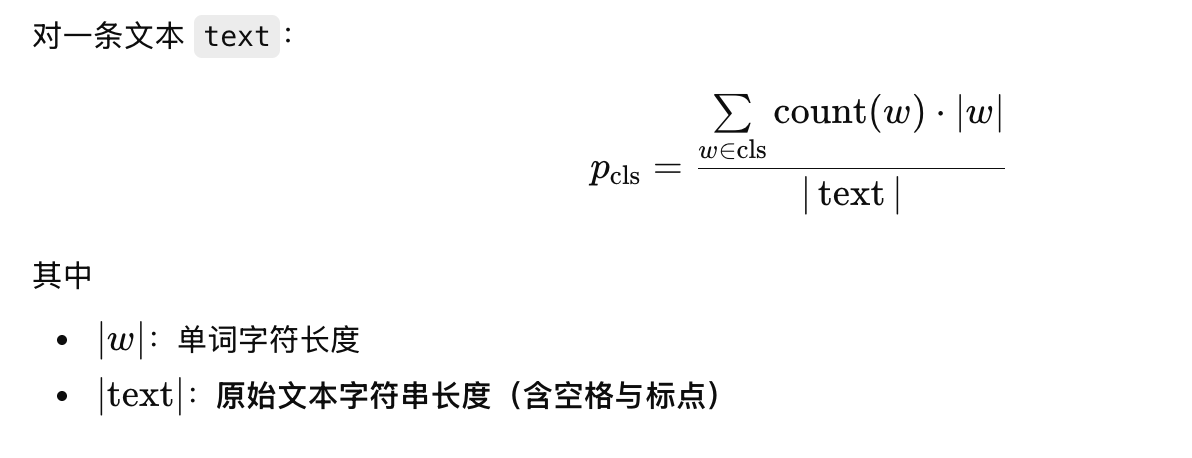

low / mid / high：只对 纯字母词（英文单词）做 Zipf 分类

punct：中英文标点（以及各种符号类标点）

num_other：数字 + 其他（包含数字、混合词、中文字符、emoji、不可见字符等你不想细分的）

whitespace（空格 / 换行 / tab 等）

In [ ]:
!pip install wordfreq
import re
import unicodedata
from wordfreq import zipf_frequency

def tokenize(text):
    # 词 or 单个非空白字符（空白不会被 token 化）
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    # P*: punctuation, S*: symbol
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    # 纯字母词（英文/拉丁字母）；你也可保留 tok.isalpha()
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026 等都算“数字类”
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

def zipf_length_proportions_rawlen_6cat(text):
    """
    6类比例（总和=1）：
      low/mid/high: 纯字母词按 zipf 分类，累计 len(tok)
      punct: 标点/符号 token，累计 len(tok)
      num_other: 数字 + 其它非上述 token（含中文、混合串、emoji等），累计 len(tok)
      whitespace: 所有空白字符（isspace=True），累计字符数
    分母= len(text)（压缩算法看到的字符数）
    """
    if not isinstance(text, str) or len(text) == 0:
        return {"low": 0.0, "mid": 0.0, "high": 0.0, "punct": 0.0, "num_other": 0.0, "whitespace": 0.0}

    total_len = len(text)

    # 第6类：空白字符（包含 space/newline/tab/各种 Unicode 空白）
    whitespace_len = sum(1 for ch in text if ch.isspace())

    tokens = tokenize(text)
    num = {"low": 0, "mid": 0, "high": 0, "punct": 0, "num_other": 0, "whitespace": whitespace_len}

    for tok in tokens:
        if is_punct_token(tok):
            num["punct"] += len(tok)
        elif is_alpha_word(tok):
            cls = classify_word_zipf(tok)
            num[cls] += len(tok)
        elif is_number_like(tok):
            num["num_other"] += len(tok)
        else:
            num["num_other"] += len(tok)

    # 转成比例
    props = {k: v / total_len for k, v in num.items()}

    # （可选）数值检查：理论上应非常接近 1
    # print("sum:", sum(props.values()))

    return props


In [ ]:
df["p_zipf_stats"] = df["wiki_text"].apply(zipf_length_proportions_rawlen_6cat)

In [ ]:
df.head(10)

### *Update b_i: bertscore with only delete i

We have 6 classes. Due to the polishment is easy to change the original meaning, and for whitespace. puncutation and number_other, it doesn't change a lot of meaning, so we only use polished text for deleting low,mid, high freq and use restore text for deleting whitespace, puncutation and number_other as bertscore of only delete pi.

#### *Only delete p_i

In [ ]:
!pip install wordfreq
import re
import unicodedata
from wordfreq import zipf_frequency

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    # P*: punctuation, S*: symbol
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026 等
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

# ✅ 关键：包含 whitespace 的分段 tokenizer（不丢位置信息）
_SEG_RE = re.compile(r"\s+|\w+|[^\w\s]", flags=re.UNICODE)

def segment_class(seg: str) -> str:
    """把一个 segment 归到 6 类之一。"""
    if seg.isspace():
        return "whitespace"

    # \w+ 段：可能是英文词/数字/中文/混合
    if re.fullmatch(r"\w+", seg):
        if is_alpha_word(seg):
            return classify_word_zipf(seg)  # low/mid/high
        else:
            # 数字 / 中文 / 混合串都归 num_other
            return "num_other"

    # 单字符非空白：标点/符号/emoji 等
    if is_punct_token(seg):
        return "punct"
    return "num_other"

def delete_by_class(text: str, cls_to_delete: str) -> str:
    """
    只删除指定类别的 segments，返回新文本。
    cls_to_delete in: {"low","mid","high","punct","num_other","whitespace"}
    """
    if not isinstance(text, str) or len(text) == 0:
        return text

    out = []
    for seg in _SEG_RE.findall(text):
        if segment_class(seg) == cls_to_delete:
            continue
        out.append(seg)
    return "".join(out)

def delete_variants_6cat(text: str) -> dict:
    """一次性生成 6 个版本：分别只删除某一类。"""
    classes = ["low", "mid", "high", "punct", "num_other", "whitespace"]
    return {f"del_{c}": delete_by_class(text, c) for c in classes}


classes = ["low", "mid", "high", "punct", "num_other", "whitespace"]

for c in classes:
    df[f"delete_{c}"] = df["wiki_text"].apply(lambda x: delete_by_class(x, c))


In [ ]:
i = 30
print("ORIG:\n", df["wiki_text"].iloc[i])
print("DEL_LOW:\n", df["delete_low"].iloc[i])
print("DEL_MID:\n", df["delete_mid"].iloc[i])
print("DEL_high:\n", df["delete_high"].iloc[i])


In [ ]:
df.head(4)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### V1: Without Polished

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_optimal_without_prepolish"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

#### Updated Bertscore Calculation

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"


def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()

In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)


In [ ]:
import ast

col_out = "b_zipf_stats"

# 如果列不存在，初始化
if col_out not in df.columns:
    df[col_out] = [{} for _ in range(len(df))]
else:
    # 如果已经存在，确保每一行是 dict
    def ensure_dict(x):
        if isinstance(x, dict):
            return x
        if pd.isna(x):
            return {}
        if isinstance(x, str):
            try:
                return ast.literal_eval(x)
            except:
                return {}
        return {}

    df[col_out] = df[col_out].apply(ensure_dict)

In [ ]:
ratios = ["low","mid","high","punct","num_other","whitespace"]

# 1️⃣ 初始化列为每行一个空字典
if "b_zipf_stats" not in df.columns:
    df["b_zipf_stats"] = [{} for _ in range(len(df))]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"delete_{ratio}"
    col_out = "b_zipf_stats"

    # -------- clean whole column first --------
    originals = df[col_gt].apply(clean_text).tolist()
    restoreds = df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # 2️⃣ 把当前 ratio 的 F1 写入每一行的 dict
    for i, f in enumerate(F1):
        df.at[i, col_out][ratio] = float(f)


In [ ]:
df.head(5)

### V2: with polished

#### LLM for restoration

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])


model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing English words (due to category-based deletion), missing punctuation symbols (e.g., commas, periods, hyphens), missing numeric or non-alphabetic tokens, or missing whitespace characters such as spaces, line breaks, or tabs.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()


"""
def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空
"""
def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")

            time.sleep(2 * (attempt + 1))

    return corrupted_text


cols_to_restore = ["delete_low","delete_mid","delete_high","delete_punct", "delete_num_other", "delete_whitespace"]



for col in cols_to_restore:
    curr_col=col.split("delete_")[1]
    output_col = f"restored_delete_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)


        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### LLM for polishment


这里只polish low/mid/high freq

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()


def build_prompt_updated(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Improve fluency and readability by smoothing awkward wording while largely preserving the original phrasing and sentence structure.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.
- Prefer minimal edits over rewriting.

Restored Text:
{input_text}

Polished Output:
""".strip()


# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    #prompt = build_prompt(corrupted_text)
    prompt = build_prompt_updated(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑

cols_to_restore = ["restored_delete_low","restored_delete_mid","restored_delete_high"]
#

for col in cols_to_restore:
    curr_suffix = col.split("restored_delete_")[1]
    output_col = f"polished_delete_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        if df.at[idx, output_col]:
            continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### Bertscore calculation

In [ ]:
import re
from bert_score import score as bertscore
from nltk import sent_tokenize
import logging

MODEL = "distilroberta-base"

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)

# 初始化列
df["b_zipf_stats"] = [dict() for _ in range(len(df))]

# 列映射
col_map = {
    "low": "polished_delete_low",
    "mid": "polished_delete_mid",
    "high": "polished_delete_high",
    "punct": "restored_delete_punct",
    "num_other": "restored_delete_num_other",
    "whitespace": "restored_delete_whitespace",
}

# =========================
# 1️⃣ 收集所有 pairs
# =========================
pairs = []   # [(cand, ref)]
meta = []    # [(row_idx, suffix)]

for idx in range(len(df)):
    print(f"Collecting row {idx}")

    original = df.at[idx, "wiki_text"]

    if not isinstance(original, str) or len(original.strip()) == 0:
        continue

    for suffix, col in col_map.items():
        if col not in df.columns:
            continue

        cand = df.at[idx, col]

        if not isinstance(cand, str) or len(cand.strip()) == 0:
            continue

        pairs.append((cand, original))
        meta.append((idx, suffix))

# =========================
# 2️⃣ 构造 batch 输入
# =========================
cands = [p[0] for p in pairs]
refs  = [p[1] for p in pairs]

print(f"Total pairs: {len(cands)}")

# =========================
# 3️⃣ 一次性 batch bertscore
# =========================
P, R, F1 = bertscore(
    cands,
    refs,
    model_type=MODEL,
    lang="en",
    batch_size=32,   # 🚀 可以调大（32 / 64 / 128）
    verbose=True
)

# =========================
# 4️⃣ 回填结果
# =========================
for i, (idx, suffix) in enumerate(meta):
    df.at[idx, "b_zipf_stats"][suffix] = float(F1[i])


In [ ]:
import ast
df["b_zipf_stats_restore"] = df["b_zipf_stats_restore"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["b_zipf_stats"] = df["b_zipf_stats"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

In [ ]:
df["b_zipf_stats"]

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### *Solve the Equation

#### ***CVX**

In [ ]:
import numpy as np
import ast
import cvxpy as cp


def extract_bp_from_df(df, row_idx, b_col="b_zipf_stats", p_col="p_zipf_stats", keys=None):
    b_dict = df[b_col].iloc[row_idx]
    if isinstance(b_dict, str):
        b_dict = ast.literal_eval(b_dict)

    p_dict = df[p_col].iloc[row_idx]
    if isinstance(p_dict, str):
        p_dict = ast.literal_eval(p_dict)

    if keys is None:
        keys = sorted(b_dict.keys())

    b = np.array([b_dict[k] for k in keys], dtype=float)
    p = np.array([p_dict[k] for k in keys], dtype=float)
    return b, p, keys


def solve_max_product_cvxpy(
    b, p, T,
    tol=None,
    mode="leq",   # "leq", "band", "lower_band"
    eps=1e-12,
    solver="ECOS",
    verbose=False
):
    """
    Solve:
        max Π_i [1 - (1-b_i) w_i]

    Modes:
        "leq"        → Σ p_i(1-w_i) <= T
        "band"       → T - tol <= Σ p_i(1-w_i) <= T + tol
        "lower_band" → T - tol <= Σ p_i(1-w_i) <= T
    """

    b = np.asarray(b, dtype=float)
    p = np.asarray(p, dtype=float)
    a = 1.0 - b
    n = len(b)

    w = cp.Variable(n)

    t = 1 - cp.multiply(a, w)
    constraint_expr = cp.sum(cp.multiply(p, 1 - w))

    constraints = [
        w >= 0,
        w <= 1,
        t >= eps,   # avoid log(0)
    ]

    # =========================
    # 约束逻辑
    # =========================
    if mode == "band":                 # T ± tol
        constraints.append(constraint_expr >= T - tol)
        constraints.append(constraint_expr <= T + tol)

    elif mode == "lower_band":         # T - tol ≤ expr ≤ T
        constraints.append(constraint_expr >= T - tol)
        constraints.append(constraint_expr <= T)

    else:                              # 原始 ≤ T
        constraints.append(constraint_expr <= T)

    # =========================

    objective = cp.Maximize(cp.sum(cp.log(t)))
    prob = cp.Problem(objective, constraints)

    if solver.upper() == "ECOS":
        prob.solve(
            solver=cp.ECOS,
            verbose=verbose,
            abstol=1e-12,
            reltol=1e-12,
            feastol=1e-12,
            max_iters=2000
        )
    elif solver.upper() == "SCS":
        prob.solve(
            solver=cp.SCS,
            verbose=verbose,
            eps=1e-6,
            max_iters=200000
        )
    elif solver.upper() == "CLARABEL":
        prob.solve(solver=cp.CLARABEL, verbose=verbose)
    else:
        prob.solve(verbose=verbose)

    w_star = np.array(w.value).astype(float)

    prod_obj = float(np.prod(1.0 - a * w_star))
    cons_val = float(np.sum(p * (1.0 - w_star)))

    return w_star, {
        "objective_product": prod_obj,
        "objective_logsum": float(np.sum(np.log(np.maximum(1.0 - a * w_star, 1e-300)))),
        "constraint_value": cons_val,
        "diff": cons_val - T,
        "status": prob.status
    }


# ============================================
# 主循环
# ============================================

df["w_optimal_cvx"] = [dict() for _ in range(len(df))]
df["w_info_cvx"] = [dict() for _ in range(len(df))]

for i in range(len(df)):
    print("No", i)

    b, p, keys = extract_bp_from_df(
        df,
        i,
        b_col="b_zipf_stats",
        p_col="p_zipf_stats",
        keys=["low", "mid", "high", "punct", "num_other", "whitespace"]
    )

    T_items = [
        ("0.9", 0.9),
        ("0.8", 0.8),
        ("lz4",  float(df.at[i, "lz4_ratio"])),
        ("0.7", 0.7),
        ("0.6", 0.6),
        ("lzma", float(df.at[i, "lzma_ratio"])),
        ("0.5", 0.5),
        ("gzip", float(df.at[i, "gzip_ratio"])),
        ("0.4", 0.4),
        ("0.3", 0.3),
        ("0.2", 0.2),
        ("0.1", 0.1),
    ]

    for label, t in T_items:

        # 30 / 20 / 10 → ±0.02
        if label in ["0.3", "0.2", "0.1"]:
            w_star, info = solve_max_product_cvxpy(
                b, p, t,
                tol=0.02,
                mode="band",
                solver="CLARABEL",
                verbose=False
            )
        else:
            # 其他 → 只允许 -0.02
            w_star, info = solve_max_product_cvxpy(
                b, p, t,
                tol=0.02,
                mode="lower_band",
                solver="CLARABEL",
                verbose=False
            )

        df.at[i, "w_optimal_cvx"][label] = w_star.tolist()
        df.at[i, "w_info_cvx"][label] = info

In [ ]:
df.head(5)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Experimental Evaulation

### *Dataset Processing

#### *w distribution with polished processing

In [ ]:
# Orig============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_optimal"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
# original============================================================
# Full pipeline: 6-class segmentation + stochastic deletion by w
# Generates new df columns for each retention-rate key in w_all
# ============================================================

# If running in Colab:
!pip -q install wordfreq

import re
import unicodedata
import random
import ast
from typing import Dict, List, Any, Optional

import numpy as np
import pandas as pd
import random
from collections import defaultdict

from wordfreq import zipf_frequency

# -----------------------------
# 1) 6-class definitions
# -----------------------------
CLASSES = ["low", "mid", "high", "punct", "num_other", "whitespace"]

def classify_word_zipf(word: str) -> str:
    """Classify English alpha words into low/mid/high by Zipf frequency."""
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    """Token is punctuation/symbol if all chars are category P* or S*."""
    if not tok:
        return False
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026, etc.
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

# Keep whitespace segments to preserve position info
_SEG_RE = re.compile(r"\s+|\w+|[^\w\s]", flags=re.UNICODE)

def segment_class(seg: str) -> str:
    """
    Map a segment to one of 6 classes:
    low/mid/high (alpha words by Zipf), punct, num_other, whitespace.
    """
    if seg.isspace():
        return "whitespace"

    # \w+ could be alpha word / number / CJK / mixed
    if re.fullmatch(r"\w+", seg):
        if is_alpha_word(seg):
            return classify_word_zipf(seg)  # low/mid/high
        else:
            return "num_other"

    # non-space, non-\w: punctuation/symbol/emoji, etc.
    if is_punct_token(seg):
        return "punct"
    return "num_other"

# -----------------------------
# 2) Convert w list -> dict
# -----------------------------
def w_list_to_dict(w_list):
    return dict(zip(CLASSES, w_list))
# -----------------------------
# 3) Stochastic deletion by w
# -----------------------------

def _compute_keep_ratio(original: str, modified: str) -> float:
    return len(modified) / max(len(original), 1)

def delete_by_w_length_budget_with_target(
    text: str,
    w_dict: Dict[str, float],
    T: float,                      # 目标保留率，例如 0.9
    lower: float = 0.88,           # 允许下界
    eps: float = 1e-6,
    seed: Optional[int] = None,
) -> str:
    """
    目标：最终保留率 keep_ratio 落在 [lower, T]，并尽量贴近 T（不超过T）。
    1) 先按类长度预算删（segment级）
    2) 若 keep_ratio > T：用 whitespace 做字符级微调删到接近 T
    3) 若 keep_ratio < lower：回退到微调前文本（更保守）
    """
    if not isinstance(text, str) or len(text) == 0:
        return text

    rng = random.Random(seed)
    segs = _SEG_RE.findall(text)

    class_items = defaultdict(list)
    for idx, seg in enumerate(segs):
        cls = segment_class(seg)
        class_items[cls].append((idx, seg, len(seg)))

    to_delete = set()

    for cls, items in class_items.items():
        w = float(w_dict.get(cls, 0.0))
        w = max(0.0, min(1.0, w))
        if w == 0.0:
            continue

        total_len = sum(l for _, _, l in items)
        target_del_len = w * total_len

        rng.shuffle(items)

        acc = 0
        for idx, seg, l in items:
            if acc >= target_del_len:
                break
            to_delete.add(idx)
            acc += l

    # --- 重建第一次（微调前） ---
    out_before_tweak = "".join(seg for i, seg in enumerate(segs) if i not in to_delete)
    keep_ratio = _compute_keep_ratio(text, out_before_tweak)

    out = out_before_tweak

    # --- 如果保留率 > T：删少了，用 whitespace 字符级补刀 ---
    if keep_ratio > T + eps:
        target_len = int(round(T * len(text)))
        need_del_chars = len(out) - target_len  # 需要再删掉的字符数（尽量从空白删）
        if need_del_chars > 0:
            out_chars = list(out)
            removed = 0
            for j in range(len(out_chars) - 1, -1, -1):
                if removed >= need_del_chars:
                    break
                if out_chars[j].isspace():
                    out_chars[j] = ""
                    removed += 1
            out = "".join(out_chars)

    # --- 保底：如果删过头，回退到微调前 ---
    keep_ratio_after = _compute_keep_ratio(text, out)
    if keep_ratio_after < lower - eps:
        return out_before_tweak

    return out


def ensure_w_dict(x):
    """df 单元格可能是 dict / str(dict) / [dict]，统一转成 dict"""
    if isinstance(x, dict):
        return x
    if isinstance(x, list) and len(x) == 1 and isinstance(x[0], dict):
        return x[0]
    if isinstance(x, str):
        y = ast.literal_eval(x)
        if isinstance(y, dict):
            return y
        if isinstance(y, list) and len(y) == 1 and isinstance(y[0], dict):
            return y[0]
    raise TypeError(f"Unsupported w format: {type(x)}")

def key_to_colname(prefix: str, key: str) -> str:
    """'0.9'->optimal_del_90, 'lz4'->optimal_del_lz4"""
    try:
        T = float(key)
        return f"{prefix}_{int(round(T*100))}"
    except:
        return f"{prefix}_{str(key)}"

def apply_optimal_del_columns_mixed_keys(
    df: pd.DataFrame,
    text_col: str = "wiki_text",
    w_col: str = "w_optimal_cvx",
    prefix: str = "optimal_keep",
    band: float = 0.02,
    base_seed: int = 123,
    compressor_T_cols: dict = None,   # e.g. {"lz4":"lz4_ratio","lzma":"lzma_ratio","gzip":"gzip_ratio"}
) -> pd.DataFrame:
    """
    对 df 每行：
      - 数值 key: T=float(key)
      - compressor key: T=df[对应ratio列] 的逐行值
    每个 key 生成单独一列。
    """
    if compressor_T_cols is None:
        compressor_T_cols = {"lz4": "lz4_ratio", "lzma": "lzma_ratio", "gzip": "gzip_ratio"}

    # 1) 收集全表所有 key（来自 w_col）
    all_keys = set()
    for x in df[w_col]:
        if x is None or (isinstance(x, float) and np.isnan(x)):
            continue
        w_all = ensure_w_dict(x)
        all_keys.update(w_all.keys())

    # 2) 拆分：数值 key + compressor key
    numeric_keys = []
    comp_keys = []

    for k in all_keys:
        ks = str(k)
        if ks in compressor_T_cols:
            comp_keys.append(ks)
        else:
            try:
                float(ks)
                numeric_keys.append(ks)
            except:
                # 其他非数值、非 compressor 的 key（如果未来有）先忽略
                pass

    numeric_keys = sorted(numeric_keys, key=lambda x: float(x), reverse=True)
    comp_keys = sorted(comp_keys)  # lz4/gzip/lzma 顺序随意，你也可自定义

    # 3) 先做数值 key（T固定 = float(key)）
    for key in numeric_keys:
        T_fixed = float(key)
        col = key_to_colname(prefix, key)

        out = []
        lower_fixed = max(0.0, T_fixed - band)

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_length_budget_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=T_fixed,
                    lower=lower_fixed,
                    seed=seed
                )
            )
        df[col] = out

    # 4) 再做 compressor key（T逐行取 df[ratio_col]）
    for key in comp_keys:
        ratio_col = compressor_T_cols[key]
        if ratio_col not in df.columns:
            raise KeyError(f"Missing ratio column '{ratio_col}' for key '{key}'")

        col = key_to_colname(prefix, key)
        out = []

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            # 逐行 T
            T_i = float(df[ratio_col].iloc[i])
            # 安全剪裁到 [0,1]
            T_i = max(0.0, min(1.0, T_i))
            lower_i = max(0.0, T_i - band)

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_length_budget_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=T_i,
                    lower=lower_i,
                    seed=seed
                )
            )
        df[col] = out

    return df



df = apply_optimal_del_columns_mixed_keys(
    df,
    text_col="wiki_text",
    w_col="w_optimal_cvx",
    prefix="optimal_keep",
    band=0.02,
    compressor_T_cols={"lz4":"lz4_ratio", "lzma":"lzma_ratio", "gzip":"gzip_ratio"}
)

In [ ]:
df.head(5)

#### ***w distribution with without prepolish**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_optimal_without_prepolish"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
# v============================================================
# Character-level 6-class stochastic deletion by w
# + Global minimum retention guarantee
# ============================================================
## soft
# If running in Colab:
!pip -q install wordfreq

import re
import unicodedata
import random
import ast
from typing import Dict, Optional

import numpy as np
import pandas as pd
from collections import defaultdict
from wordfreq import zipf_frequency


# -----------------------------
# 1) 6-class definitions
# -----------------------------

CLASSES = ["low", "mid", "high", "punct", "num_other", "whitespace"]

def classify_word_zipf(word: str) -> str:
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    return tok.isalpha()

_SEG_RE = re.compile(r"\s+|\w+|[^\w\s]", flags=re.UNICODE)

def segment_class(seg: str) -> str:
    if seg.isspace():
        return "whitespace"

    if re.fullmatch(r"\w+", seg):
        if is_alpha_word(seg):
            return classify_word_zipf(seg)
        else:
            return "num_other"

    if is_punct_token(seg):
        return "punct"

    return "num_other"


# -----------------------------
# 2) Convert w list -> dict
# -----------------------------

def w_list_to_dict(w_list):
    return dict(zip(CLASSES, w_list))

def ensure_w_dict(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, list) and len(x) == 1 and isinstance(x[0], dict):
        return x[0]
    if isinstance(x, str):
        y = ast.literal_eval(x)
        if isinstance(y, dict):
            return y
        if isinstance(y, list) and isinstance(y[0], dict):
            return y[0]
    raise TypeError(f"Unsupported w format: {type(x)}")

def key_to_colname(prefix: str, key: str) -> str:
    try:
        T = float(key)
        return f"{prefix}_{int(round(T*100))}"
    except:
        return f"{prefix}_{str(key)}"


# -----------------------------
# 3) Character-level deletion (with minimum retention)
# -----------------------------

def delete_by_w_char_level_with_target(
    text: str,
    w_dict: Dict[str, float],
    T: float,
    lower: float,
    seed: Optional[int] = None,
) -> str:

    if not isinstance(text, str) or len(text) == 0:
        return text

    rng = random.Random(seed)

    segs = _SEG_RE.findall(text)
    full_text = "".join(segs)
    N = len(full_text)
    if N == 0:
        return text

    # ===============================
    # 1️⃣ 构建每个字符的类别
    # ===============================
    char_classes = []
    for seg in segs:
        cls = segment_class(seg)
        char_classes.extend([cls] * len(seg))

    # 定义语义类别（🔥核心修改）
    semantic_classes = {"low", "mid", "high","num_other"}

    class_indices = defaultdict(list)
    for idx, cls in enumerate(char_classes):
        class_indices[cls].append(idx)

    # ===============================
    # 2️⃣ 严格按 w 删除（第一阶段）
    # ===============================
    to_delete = set()

    for cls, indices in class_indices.items():
        w = float(w_dict.get(cls, 0.0))
        w = max(0.0, min(1.0, w))

        if w <= 0:
            continue

        Lc = len(indices)
        delete_count = int(round(w * Lc))
        delete_count = min(delete_count, Lc)

        tmp = indices.copy()
        rng.shuffle(tmp)
        to_delete.update(tmp[:delete_count])

    # ===============================
    # 3️⃣ 区间控制参数
    # ===============================
    lower = max(0.0, min(1.0, lower))
    T = max(0.0, min(1.0, T))
    if lower > T:
        lower, T = T, lower

    min_keep = int(np.ceil(lower * N))
    max_keep = int(np.floor(T * N))

    min_keep = max(1, min_keep)
    max_keep = max(min_keep, max_keep)

    def keep_len():
        return N - len(to_delete)

    # ===============================
    # 4️⃣ 如果删太多 → 恢复（优先恢复语义字符）
    # ===============================
    while keep_len() < min_keep:

        deleted_indices = list(to_delete)
        if not deleted_indices:
            break

        semantic_deleted = [
            i for i in deleted_indices
            if char_classes[i] in semantic_classes
        ]

        candidates = semantic_deleted if semantic_deleted else deleted_indices

        idx = rng.choice(candidates)
        to_delete.remove(idx)

    # ===============================
    # 5️⃣ 如果删太少 → 再删（优先删非语义字符）
    # ===============================
    while keep_len() > max_keep:

        kept_indices = [i for i in range(N) if i not in to_delete]
        if not kept_indices:
            break

        non_semantic_kept = [
            i for i in kept_indices
            if char_classes[i] not in semantic_classes
        ]

        candidates = non_semantic_kept if non_semantic_kept else kept_indices

        idx = rng.choice(candidates)
        to_delete.add(idx)

    # ===============================
    # 6️⃣ 防止“只剩符号”情况
    # ===============================
    semantic_count = sum(
        char_classes[i] in semantic_classes
        for i in range(N)
        if i not in to_delete
    )

    if semantic_count == 0:

        deleted_indices = list(to_delete)
        semantic_deleted = [
            i for i in deleted_indices
            if char_classes[i] in semantic_classes
        ]

        if semantic_deleted:
            idx = rng.choice(semantic_deleted)
            to_delete.remove(idx)

    # ===============================
    # 7️⃣ 构建输出
    # ===============================
    out = "".join(
        ch for i, ch in enumerate(full_text) if i not in to_delete
    )

    return out

# -----------------------------
# 4) Apply to DataFrame
# -----------------------------

def apply_optimal_del_columns_mixed_keys(
    df: pd.DataFrame,
    text_col: str = "wiki_text",
    w_col: str = "w_optimal_cvx",
    prefix: str = "optimal_keep",
    band: float = 0.02,
    base_seed: int = 123,
    compressor_T_cols: dict = None,
):

    if compressor_T_cols is None:
        compressor_T_cols = {
            "lz4": "lz4_ratio",
            "lzma": "lzma_ratio",
            "gzip": "gzip_ratio"
        }

    all_keys = set()
    for x in df[w_col]:
        if x is None:
            continue
        w_all = ensure_w_dict(x)
        all_keys.update(w_all.keys())

    numeric_keys = []
    comp_keys = []

    for k in all_keys:
        ks = str(k)
        if ks in compressor_T_cols:
            comp_keys.append(ks)
        else:
            try:
                float(ks)
                numeric_keys.append(ks)
            except:
                pass

    numeric_keys = sorted(numeric_keys, key=lambda x: float(x), reverse=True)
    comp_keys = sorted(comp_keys)

    # -------- numeric keys --------
    for key in numeric_keys:
        T_fixed = float(key)
        col = key_to_colname(prefix, key)

        out = []

        """
        if key in ["0.3", "0.2", "0.1"]:
            lower = max(0.0, T_fixed - band)
            upper = min(1.0, T_fixed + band)
        else:
            lower = max(0.0, T_fixed - band)
            upper = T_fixed

        """

        lower = max(0.0, T_fixed - band)
        upper = T_fixed

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_char_level_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=upper,
                    lower=lower,
                    seed=seed
                )
            )

        df[col] = out

    # -------- compressor keys --------
    for key in comp_keys:
        ratio_col = compressor_T_cols[key]
        col = key_to_colname(prefix, key)

        out = []

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            T_i = float(df[ratio_col].iloc[i])
            T_i = max(0.0, min(1.0, T_i))
            lower = max(0.0, T_i - band)

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_char_level_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=T_i,
                    lower=lower,
                    seed=seed
                )
            )

        df[col] = out

    return df


# -----------------------------
# Run
# -----------------------------

df = apply_optimal_del_columns_mixed_keys(
    df,
    text_col="wiki_text",
    w_col="w_optimal_cvx",
    prefix="optimal_keep",
    band=0.02,
    compressor_T_cols={
        "lz4": "lz4_ratio",
        "lzma": "lzma_ratio",
        "gzip": "gzip_ratio"
    }
)

In [ ]:
df.head(10)

In [ ]:
base_keep_levels = {
    "90": 0.90,
    "80": 0.80,
    "70": 0.70,
    "60": 0.60,
    "50": 0.50,
    "40": 0.40,
    "30": 0.30,
    "20": 0.20,
    "10": 0.10
}

for idx in df.index:
  print(idx)
  for key, keep in base_keep_levels.items():
    original_text = df.at[idx, "wiki_text"]
    modified_result=str(df.at[idx, f"optimal_keep_{key}"])
    print("actual_keep_ratio",len(modified_result) / len(original_text), "anticipated keep",keep)

### Char_restoration and polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    return f"""
You are a linguistic reconstruction and refinement model.

Your task is to recover and polish a corrupted text into fluent, natural, and grammatically correct English.

The input may contain missing letters or numbers, punctuation errors, missing short words, or partially deleted content, etc.

### Core Requirements:

1. **Faithful Reconstruction:**
   - Restore the text to its closest original form.
   - Do NOT paraphrase or introduce new meaning.
   - Only recover missing or corrupted parts.

2. **Fluency & Readability:**
   - Ensure the output is smooth, natural, and human-readable.
   - Fix grammatical issues and awkward phrasing caused by corruption.

3. **Structural Preservation (Strict):**
   - Maintain **1:1 sentence correspondence** (no merging or splitting).
   - Preserve the original order and structure exactly.
   - This is critical for alignment-based evaluation.

4. **Semantic Integrity & Zero Hallucination:**
   - Do not add, remove, or speculate any information.
   - If content is ambiguous, improve grammar without inventing meaning.

### Output Policy:
- Return ONLY the final reconstructed and polished text.
- No explanations or meta text.

Input:
{input_text}

Output:
""".strip()


def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")

            time.sleep(2 * (attempt + 1))

    return corrupted_text

# 4. 主循环逻辑

cols_to_restore = ["optimal_keep_10"]
 #[ "optimal_keep_30","optimal_keep_20","optimal_keep_10",
 #                  "optimal_keep_90","optimal_keep_80",
 #                  "optimal_keep_lz4","optimal_keep_70",
 #                  "optimal_keep_60","optimal_keep_lzma",
 #                  "optimal_keep_50","optimal_keep_gzip",
 #                  "optimal_keep_40"]

for col in cols_to_restore:
    curr_suffix = col.split("optimal_keep_")[1]
    output_col = f"polished_optimal_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    #
    # ⛔ 跳过已经处理过的行（断点续跑）
    #    if df.at[idx, output_col]:
     #      continue
        corrupted = df.at[idx, col]
        result = restore_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
df.head(3)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>" #"<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric performance

### Updated quick bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"


def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = scorer.score(hyp_list, ref_list)
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:
df["polished_bert_chunk"] = None
df["polished_bert_sentence"] = None

polished_optimal_text_cols =["polished_optimal_90", "polished_optimal_80", "polished_optimal_70", "polished_optimal_60",
   "polished_optimal_lz4", "polished_optimal_lzma", "polished_optimal_gzip","polished_optimal_50",
    "polished_optimal_40", "polished_optimal_30", "polished_optimal_20", "polished_optimal_10"]

In [ ]:
df["polished_bert_chunk"] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_optimal_{ratio}"

    originals = df[col_gt].apply(clean_text).tolist()
    restoreds = df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- 🔥 存入 dict（关键修改）--------
    for i, (p, r, f) in enumerate(zip(P, R, F1)):
        df.at[i, "polished_bert_chunk"][col_pred] = {
            "P": float(p),
            "R": float(r),
            "F1": float(f)
        }

In [ ]:
col_out = "polished_bert_sentence"

df[col_out] = [{} for _ in range(len(df))]

ratios = [90, 80, "lz4", 70, "lzma", 60, "gzip", 50, 40, 30, 20, 10]

for ratio in ratios:
    print(f"Processing ratio {ratio}")

    col_gt = "wiki_text"
    col_pred = f"polished_optimal_{ratio}"

    all_refs = []
    all_hyps = []
    row_map = []

    # ===============================
    # 1️⃣ Collect sentences
    # ===============================
    for idx in range(len(df)):
        original = clean_text(df.at[idx, col_gt])
        restored = clean_text(df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
        all_hyps,
        all_refs,
        model_type=MODEL,
        lang="en",
        verbose=False,
        batch_size=64
    )

    # ===============================
    # 3️⃣ Aggregate per row
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    # ===============================
    # 4️⃣ 🔥 写入 dict（关键）
    # ===============================
    for idx in range(len(df)):
        df.at[idx, col_out][col_pred] = row_sentence_scores[idx]

In [ ]:
import numpy as np
import pandas as pd

ratios = [90, 80, "lz4", 70,  60, "lzma", "gzip", 50, 40, 30, 20, 10]

rows = [
    "P_chunk_mean", "P_chunk_std",
    "R_chunk_mean", "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",
    "P_sent_mean", "P_sent_std",
    "R_sent_mean", "R_sent_std",
    "F1_sent_mean", "F1_sent_std"
]

summary = pd.DataFrame(index=rows, columns=ratios)

for ratio in ratios:

    key = f"polished_optimal_{ratio}"

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    chunk_scores = [
        d.get(key)
        for d in df["polished_bert_chunk"]
        if isinstance(d, dict) and key in d
    ]

    if len(chunk_scores) == 0:
        continue

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level
    # =========================
    sent_lists = [
        d.get(key)
        for d in df["polished_bert_sentence"]
        if isinstance(d, dict) and key in d
    ]

    all_sent_scores = [
        s
        for sent_list in sent_lists
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # 写入（关键）
    # =========================
    summary.loc["P_chunk_mean", ratio] = P_chunk.mean()
    summary.loc["P_chunk_std",  ratio] = P_chunk.std()

    summary.loc["R_chunk_mean", ratio] = R_chunk.mean()
    summary.loc["R_chunk_std",  ratio] = R_chunk.std()

    summary.loc["F1_chunk_mean", ratio] = F1_chunk.mean()
    summary.loc["F1_chunk_std",  ratio] = F1_chunk.std()

    summary.loc["P_sent_mean", ratio] = P_sent.mean()
    summary.loc["P_sent_std",  ratio] = P_sent.std()

    summary.loc["R_sent_mean", ratio] = R_sent.mean()
    summary.loc["R_sent_std",  ratio] = R_sent.std()

    summary.loc["F1_sent_mean", ratio] = F1_sent.mean()
    summary.loc["F1_sent_std",  ratio] = F1_sent.std()

summary

### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer


restore_cols = ["polished_optimal_90","polished_optimal_80","polished_optimal_lz4","polished_optimal_70","polished_optimal_60","polished_optimal_lzma",
              "polished_optimal_gzip","polished_optimal_50","polished_optimal_40","polished_optimal_30","polished_optimal_20","polished_optimal_10"]
restore_suffixes = [c.replace("polished_optimal_", "") for c in restore_cols]

df["cer"] = None
df["wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "wiki_text"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_optimal_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict



In [ ]:
import ast
import numpy as np
summary_cer = pd.DataFrame(index=["cer_mean", "cer_std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["wer_mean", "wer_std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "cer"]
        if isinstance(cer_dict, str):
            cer_dict = ast.literal_eval(cer_dict)

        wer_dict = df.at[idx, "wer"]
        if isinstance(wer_dict, str):
            wer_dict = ast.literal_eval(wer_dict)

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["cer_mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["cer_std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["wer_mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["wer_std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
summary_cer

In [ ]:
summary

In [ ]:
summary.columns = summary.columns.astype(str)
summary_wer.columns = summary_wer.columns.astype(str)
summary_cer.columns = summary_cer.columns.astype(str)
summary_new = pd.concat([summary, summary_wer, summary_cer], axis=0)
summary_new

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("wf_optimal_stats_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="wf_optimal_stats_result", rows="300", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(
    wks,
    summary_new,
    include_index=True  # 👈 关键
)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for restoration

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])


model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing English words (due to category-based deletion), missing punctuation symbols (e.g., commas, periods, hyphens), missing numeric or non-alphabetic tokens, or missing whitespace characters such as spaces, line breaks, or tabs.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()



def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")
            #time.sleep(2)
            time.sleep(2 * (attempt + 1))

    return corrupted_text


cols_to_restore = ["optimal_keep_fine_50","optimal_keep_fine_40"]


#cols_to_restore = ["optimal_keep_fine_10","optimal_keep_fine_20","optimal_keep_fine_30",
#                 "optimal_keep_fine_90","optimal_keep_fine_80","optimal_keep_fine_lz4",
#                   "optimal_keep_fine_70", "optimal_keep_fine_60","optimal_keep_fine_lzma",
#                   "optimal_keep_fine_gzip","optimal_keep_fine_50","optimal_keep_fine_40"]



for col in cols_to_restore:
    curr_col=col.split("optimal_keep_fine_")[1]
    output_col = f"restored_optimal_keep_fine_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    #df[output_col] = ""

    for idx in range(len(df)):

        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)


        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for polishment



In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()


def build_prompt_updated(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Improve fluency and readability by smoothing awkward wording while largely preserving the original phrasing and sentence structure.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.
- Prefer minimal edits over rewriting.

Restored Text:
{input_text}

Polished Output:
""".strip()


# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)
    #prompt = build_prompt_updated(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑

cols_to_restore = [ "restored_optimal_keep_fine_30","restored_optimal_keep_fine_20","restored_optimal_keep_fine_10",
                   "restored_optimal_keep_fine_90","restored_optimal_keep_fine_80",
                   "restored_optimal_keep_fine_lz4","restored_optimal_keep_fine_70",
                   "restored_optimal_keep_fine_60","restored_optimal_keep_fine_lzma",
                   "restored_optimal_keep_fine_50","restored_optimal_keep_fine_gzip",
                   "restored_optimal_keep_fine_40"]
#cols_to_restore = ["restored_optimal_keep_fine_70"]

for col in cols_to_restore:
    curr_suffix = col.split("restored_optimal_keep_fine_")[1]
    output_col = f"polished_optimal_keep_fine_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    #
    # ⛔ 跳过已经处理过的行（断点续跑）
    #    if df.at[idx, output_col]:
    #        continue
        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Bertscore calculation

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"


def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()

In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)


In [ ]:
ratios = [
    "90", "80", "lz4",
    "70", "60", "lzma",
    "50", "gzip",
    "40", "30", "20", "10"
]



# 先初始化一列空 dict（每行一个）
df["bert_chunk"] = [{} for _ in range(len(df))]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = "Articles"
    col_pred = f"polished_optimal_keep_fine_{ratio}"

    originals = df[col_gt].apply(clean_text).tolist()
    restoreds = df[col_pred].apply(clean_text).tolist()

    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # 每一行往 dict 里添加一个 key
    for i, (p, r, f) in enumerate(zip(P, R, F1)):

        #key_name = f"polished_optimal_keep_{ratio}"

        df.at[i, "bert_chunk"][col_pred] = {
            "P": float(p),
            "R": float(r),
            "F1": float(f)
        }

In [ ]:
ratios = [
    "90", "80", "lz4",
    "70", "60", "lzma",
    "50", "gzip",
    "40", "30", "20", "10"
]

# 初始化嵌套 dict 列
df["bert_sentence"] = [{} for _ in range(len(df))]

# 提前清洗 ground truth（避免重复算）
originals_clean = df["Articles"].apply(clean_text).tolist()

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_pred = f"polished_optimal_keep_fine_{ratio}"

    all_refs = []
    all_hyps = []
    row_map = []

    # ===============================
    # 1️⃣ 收集所有句子
    # ===============================
    for idx in range(len(df)):

        original = originals_clean[idx]
        restored = clean_text(df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ 批量 Sentence-level BERTScore
    # ===============================
    P, R, F1 = bertscore(
        all_hyps,
        all_refs,
        model_type=MODEL,
        lang="en",
        verbose=False,
        batch_size=64
    )

    # ===============================
    # 3️⃣ 还原 per-row 结构
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    # ===============================
    # 4️⃣ 存入嵌套 dict
    # ===============================
    key_name = col_pred

    for idx in range(len(df)):
        df.at[idx, "bert_sentence"][key_name] = row_sentence_scores[idx]

In [ ]:
import numpy as np
import pandas as pd

ratios = [
    "90", "80", "lz4",
    "70", "60", "lzma",
    "50", "gzip",
    "40", "30", "20", "10"
]

rows = [
    "P_chunk", "R_chunk", "F1_chunk",
    "P_sent", "R_sent", "F1_sent"
]

summary = pd.DataFrame(index=rows)

for ratio in ratios:

    key_name = f"polished_optimal_keep_fine_{ratio}"

    # =========================
    # 1️⃣ Chunk-level (from nested dict)
    # =========================
    chunk_scores = []

    for row_dict in df["bert_chunk"]:
        if key_name in row_dict:
            chunk_scores.append(row_dict[key_name])

    if len(chunk_scores) > 0:
        P_chunk = np.array([c["P"] for c in chunk_scores])
        R_chunk = np.array([c["R"] for c in chunk_scores])
        F1_chunk = np.array([c["F1"] for c in chunk_scores])
    else:
        P_chunk = R_chunk = F1_chunk = np.array([np.nan])

    # =========================
    # 2️⃣ Sentence-level (flatten)
    # =========================
    all_sent_scores = []

    for row_dict in df["bert_sentence"]:
        if key_name in row_dict:
            sent_list = row_dict[key_name]
            if sent_list:
                all_sent_scores.extend(sent_list)

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # Store
    # =========================
    summary[f"ratio_{ratio}_mean"] = [
        P_chunk.mean(),
        R_chunk.mean(),
        F1_chunk.mean(),
        P_sent.mean(),
        R_sent.mean(),
        F1_sent.mean()
    ]

    summary[f"ratio_{ratio}_std"] = [
        P_chunk.std(),
        R_chunk.std(),
        F1_chunk.std(),
        P_sent.std(),
        R_sent.std(),
        F1_sent.std()
    ]

summary

In [ ]:
import numpy as np
import pandas as pd

ratios = [
    "90", "80", "lz4",
    "70", "60", "lzma",
    "gzip", "50",
    "40", "30", "20", "10"
]

# 行顺序（完全按照你截图）
rows = [
    "P_chunk_mean", "P_chunk_std",
    "R_chunk_mean", "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",
    "P_sent_mean", "P_sent_std",
    "R_sent_mean", "R_sent_std",
    "F1_sent_mean", "F1_sent_std",
]

summary = pd.DataFrame(index=rows)

for ratio in ratios:

    key_name = f"polished_optimal_keep_fine_{ratio}"
    col_name = f"polished_{ratio}"

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    chunk_scores = []

    for row_dict in df["bert_chunk"]:
        if key_name in row_dict:
            chunk_scores.append(row_dict[key_name])

    if chunk_scores:
        P_chunk = np.array([c["P"] for c in chunk_scores])
        R_chunk = np.array([c["R"] for c in chunk_scores])
        F1_chunk = np.array([c["F1"] for c in chunk_scores])
    else:
        P_chunk = R_chunk = F1_chunk = np.array([np.nan])

    # =========================
    # 2️⃣ Sentence-level (micro)
    # =========================
    all_sent_scores = []

    for row_dict in df["bert_sentence"]:
        if key_name in row_dict:
            sent_list = row_dict[key_name]
            if sent_list:
                all_sent_scores.extend(sent_list)

    if all_sent_scores:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # 存入 summary
    # =========================
    summary[col_name] = [
        P_chunk.mean(), P_chunk.std(),
        R_chunk.mean(), R_chunk.std(),
        F1_chunk.mean(), F1_chunk.std(),
        P_sent.mean(), P_sent.std(),
        R_sent.mean(), R_sent.std(),
        F1_sent.mean(), F1_sent.std(),
    ]

summary

In [ ]:
df.head(10)

**CER/WER**

In [ ]:
!pip install jiwer

from jiwer import cer, wer

ratios = [
    "90", "80", "lz4",
    "70", "60", "lzma",
    "gzip", "50",
    "40", "30", "20", "10"
]

# 初始化
df["cer"] = [{} for _ in range(len(df))]
df["wer"] = [{} for _ in range(len(df))]

for idx in df.index:

    print(f"Processing row {idx}")

    cer_dict = {}
    wer_dict = {}

    gt = df.at[idx, "Articles"]

    if not isinstance(gt, str):
        continue

    for r in ratios:

        pred_col = f"polished_optimal_keep_fine_{r}"

        if pred_col not in df.columns:
            continue

        pred = df.at[idx, pred_col]

        if isinstance(pred, str):

            try:
                cer_dict[r] = cer(gt, pred)
                wer_dict[r] = wer(gt, pred)
            except:
                cer_dict[r] = np.nan
                wer_dict[r] = np.nan

    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict

In [ ]:
import numpy as np
import pandas as pd

ratios = [
    "90", "80", "lz4",
    "70", "60", "lzma",
    "gzip", "50",
    "40", "30", "20", "10"
]

rows = ["CER_mean", "CER_std", "WER_mean", "WER_std"]

summary_cerwer = pd.DataFrame(index=rows)

for r in ratios:

    cer_vals = []
    wer_vals = []

    for row_dict in df["cer"]:
        if r in row_dict:
            cer_vals.append(row_dict[r])

    for row_dict in df["wer"]:
        if r in row_dict:
            wer_vals.append(row_dict[r])

    if cer_vals:
        cer_mean = np.mean(cer_vals)
        cer_std = np.std(cer_vals)
    else:
        cer_mean = cer_std = np.nan

    if wer_vals:
        wer_mean = np.mean(wer_vals)
        wer_std = np.std(wer_vals)
    else:
        wer_mean = wer_std = np.nan

    summary_cerwer[f"polished_{r}"] = [
        cer_mean,
        cer_std,
        wer_mean,
        wer_std
    ]

summary_cerwer

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

In [ ]:
def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()



def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )



def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,
    )
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:
import re
import logging
from bert_score import score as bertscore
from nltk import sent_tokenize

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)
MODEL = "distilroberta-base"

df["bert_chunk"] = None
df["bert_sentence"] = None


for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in df.columns:
        if col.startswith("polished_optimal_keep"):
            polished = clean_text(df.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore  ← 使用 MODEL_CHUNK
            # --------------------------
            P, R, F1 = bertscore(
                [polished], [original],
                model_type=MODEL,   # chunk-level BERTScore
                lang="en",
                verbose=False
            )

            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

                   # --------------------------
            # 2️⃣ Sentence-level 记录句子对（还不计算）
            # --------------------------
            res_sents = sent_tokenize(polished)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算 sentence-level BERTScore
    # 使用 MODEL
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 把结果归类进每个 col
    sent_score = {col: [] for col in df.columns if col.startswith("polished_optimal_keep")}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回 DataFrame
    df.at[idx, "bert_chunk"] = chunk_dict
    df.at[idx, "bert_sentence"] = sent_score




In [ ]:
import re
import logging
import math
from bert_score import score as bertscore
from nltk import sent_tokenize

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)
MODEL = "distilroberta-base"


def is_missing(x):
    # None / NaN / 空串都算 missing
    if x is None:
        return True
    if isinstance(x, float) and math.isnan(x):
        return True
    if isinstance(x, str) and x.strip() == "":
        return True
    return False


# ❌ 不要再清空了（这是你之前结果丢失的原因）
# df["bert_chunk"] = None
# df["bert_sentence"] = None

for idx in range(148):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    if is_missing(original):
        continue

    ori_sents = sent_tokenize(original)

    # ✅ 读出已有结果（如果没有就初始化为空 dict）
    existing_chunk = df.at[idx, "bert_chunk"]
    if not isinstance(existing_chunk, dict):
        existing_chunk = {}

    existing_sentence = df.at[idx, "bert_sentence"]
    if not isinstance(existing_sentence, dict):
        existing_sentence = {}

    # 只计算“缺失的 col”
    cols_to_fill = []
    for col in df.columns:
        if col.startswith("polished_optimal_keep_70"):
            polished = clean_text(df.at[idx, col])
            if is_missing(polished):
                continue

            # ✅ 关键：只补不存在的 key（避免覆盖已有）
            if col not in existing_chunk:
                cols_to_fill.append(col)

    # 如果这行没有要补的，直接跳过
    if not cols_to_fill:
        continue

    # 你原来的 chunk_dict / sentence_dict 保留，但现在只用于“增量补全”
    chunk_dict = {}
    refs_all, hyps_all, keys_all = [], [], []

    # ---- 1) chunk-level：只对缺失 col 计算
    for col in cols_to_fill:
        polished = clean_text(df.at[idx, col])

        P, R, F1 = bertscore(
            [polished], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # ---- 2) sentence-level：收集 pair（只对缺失 col）
        res_sents = sent_tokenize(polished)
        min_len = min(len(ori_sents), len(res_sents))
        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # ---- batch 计算 sentence-level（只对缺失 col）
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 归类：只给缺失 col 建 list
    sent_score = {col: [] for col in cols_to_fill}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": float(P_list[ptr]),
            "R": float(R_list[ptr]),
            "F1": float(F1_list[ptr]),
        })
        ptr += 1

    # ✅ merge 写回：把新算的补到已有 dict 里
    existing_chunk.update(chunk_dict)
    existing_sentence.update(sent_score)

    df.at[idx, "bert_chunk"] = existing_chunk
    df.at[idx, "bert_sentence"] = existing_sentence


In [ ]:
df.head(10)

In [ ]:
import numpy as np
import pandas as pd
import ast

def parse_obj(x):
    """Parse a stringified Python literal (dict/list/...) safely."""
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except Exception:
            return np.nan  # 解析失败就标 NaN
    return x

df["bert_chunk"] = df["bert_chunk"].apply(parse_obj)
df["bert_sentence"] = df["bert_sentence"].apply(parse_obj)


restore_cols = [col for col in df.columns if col.startswith("polished_optimal_keep_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "bert_chunk"][col]
        sent_list  = df.at[idx, "bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary



#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer


restore_cols = ["polished_optimal_keep_90","polished_optimal_keep_80","polished_optimal_keep_lz4","polished_optimal_keep_70","polished_optimal_keep_60","polished_optimal_keep_lzma",
                "polished_optimal_keep_gzip","polished_optimal_keep_50","polished_optimal_keep_40","polished_optimal_keep_30","polished_optimal_keep_20","polished_optimal_keep_10"]
restore_suffixes = [c.replace("polished_optimal_keep_", "") for c in restore_cols]

df["cer"] = None
df["wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "Articles"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_optimal_keep_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict



In [ ]:
import ast
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "cer"]
        if isinstance(cer_dict, str):
            cer_dict = ast.literal_eval(cer_dict)

        wer_dict = df.at[idx, "wer"]
        if isinstance(wer_dict, str):
            wer_dict = ast.literal_eval(wer_dict)

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
summary_cer

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Summary Figure Plot

#### Dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "benchmark_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_benchmark = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_benchmark.head(5)

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "adaptive_length_deletion_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wl = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wl.head(5)

In [ ]:

# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_6classes_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wf6 = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wf6.head(5)

In [ ]:

# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_3classes_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wf3 = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wf3.head(5)

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_optimal_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wf_opt = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wf_opt.head(5)

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_optimal_without_prepolish_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wf_opttp = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wf_opttp.head(5)

In [ ]:
df_wf_opt = df_wf_opt.set_index("Unnamed: 0")
df_wf_opttp = df_wf_opttp.set_index("Unnamed: 0")
df_wf3 = df_wf3.set_index("Unnamed: 0")
df_wf6 = df_wf6.set_index("Unnamed: 0")
df_wl= df_wl.set_index("Unnamed: 0")
df_benchmark = df_benchmark.set_index("Unnamed: 0")


In [ ]:
df_wf_opt.columns = df_wf_opt.columns.astype(str)
df_wf_opttp.columns = df_wf_opttp.columns.astype(str)
df_wf3.columns = df_wf3.columns.astype(str)
df_wf6.columns = df_wf6.columns.astype(str)
df_wl.columns = df_wl.columns.astype(str)
df_benchmark.columns = df_benchmark.columns.astype(str)

In [ ]:
import ast
import numpy as np
import matplotlib.pyplot as plt

LABELS = ["0.9","0.8","lz4(0.772)","0.7","0.6","lzma(0.565)","gzip(0.509)","0.5","0.4","0.3","0.2","0.1"]
COLS = [
    "90",
    "80",
    "lz4",
    "70",
    "60",
    "lzma",
    "gzip",
    "50",
    "40",
    "30",
    "20",
    "10",
]

dfs = {
    "Benchmark": df_benchmark,
    "Adaptive Word Length Deletion": df_wl,
    "Word Frequency with 3 classes": df_wf3,
    "Word Frequency with 6 classes": df_wf6,
    "Word Frequency with Optimal": df_wf_opt,
    "Word Frequency with Optimal without pre-polish": df_wf_opttp,
}



#### Bertscore

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_PRF_3in1_mean_only(dfs):
    x = np.arange(len(LABELS))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 4),
        sharex=True,
        sharey=False,
    )

    metrics = [
        ("P_chunk_mean",  "Precision"),
        ("R_chunk_mean",  "Recall"),
        ("F1_chunk_mean", "F1"),
    ]

    for ax, (mean_key, title) in zip(axes, metrics):
        for name, df in dfs.items():
            mean = df.loc[mean_key, COLS].astype(float).values

            ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=name,
            )

        ax.set_title(title)
        ax.set_xticks(x)
        ax.set_xticklabels(LABELS, rotation=30, ha="right")
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("Score")
    fig.supxlabel("Chunk-Level Compression Ratio (100%)")

    # legend 只画一次
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(dfs),
    frameon=False,
    bbox_to_anchor=(0.5, 1.1),  # 👈 往上抬
)
    plt.tight_layout()
    plt.show()

plot_PRF_3in1_mean_only(dfs)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_PRF_3in1_mean_only(dfs):
    x = np.arange(len(LABELS))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 4),
        sharex=True,
        sharey=False,
    )

    metrics = [
        ("P_sent_mean",  "Precision"),
        ("R_sent_mean",  "Recall"),
        ("F1_sent_mean", "F1"),
    ]

    for ax, (mean_key, title) in zip(axes, metrics):
        for name, df in dfs.items():
            mean = df.loc[mean_key, COLS].astype(float).values

            ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=name,
            )

        ax.set_title(title)
        ax.set_xticks(x)
        ax.set_xticklabels(LABELS, rotation=35, ha="right")
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("Score")
    fig.supxlabel("Sentence-Level Compression Ratio (100%)")

    # legend 只画一次
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(dfs),
    frameon=False,
    bbox_to_anchor=(0.5, 1.1),  # 👈 往上抬
)
    plt.tight_layout()
    plt.show()

plot_PRF_3in1_mean_only(dfs)

####**WER,CER**

In [ ]:
def plot_metric_mean_only(
    dfs,
    mean_key,
    title,
    ylabel,
):
    import numpy as np
    import matplotlib.pyplot as plt

    x = np.arange(len(LABELS))
    plt.figure(figsize=(12, 5))

    for name, df in dfs.items():
        mean = df.loc[mean_key, COLS].astype(float).values

        plt.plot(
            x,
            mean,
            marker="o",
            linewidth=2,
            label=name,
        )

    plt.xticks(x, LABELS)
    plt.xlabel("Compression Ratio(*100%)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
plot_metric_mean_only(
    dfs,
    mean_key="cer_mean",
    title="CER",
    ylabel="CER",
)

In [ ]:
plot_metric_mean_only(
    dfs,
    mean_key="wer_mean",
    title="WER",
    ylabel="WER",
)

In [ ]:
def plot_metric_with_std_band(
    dfs,
    mean_key,
    std_key,
    title,
    ylabel,
):
    import numpy as np
    import matplotlib.pyplot as plt

    x = np.arange(len(LABELS))
    plt.figure(figsize=(12, 5))

    for name, df in dfs.items():
        mean = df.loc[mean_key, COLS].astype(float).values
        std  = df.loc[std_key,  COLS].astype(float).values

        # 1️⃣ 画均值线
        line, = plt.plot(
            x,
            mean,
            marker="o",
            linewidth=2,
            label=name,
        )

        # 2️⃣ 画 std 阴影（不是竖线）
        plt.fill_between(
            x,
            mean - std,
            mean + std,
            color=line.get_color(),
            alpha=0.2,
            linewidth=0,
        )

    plt.xticks(x, LABELS)
    plt.xlabel("Compression Ratio(*100%)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
plot_metric_with_std_band(
    dfs,
    mean_key="cer_mean",
    std_key="cer_std",
    title="CER (mean ± std)",
    ylabel="CER",
)


In [ ]:
plot_metric_with_std_band(
    dfs,
    mean_key="wer_mean",
    std_key="wer_std",
    title="WER (mean ± std)",
    ylabel="WER",
)


# Way 4: SFT Different Models with Best Performance



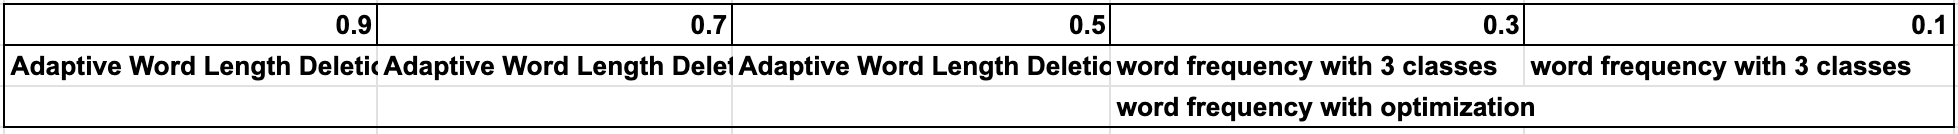

### Data Processing

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
import pandas as pd
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/Wiki_datasource/df_sample_5000.json"



odf = pd.read_json(path, lines=True)
odf.head(5)


In [ ]:
odf.rename(columns={"text": "wiki_text"}, inplace=True)
odf.head(5)

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "datasource"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
odf_filtered = (
    odf[~odf["wiki_text"].isin(df["wiki_text"])]
    .drop_duplicates(subset=["wiki_text"])
    .reset_index(drop=True)
)
odf_filtered.head(5)

In [ ]:
odf_sample = odf_filtered.sample(n=3000).reset_index(drop=True)
odf_sample.head(5)

In [ ]:
import tiktoken
import pandas as pd

enc = tiktoken.get_encoding("cl100k_base")

def count_tokens(text) -> int:
    if not isinstance(text, str) or not text.strip():
        return 0
    return len(enc.encode(text))

# 在 DataFrame 中新增一列 token_count
odf_sample["token_count"] = odf_sample["wiki_text"].apply(count_tokens)
odf_sample["char_length"] = odf_sample["wiki_text"].apply(
    lambda x: len(x) if isinstance(x, str) else 0
)

In [ ]:
!pip install lz4
import zlib,gzip,bz2,lzma,lz4.frame
import lzma

def compute_compression_ratios(text: str):
    raw = text.encode("utf-8")
    n = len(raw)

    gzip_ratio = len(gzip.compress(raw)) / n
    lzma_ratio = len(lzma.compress(raw)) / n
    bz2_ratio = len(bz2.compress(raw)) / n
    lz4_ratio=len(lz4.frame.compress(raw)) / n

    return {
        "gzip": gzip_ratio,
        "bz2": bz2_ratio,
        "lzma": lzma_ratio,
        "lz4":lz4_ratio
    }
odf_sample["compression"] = odf_sample["wiki_text"].apply(compute_compression_ratios)

In [ ]:
import ast,re
odf_sample["lzma_ratio"] = odf_sample["compression"].apply(lambda x: x["lzma"])
odf_sample["lz4_ratio"] = odf_sample["compression"].apply(lambda x: x["lz4"])
odf_sample["gzip_ratio"] = odf_sample["compression"].apply(lambda x: x["gzip"])

odf_sample.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("original_datasets")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="original_datasets", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, odf_sample)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### 0.1

3_class_word_frquency

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "sft_training_datasets"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

**Word Frequency with 3 classes**

In [ ]:
import re, random, math
from wordfreq import zipf_frequency

# ---------------------------------------
# 1. Tokenizer
# ---------------------------------------
def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text)

# ---------------------------------------
# 2. Zipf-based classification
# ---------------------------------------
def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

# ---------------------------------------
# 3. Strict deletion function + fallback
# ---------------------------------------
def delete_zipf_strict(text, keep_ratio=0.80, tol=0.02):
    tokens = tokenize(text)

    # Extract words
    indexed_words = []
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            cls = classify_word_zipf(tok)
            indexed_words.append((i, tok, cls))

    N = len(indexed_words)

    # 如果完全没有word → fallback
    if N == 0:
        return random_delete_fallback(text, keep_ratio)

    # ---------------------------------------
    # Zipf statistics
    # ---------------------------------------
    count_low  = sum(1 for _,_,c in indexed_words if c == "low")
    count_mid  = sum(1 for _,_,c in indexed_words if c == "mid")
    count_high = sum(1 for _,_,c in indexed_words if c == "high")

    total = count_low + count_mid + count_high

    stats_count = {
        "low": count_low,
        "mid": count_mid,
        "high": count_high
    }

    stats_ratio = {
        "low": round(count_low / total, 4) if total > 0 else 0,
        "mid": round(count_mid / total, 4) if total > 0 else 0,
        "high": round(count_high / total, 4) if total > 0 else 0
    }

    # ---------------------------------------
    # ✅ fallback：low/mid/high 全为0
    # ---------------------------------------
    if total == 0:
        return random_delete_fallback(text, keep_ratio)

    # ---------------------------------------
    # Determine deletion range
    # ---------------------------------------
    K = keep_ratio
    min_keep = max(0.0, K - tol)

    min_delete = math.ceil(N * (1 - K))
    max_delete = math.floor(N * (1 - min_keep))

    min_delete = max(0, min_delete)
    max_delete = min(N, max_delete)

    if min_delete > max_delete:
        delete_total = min_delete
    else:
        delete_total = random.randint(min_delete, max_delete)

    if delete_total <= 0:
        return text, 1.0, stats_count, stats_ratio

    # ---------------------------------------
    # Assign deletion counts
    # ---------------------------------------
    desired_low  = delete_total * (count_low  / N)
    desired_mid  = delete_total * (count_mid  / N)
    desired_high = delete_total * (count_high / N)

    delete_counts = {}
    frac = {}

    def base_count(desired, cap):
        b = int(math.floor(desired))
        return min(b, cap), desired - b

    delete_counts["low"],  frac["low"]  = base_count(desired_low,  count_low)
    delete_counts["mid"],  frac["mid"]  = base_count(desired_mid,  count_mid)
    delete_counts["high"], frac["high"] = base_count(desired_high, count_high)

    assigned = sum(delete_counts.values())
    remaining = delete_total - assigned

    order = ["low", "mid", "high"]
    while remaining > 0:
        valid = [c for c in order if delete_counts[c] < stats_count[c]]
        if not valid:
            break
        best = max(valid, key=lambda x: frac[x])
        delete_counts[best] += 1
        remaining -= 1

    # ---------------------------------------
    # Delete tokens
    # ---------------------------------------
    low_idx  = [i for i,_,c in indexed_words if c == "low"]
    mid_idx  = [i for i,_,c in indexed_words if c == "mid"]
    high_idx = [i for i,_,c in indexed_words if c == "high"]

    delete_set = set()
    delete_set.update(random.sample(low_idx,  min(delete_counts["low"],  len(low_idx))))
    delete_set.update(random.sample(mid_idx,  min(delete_counts["mid"],  len(mid_idx))))
    delete_set.update(random.sample(high_idx, min(delete_counts["high"], len(high_idx))))

    # Rebuild
    new_tokens = []
    for i, tok in enumerate(tokens):
        if i in delete_set:
            continue
        new_tokens.append(tok)

    # Detokenize
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    actual_keep = (N - len(delete_set)) / N

    return "".join(out), actual_keep, stats_count, stats_ratio


# ---------------------------------------
# 🔥 fallback function（关键新增）
# ---------------------------------------
def random_delete_fallback(text, keep_ratio):
    chars = list(text)
    n = len(chars)

    if n == 0:
        return "", 0.0, {"low":0,"mid":0,"high":0}, {"low":0,"mid":0,"high":0}

    keep_n = int(n * keep_ratio)
    keep_n = max(0, min(n, keep_n))

    keep_indices = set(random.sample(range(n), keep_n)) if keep_n > 0 else set()

    new_text = "".join([chars[i] for i in range(n) if i in keep_indices])
    actual_keep = len(new_text) / n

    return new_text, actual_keep, {"low":0,"mid":0,"high":0}, {"low":0,"mid":0,"high":0}

In [ ]:
import random

def random_delete_to_ratio(text, keep_ratio=0.1):
    chars = list(text)
    n = len(chars)

    keep_n = int(n * keep_ratio)

    if keep_n <= 0:
        return ""

    # 随机选择保留的位置
    keep_indices = set(random.sample(range(n), keep_n))

    # 构造新字符串
    new_chars = [chars[i] for i in range(n) if i in keep_indices]

    return "".join(new_chars)

In [ ]:
## case example

text = df["wiki_text"].iloc[2899]

res, actual,_,_ = delete_zipf_strict(text, keep_ratio=0.10)

print(res)
print("实际 keep ratio:", actual)

In [ ]:
dfd=dff.at[1777, "wiki_text"]
delete_zipf_strict(dfd, keep_ratio=0.10, tol=0.02)

In [ ]:
#dff=df.copy()
#dff["keep_actual_ratio"] = [{} for _ in range(len(dff))]

for idx in range(1777,len(dff)):
    print("No,", idx)
    text = dff.at[idx, "wiki_text"]

    res1, actual_keep1, _, _ = delete_zipf_strict(text, keep_ratio=0.10, tol=0.02)
    dff.at[idx, "keep_char_10"] = res1
    dff.at[idx, "keep_actual_ratio"]["10"] = actual_keep1
    print("result",res1,"实际 keep ratio 10%:", actual_keep1)

    df.at[idx, "keep_char_10"] = res1

    res3, actual_keep3, _, _ = delete_zipf_strict(text, keep_ratio=0.30, tol=0.02)
    dff.at[idx, "keep_char_30"] = res3
    dff.at[idx, "keep_actual_ratio"]["30"] = actual_keep3
    print("result",res1,"实际 keep ratio 10%:", actual_keep1)





In [ ]:
dff.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_training_datasets")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_training_datasets", rows="3000", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### 0.9,0.7,0.5


Adaptive Word Length Deletion

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "original_datasets"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

**Adaptive Word Length Deletion**

In [ ]:
import re
import random

VOWELS = "aeiouAEIOU"


def detokenize_partial_space(tokens, keep_space_prob=1.0):
    """
    keep_space_prob=1.0 -> 全保留空格（等价于原 detokenize 的加空格逻辑）
    keep_space_prob=0.0 -> 全删空格（等价于 drop_spaces=True）
    0<p<1              -> 只保留一部分空格（其余空格不加）
    """
    out = []
    for tok in tokens:
        if tok == "":
            continue
        if not out:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):  # 标点紧贴
                out.append(tok)
            else:
                if random.random() < keep_space_prob:
                    out.append(" " + tok)
                else:
                    out.append(tok)
    return "".join(out)


def compress_gradual_vowel_full(
        text,
        target_ratio=1.0,
        margin=0.02   # target=0.9 → [0.88, 0.90)
    ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    original_len = len(text)

    # ---- 定义目标范围 ----
    max_len = int(original_len * target_ratio)
    min_len = int(original_len * (target_ratio - margin))

    new_tokens = tokens[:]
    keep_space_prob = 1.0  # Step C：只删除“部分空格”（不删标点/数字）

    def current_text():
        return detokenize_partial_space(new_tokens, keep_space_prob=keep_space_prob)

    def current_len():
        return len(current_text())

    def acceptable():
        L = current_len()
        return (min_len <= L < max_len)

    # =====================================================
    # Step C：先删除空格（不删除标点/数字）——只删一部分空格（逐级）
    # =====================================================
    for p in (0.98, 0.95, 0.9, 0.8, 0.7, 0.5, 0.3, 0.1, 0.0):
        keep_space_prob = p
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 1：长词逐级删除元音（k=1→2→…→all）
    # =====================================================
    long_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) >= 3
    ]
    long_positions.sort(key=lambda x: len(x[1]), reverse=True)

    for idx, word in long_positions:
        vowels = [i for i, c in enumerate(word) if c in VOWELS]
        if not vowels:
            continue

        for k in range(1, len(vowels) + 1):
            del_positions = random.sample(vowels, k)
            w = word
            for pos in sorted(del_positions, reverse=True):
                w = w[:pos] + w[pos + 1:]
            new_tokens[idx] = w

            if acceptable():
                final = current_text()
                return final, len(final) / original_len

        # 删除所有元音
        w = "".join(c for c in word if c not in VOWELS)
        new_tokens[idx] = w

        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 2：短词删除策略（保持原顺序）
    # =====================================================
    short2_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 2
    ]

    # Step 2.1: len=2 -> 删除一个字母
    for idx, tok in short2_positions:
        pos = random.choice([0, 1])
        new_tokens[idx] = tok[:pos] + tok[pos + 1:]
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.2: 删除长度=1 的词
    short1_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 1
    ]

    for idx, tok in short1_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.3: 删除整个长度=2 的词
    for idx, tok in short2_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step A（兜底 1）：长词继续删辅音/字符（按比例/逐级）
    # =====================================================
    for keep_frac in (0.8, 0.6, 0.5, 0.4, 0.3, 0.2):
        for idx, tok in enumerate(new_tokens):
            if tok.isalpha() and len(tok) >= 3:
                L = len(tok)
                keep_len = max(1, int(L * keep_frac + 0.9999))  # ceil
                if keep_len >= L:
                    continue

                keep_pos = {0}
                if keep_len > 1:
                    rest = list(range(1, L))
                    keep_pos |= set(random.sample(rest, keep_len - 1))

                new_tokens[idx] = "".join(tok[i] for i in range(L) if i in keep_pos)

                if acceptable():
                    final = current_text()
                    return final, len(final) / original_len

    # =====================================================
    # Step E（兜底 2）：先删除标点 token（标点在数字之前）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if re.match(r"^[^\w\s]$", tok):
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step D（兜底 3）：再删除数字 token（例如 2026, 123）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if tok.isdigit():
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step F（最终兜底）：随机删除其他字符（字符级）
    # =====================================================
    text_now = current_text()
    chars = list(text_now)

    delete_positions = [i for i, c in enumerate(chars) if c.strip() != ""]
    random.shuffle(delete_positions)

    for pos in delete_positions:
        chars[pos] = ""
        candidate = "".join(chars)
        L = len(candidate)
        if min_len <= L < max_len:
            return candidate, L / original_len

    final = "".join(chars)
    return final, len(final) / original_len


In [ ]:
#text = "The information processing system was originally designed for efficiency and clarity."
text=df["wiki_text"].iloc[75]
compressed, ratio = compress_gradual_vowel_full(text, 0.90, margin=0.02)

print(compressed)
print("Actual ratio:", ratio)


In [ ]:
# 固定压缩率
fixed_ratios = {
    "keep_char_90": 0.90,
    "keep_char_70": 0.70,
    "keep_char_50": 0.50,
}

# ---------------------------
# A. 先处理固定 ratio
# ---------------------------

for name, r in fixed_ratios.items():
    col_text = f"{name}"
    col_ratio = f"{name}_actual"

    df[[col_text, col_ratio]] = df["wiki_text"].apply(
        lambda x: pd.Series(compress_gradual_vowel_full(x, target_ratio=r, margin=0.02))
    )



In [ ]:
df.head(10)

In [ ]:
lst=df[df["keep_char_90"]==""].index.tolist()
print(len(lst))
print(lst)

In [ ]:
for index in lst:
  text=df.at[index,"wiki_text"]
  compressed, ratio = compress_gradual_vowel_full(text, 0.90, margin=0.03)
  df.at[index,"keep_char_90"]=compressed
  df.at[index,"keep_char_90_actual"]=ratio

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("word_length_deletion")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="word_length_deletion", rows="3000", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### 0.3

optimal_word_frquency

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "full_datasets_english_news_sft_processing_opm"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
all_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
all_df.head(5)

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_wf_optimal"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
cur_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
cur_df.head(5)

In [ ]:
all_df.columns

In [ ]:
key_cols = ["Category", "Articles", "Summaries"]
cols_to_update =cur_df.columns.tolist()
cols_to_update  =cols_to_update[9:]

In [ ]:
def write_back(all_df, cur_df, key_cols, cols_to_update):
    merged = all_df.merge(
        cur_df[key_cols + cols_to_update],
        on=key_cols,
        how="left",
        suffixes=("", "_new")
    )

    for col in cols_to_update:
        merged[col] = merged[col + "_new"].combine_first(merged[col])
        merged.drop(columns=[col + "_new"], inplace=True)

    return merged



all_df = write_back(all_df, cur_df, key_cols, cols_to_update)

In [ ]:
cur_df.shape[0]

In [ ]:
all_df[all_df.duplicated(key_cols, keep=False)].sort_values(key_cols)

In [ ]:
all_df[all_df["p_zipf_stats"].notna()].shape[0]

##### Updated p_i: with 6 class

low / mid / high：只对 纯字母词（英文单词）做 Zipf 分类

punct：中英文标点（以及各种符号类标点）

num_other：数字 + 其他（包含数字、混合词、中文字符、emoji、不可见字符等你不想细分的）

whitespace（空格 / 换行 / tab 等）

In [ ]:
!pip install wordfreq
import re
import unicodedata
from wordfreq import zipf_frequency

def tokenize(text):
    # 词 or 单个非空白字符（空白不会被 token 化）
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    # P*: punctuation, S*: symbol
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    # 纯字母词（英文/拉丁字母）；你也可保留 tok.isalpha()
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026 等都算“数字类”
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

def zipf_length_proportions_rawlen_6cat(text):
    """
    6类比例（总和=1）：
      low/mid/high: 纯字母词按 zipf 分类，累计 len(tok)
      punct: 标点/符号 token，累计 len(tok)
      num_other: 数字 + 其它非上述 token（含中文、混合串、emoji等），累计 len(tok)
      whitespace: 所有空白字符（isspace=True），累计字符数
    分母= len(text)（压缩算法看到的字符数）
    """
    if not isinstance(text, str) or len(text) == 0:
        return {"low": 0.0, "mid": 0.0, "high": 0.0, "punct": 0.0, "num_other": 0.0, "whitespace": 0.0}

    total_len = len(text)

    # 第6类：空白字符（包含 space/newline/tab/各种 Unicode 空白）
    whitespace_len = sum(1 for ch in text if ch.isspace())

    tokens = tokenize(text)
    num = {"low": 0, "mid": 0, "high": 0, "punct": 0, "num_other": 0, "whitespace": whitespace_len}

    for tok in tokens:
        if is_punct_token(tok):
            num["punct"] += len(tok)
        elif is_alpha_word(tok):
            cls = classify_word_zipf(tok)
            num[cls] += len(tok)
        elif is_number_like(tok):
            num["num_other"] += len(tok)
        else:
            num["num_other"] += len(tok)

    # 转成比例
    props = {k: v / total_len for k, v in num.items()}

    # （可选）数值检查：理论上应非常接近 1
    # print("sum:", sum(props.values()))

    return props


In [ ]:
mask = all_df["p_zipf_stats"].isna()

all_df.loc[mask, "p_zipf_stats"] = (
    all_df.loc[mask, "Articles"]
          .apply(zipf_length_proportions_rawlen_6cat)
)

##### Update b_i: bertscore with only delete i

We have 6 classes. Due to the polishment is easy to change the original meaning, and for whitespace. puncutation and number_other, it doesn't change a lot of meaning, so we only use polished text for deleting low,mid, high freq and use restore text for deleting whitespace, puncutation and number_other as bertscore of only delete pi.

In [ ]:
updated_lst=df[df["b_zipf_stats"].isna()].index.tolist()


In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

###### Only delete pi

In [ ]:
!pip install wordfreq
import re
import unicodedata
from wordfreq import zipf_frequency

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    # P*: punctuation, S*: symbol
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026 等
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

# ✅ 关键：包含 whitespace 的分段 tokenizer（不丢位置信息）
_SEG_RE = re.compile(r"\s+|\w+|[^\w\s]", flags=re.UNICODE)

def segment_class(seg: str) -> str:
    """把一个 segment 归到 6 类之一。"""
    if seg.isspace():
        return "whitespace"

    # \w+ 段：可能是英文词/数字/中文/混合
    if re.fullmatch(r"\w+", seg):
        if is_alpha_word(seg):
            return classify_word_zipf(seg)  # low/mid/high
        else:
            # 数字 / 中文 / 混合串都归 num_other
            return "num_other"

    # 单字符非空白：标点/符号/emoji 等
    if is_punct_token(seg):
        return "punct"
    return "num_other"

def delete_by_class(text: str, cls_to_delete: str) -> str:
    """
    只删除指定类别的 segments，返回新文本。
    cls_to_delete in: {"low","mid","high","punct","num_other","whitespace"}
    """
    if not isinstance(text, str) or len(text) == 0:
        return text

    out = []
    for seg in _SEG_RE.findall(text):
        if segment_class(seg) == cls_to_delete:
            continue
        out.append(seg)
    return "".join(out)

def delete_variants_6cat(text: str) -> dict:
    """一次性生成 6 个版本：分别只删除某一类。"""
    classes = ["low", "mid", "high", "punct", "num_other", "whitespace"]
    return {f"del_{c}": delete_by_class(text, c) for c in classes}

### write back to df

classes = ["low", "mid", "high", "punct", "num_other", "whitespace"]

mask = df["delete_low"].isna()

tmp = df.loc[mask, "Articles"].apply(delete_variants_6cat)

for c in classes:
    df.loc[mask, f"delete_{c}"] = tmp.map(lambda d: d[f"del_{c}"])


In [ ]:
"""
import os
from google.colab import drive
drive.mount('/content/drive')
all_df.to_csv("/content/drive/MyDrive/LLM error correction/datasource/english_text/full_datasets_english_news_for_sft.csv", index=False)
"""

##### With Polished: LLM for restoration

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"#"<GOOGLE_SHEET_ID>"
sheet_name = "full_datasets_english_news_sft_processing_opm"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
updated_lst=df[df["w_optimal_cvx"].isna()].index.tolist()


In [ ]:
df=df.assign(updated_lst=None)
df["updated_lst"].iloc[0]=updated_lst

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"]) #os.environ["GOOGLE_API_KEY"])


model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing English words (due to category-based deletion), missing punctuation symbols (e.g., commas, periods, hyphens), missing numeric or non-alphabetic tokens, or missing whitespace characters such as spaces, line breaks, or tabs.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()



def restore_text(corrupted_text, retries=5):
    prompt = build_prompt(corrupted_text)

    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]

        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            if response and response.text:
                return response.text.strip()

            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}, temperature={temp}: {e}")
            #time.sleep(2)
            time.sleep(2 * (attempt + 1))

    return corrupted_text


cols_to_restore = ["delete_low","delete_mid","delete_high","delete_punct", "delete_num_other", "delete_whitespace"]

for col in cols_to_restore:
    curr_col=col.split("delete_")[1]
    output_col = f"restored_delete_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    #df[output_col] = ""

    for idx in range(len(df)):
        val = df.at[idx, output_col]
        if pd.notna(val) and str(val).strip() != "":
            continue
        #if df.at[idx, output_col]:
        #    continue

        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:", corrupted)


        restored = restore_text(corrupted)

        print("Restored:", restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored

In [ ]:
df['restored_delete_num_other']

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')
df.to_csv("/content/drive/MyDrive/LLM error correction/datasource/english_text/full_datasets_english_news_sft_processing_opm_v2.csv", index=False)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>" #"<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("full_datasets_english_news_sft_processing_opm_v2")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="full_datasets_english_news_sft_processing_opm_v2", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##### With Polished: LLM for polishment


这里只polish low/mid/high freq

In [ ]:
updated_lst=df[df["polished_delete_whitespace"].isna()].index.tolist()
len(updated_lst)

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()


def build_prompt_updated(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Improve fluency and readability by smoothing awkward wording while largely preserving the original phrasing and sentence structure.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.
- Prefer minimal edits over rewriting.

Restored Text:
{input_text}

Polished Output:
""".strip()


# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=5):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    #prompt = build_prompt(corrupted_text)
    prompt = build_prompt_updated(corrupted_text)
    temperatures = [0.1, 0.1, 0.5, 1.0, 1.0]

    for attempt in range(retries):
        temp = temperatures[min(attempt, len(temperatures) - 1)]
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": temp,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            print(f"Empty response at attempt {attempt+1}, temperature={temp}")

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}, temperature={temp}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑

cols_to_restore = ["restored_delete_low","restored_delete_mid","restored_delete_high"]
#

for col in cols_to_restore:
    curr_suffix = col.split("restored_delete_")[1]
    output_col = f"polished_delete_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")


    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        if df.at[idx, output_col]:
            continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



##### Bertscore calculation

In [ ]:
import ast
df["b_zipf_stats_restore"] = df["b_zipf_stats_restore"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["b_zipf_stats"] = df["b_zipf_stats"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

In [ ]:
df.at[2,"b_zipf_stats_restore"]

In [ ]:
!pip install -q bert_score
import nltk
nltk.download("punkt")

import torch
import logging
import pandas as pd
from tqdm import tqdm
from bert_score import BERTScorer

logging.getLogger("transformers").setLevel(logging.ERROR)

# ===============================
# 1️⃣ 配置
# ===============================

MODEL = "distilroberta-base"
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

In [ ]:
logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    batch_size=64,      # 可以根据显存调整
    device=device
)

# 你指定的列映射
col_map = {
    "low": "restored_delete_low",
    "mid": "restored_delete_mid",
    "high": "restored_delete_high",
    "punct": "restored_delete_punct",
    "num_other": "restored_delete_num_other",
    "whitespace": "restored_delete_whitespace",
}

# ===============================
# 2️⃣ 收集所有待计算样本（批量）
# ===============================

pairs = []
meta = []

for idx in df.index:

    # 断点续跑：如果已经有 dict 且包含所有 suffix，跳过
    existing = df.at[idx, "b_zipf_stats_restore"]
    if isinstance(existing, dict) and len(existing) == len(col_map):
        continue

    original = df.at[idx, "Articles"]
    if not isinstance(original, str) or not original.strip():
        continue

    for suffix, col in col_map.items():

        if col not in df.columns:
            continue

        cand = df.at[idx, col]
        if not isinstance(cand, str) or not cand.strip():
            continue

        pairs.append((cand, original))
        meta.append((idx, suffix))

print("Total pairs to compute:", len(pairs))

# ===============================
# 3️⃣ 批量计算 BERTScore
# ===============================

if len(pairs) > 0:

    cands = [p[0] for p in pairs]
    refs  = [p[1] for p in pairs]

    P, R, F1 = scorer.score(cands, refs)

    # ===============================
    # 4️⃣ 写回 DataFrame
    # ===============================

    for i, (idx, suffix) in enumerate(meta):

        if not isinstance(df.at[idx, "b_zipf_stats_restore"], dict):
            df.at[idx, "b_zipf_stats_restore"] = {}

        df.at[idx, "b_zipf_stats_restore"][suffix] = float(F1[i])
        #df.at[idx, "b_zipf_stats_restore_full"][suffix] = {
        #    "P": float(P[i]),
        #    "R": float(R[i]),
        #    "F1": float(F1[i])
        #}
        print("index",idx,df.at[idx, "b_zipf_stats_restore"][suffix])

print("✅ BERTScore computation finished.")

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')
df.to_csv("/content/drive/MyDrive/LLM error correction/datasource/english_text/full_datasets_english_news_sft_processing_opm_v3.csv", index=False)

In [ ]:

!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("full_datasets_english_news_sft_processing_opm_v2")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="full_datasets_english_news_sft_processing_opm_v2", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##### **Solve equation via CVX**

In [ ]:
import numpy as np
import ast
import cvxpy as cp


def extract_bp_from_df(df, row_idx, b_col="b_zipf_stats", p_col="p_zipf_stats", keys=None):
    b_dict = df[b_col].iloc[row_idx]
    if isinstance(b_dict, str):
        b_dict = ast.literal_eval(b_dict)

    p_dict = df[p_col].iloc[row_idx]
    if isinstance(p_dict, str):
        p_dict = ast.literal_eval(p_dict)

    if keys is None:
        keys = sorted(b_dict.keys())

    b = np.array([b_dict[k] for k in keys], dtype=float)
    p = np.array([p_dict[k] for k in keys], dtype=float)
    return b, p, keys

def solve_max_product_cvxpy(b, p, T, eps=1e-12, solver="ECOS", verbose=False):
    """
    Solve via CVXPY:
        max Π_i [1 - (1-b_i) w_i]
        s.t. Σ p_i(1-w_i) <= T, 0<=w<=1

    We solve equivalent:
        max Σ log(1 - (1-b_i) w_i)
    """
    b = np.asarray(b, dtype=float)
    p = np.asarray(p, dtype=float)
    a = 1.0 - b
    n = len(b)

    w = cp.Variable(n)

    # log argument
    t = 1 - cp.multiply(a, w)

    constraints = [
        cp.sum(cp.multiply(p, 1 - w)) <= T,
        w >= 0,
        w <= 1,
        t >= eps,   # avoid log(0)
    ]

    objective = cp.Maximize(cp.sum(cp.log(t)))
    prob = cp.Problem(objective, constraints)

    # Solver options (different solvers have different knobs)
    if solver.upper() == "ECOS":
        prob.solve(solver=cp.ECOS, verbose=verbose,
                   abstol=1e-12, reltol=1e-12, feastol=1e-12, max_iters=2000)
    elif solver.upper() == "SCS":
        prob.solve(solver=cp.SCS, verbose=verbose,
                   eps=1e-6, max_iters=200000)  # SCS is first-order; eps is looser by default
    elif solver.upper() == "CLARABEL":
        prob.solve(solver=cp.CLARABEL, verbose=verbose)
    else:
        prob.solve(verbose=verbose)

    w_star = np.array(w.value).astype(float)

    # Recover original product objective (careful about underflow; log is safer)
    prod_obj = float(np.prod(1.0 - a * w_star))
    cons_val = float(np.sum(p * (1.0 - w_star)))

    return w_star, {
        "objective_product": prod_obj,
        "objective_logsum": float(np.sum(np.log(np.maximum(1.0 - a * w_star, 1e-300)))),
        "constraint_value": cons_val,
        #"solver": solver
        "diff":cons_val-T,
        "status": prob.status
    }


# ---------------------------
# Example usage
idx=3
b, p, keys = extract_bp_from_df(df, idx, b_col="b_zipf_stats_restore",
    p_col="p_zipf_stats",keys=["low","mid","high","punct","num_other","whitespace"]) #keys=["low","mid","high"])
T = 0.9
w_star, info = solve_max_product_cvxpy(b, p, T, solver="CLARABEL", verbose=False)
print("keys =", keys)
print("w* =", w_star)
print("info =", info)
#print("diff =", info["constraint_value"] - T)


In [ ]:
for i in range(len(df)):

    print("No", i)

    if not isinstance(df.at[i, "w_restore_optimal_cvx"], dict):
        df.at[i, "w_restore_optimal_cvx"] = {}

    if not isinstance(df.at[i, "w_restore_info_cvx"], dict):
        df.at[i, "w_restore_info_cvx"] = {}

    T_items = [
        ("0.9", 0.9),
        ("0.8", 0.8),
        ("lz4",  float(df.at[i, "lz4_ratio"])),
        ("0.7", 0.7),
        ("0.6", 0.6),
        ("lzma", float(df.at[i, "lzma_ratio"])),
        ("0.5", 0.5),
        ("gzip", float(df.at[i, "gzip_ratio"])),
        ("0.4", 0.4),
        ("0.3", 0.3),
        ("0.2", 0.2),
        ("0.1", 0.1),
    ]


    b, p, keys = extract_bp_from_df(
        df, i,
        b_col="b_zipf_stats_restore",
        p_col="p_zipf_stats",
        keys=["low","mid","high","punct","num_other","whitespace"]
    )

    for label, t in T_items:

        if label in df.at[i, "w_restore_optimal_cvx"]:
            continue  # 已算过

        w_star, info = solve_max_product_cvxpy(
            b, p, t, solver="CLARABEL", verbose=False
        )

        df.at[i, "w_restore_optimal_cvx"][label] = w_star.tolist()
        df.at[i, "w_restore_info_cvx"][label] = info

In [ ]:
df["w_restore_optimal_cvx"] = [dict() for _ in range(len(df))]
df["w_restore_info_cvx"] = [dict() for _ in range(len(df))]

for i in range(len(df)):
    print("No",i)
    b, p, keys = extract_bp_from_df(df, i, b_col="b_zipf_stats_restore",
    p_col="p_zipf_stats",keys=["low","mid","high","punct","num_other","whitespace"])

    T_items = [
        ("0.9", 0.9),
        ("0.8", 0.8),
        ("lz4",  float(df.at[i, "lz4_ratio"])),
        ("0.7", 0.7),
        ("0.6", 0.6),
        ("lzma", float(df.at[i, "lzma_ratio"])),
        ("0.5", 0.5),
        ("gzip", float(df.at[i, "gzip_ratio"])),
        ("0.4", 0.4),
        ("0.3", 0.3),
        ("0.2", 0.2),
        ("0.1", 0.1),
    ]

    for label, t in T_items:
        w_star, info = solve_max_product_cvxpy(b, p, t, solver="CLARABEL", verbose=False)
        df.at[i, "w_restore_optimal_cvx"][label] = w_star.tolist()   # 或者直接 w_star
        df.at[i, "w_restore_info_cvx"][label] = info   # 存最后一次的 info


##### Data Processing via w_optimal

In [ ]:


# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "full_datasets_english_news_sft_processing"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
cvx_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
print(len(cvx_df))
cvx_df.head(10)

In [ ]:
# ============================================================
# Full pipeline: 6-class segmentation + stochastic deletion by w
# Generates new df columns for each retention-rate key in w_all
# ============================================================

# If running in Colab:
!pip -q install wordfreq

import re
import unicodedata
import random
import ast
from typing import Dict, List, Any, Optional

import numpy as np
import pandas as pd
import random
from collections import defaultdict

from wordfreq import zipf_frequency

# -----------------------------
# 1) 6-class definitions
# -----------------------------
CLASSES = ["low", "mid", "high", "punct", "num_other", "whitespace"]

def classify_word_zipf(word: str) -> str:
    """Classify English alpha words into low/mid/high by Zipf frequency."""
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    """Token is punctuation/symbol if all chars are category P* or S*."""
    if not tok:
        return False
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026, etc.
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

# Keep whitespace segments to preserve position info
_SEG_RE = re.compile(r"\s+|\w+|[^\w\s]", flags=re.UNICODE)

def segment_class(seg: str) -> str:
    """
    Map a segment to one of 6 classes:
    low/mid/high (alpha words by Zipf), punct, num_other, whitespace.
    """
    if seg.isspace():
        return "whitespace"

    # \w+ could be alpha word / number / CJK / mixed
    if re.fullmatch(r"\w+", seg):
        if is_alpha_word(seg):
            return classify_word_zipf(seg)  # low/mid/high
        else:
            return "num_other"

    # non-space, non-\w: punctuation/symbol/emoji, etc.
    if is_punct_token(seg):
        return "punct"
    return "num_other"

# -----------------------------
# 2) Convert w list -> dict
# -----------------------------
def w_list_to_dict(w_list):
    return dict(zip(CLASSES, w_list))
# -----------------------------
# 3) Stochastic deletion by w
# -----------------------------

def _compute_keep_ratio(original: str, modified: str) -> float:
    return len(modified) / max(len(original), 1)

def delete_by_w_length_budget_with_target(
    text: str,
    w_dict: Dict[str, float],
    T: float,                      # 目标保留率，例如 0.9
    lower: float = 0.88,           # 允许下界
    eps: float = 1e-6,
    seed: Optional[int] = None,
) -> str:
    """
    目标：最终保留率 keep_ratio 落在 [lower, T]，并尽量贴近 T（不超过T）。
    1) 先按类长度预算删（segment级）
    2) 若 keep_ratio > T：用 whitespace 做字符级微调删到接近 T
    3) 若 keep_ratio < lower：回退到微调前文本（更保守）
    """
    if not isinstance(text, str) or len(text) == 0:
        return text

    rng = random.Random(seed)
    segs = _SEG_RE.findall(text)

    class_items = defaultdict(list)
    for idx, seg in enumerate(segs):
        cls = segment_class(seg)
        class_items[cls].append((idx, seg, len(seg)))

    to_delete = set()

    for cls, items in class_items.items():
        w = float(w_dict.get(cls, 0.0))
        w = max(0.0, min(1.0, w))
        if w == 0.0:
            continue

        total_len = sum(l for _, _, l in items)
        target_del_len = w * total_len

        rng.shuffle(items)

        acc = 0
        for idx, seg, l in items:
            if acc >= target_del_len:
                break
            to_delete.add(idx)
            acc += l

    # --- 重建第一次（微调前） ---
    out_before_tweak = "".join(seg for i, seg in enumerate(segs) if i not in to_delete)
    keep_ratio = _compute_keep_ratio(text, out_before_tweak)

    out = out_before_tweak

    # --- 如果保留率 > T：删少了，用 whitespace 字符级补刀 ---
    if keep_ratio > T + eps:
        target_len = int(round(T * len(text)))
        need_del_chars = len(out) - target_len  # 需要再删掉的字符数（尽量从空白删）
        if need_del_chars > 0:
            out_chars = list(out)
            removed = 0
            for j in range(len(out_chars) - 1, -1, -1):
                if removed >= need_del_chars:
                    break
                if out_chars[j].isspace():
                    out_chars[j] = ""
                    removed += 1
            out = "".join(out_chars)

    # --- 保底：如果删过头，回退到微调前 ---
    keep_ratio_after = _compute_keep_ratio(text, out)
    if keep_ratio_after < lower - eps:
        return out_before_tweak

    return out


def ensure_w_dict(x):
    """df 单元格可能是 dict / str(dict) / [dict]，统一转成 dict"""
    if isinstance(x, dict):
        return x
    if isinstance(x, list) and len(x) == 1 and isinstance(x[0], dict):
        return x[0]
    if isinstance(x, str):
        y = ast.literal_eval(x)
        if isinstance(y, dict):
            return y
        if isinstance(y, list) and len(y) == 1 and isinstance(y[0], dict):
            return y[0]
    raise TypeError(f"Unsupported w format: {type(x)}")

def key_to_colname(prefix: str, key: str) -> str:
    """'0.9'->optimal_del_90, 'lz4'->optimal_del_lz4"""
    try:
        T = float(key)
        return f"{prefix}_{int(round(T*100))}"
    except:
        return f"{prefix}_{str(key)}"


def apply_optimal_del_columns_mixed_keys(
    df: pd.DataFrame,
    text_col: str = "Articles",
    w_col: str = "w_optimal_cvx",
    prefix: str = "optimal_del",
    band: float = 0.02,
    base_seed: int = 123,
    compressor_T_cols: dict = None,# e.g. {"lz4":"lz4_ratio","lzma":"lzma_ratio","gzip":"gzip_ratio"}
) -> pd.DataFrame:
    """
    对 df 每行：
      - 数值 key: T=float(key)
      - compressor key: T=df[对应ratio列] 的逐行值
    每个 key 生成单独一列。
    """
    if compressor_T_cols is None:
        compressor_T_cols = {"lz4": "lz4_ratio", "lzma": "lzma_ratio", "gzip": "gzip_ratio"}

    # 1) 收集全表所有 key（来自 w_col）
    all_keys = set()
    for x in df[w_col]:
        if x is None or (isinstance(x, float) and np.isnan(x)):
            continue
        w_all = ensure_w_dict(x)
        all_keys.update(w_all.keys())

    # 2) 拆分：数值 key + compressor key
    numeric_keys = []
    comp_keys = []

    for k in all_keys:
        ks = str(k)
        if ks in compressor_T_cols:
            comp_keys.append(ks)
        else:
            try:
                float(ks)
                numeric_keys.append(ks)
            except:
                # 其他非数值、非 compressor 的 key（如果未来有）先忽略
                pass

    #numeric_keys = sorted(numeric_keys, key=lambda x: float(x), reverse=True)
    #comp_keys = sorted(comp_keys)  # lz4/gzip/lzma 顺序随意，你也可自定义
    numeric_keys = sorted(numeric_keys, key=lambda x: float(x), reverse=True)
    comp_keys = sorted(comp_keys)

    # 🔥 只保留 0.5 和 0.9
    TARGET_RATIOS = {0.5, 0.9}
    numeric_keys = [k for k in numeric_keys if float(k) in TARGET_RATIOS]

    # 3) 先做数值 key（T固定 = float(key)）
    for key in numeric_keys:
        T_fixed = float(key)
        col = key_to_colname(prefix, key)

        out = []
        lower_fixed = max(0.0, T_fixed - band)

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_length_budget_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=T_fixed,
                    lower=lower_fixed,
                    seed=seed
                )
            )
        df[col] = out

    # 4) 再做 compressor key（T逐行取 df[ratio_col]）
    comp_keys = [] ##新增如果不想要lz4这些
    for key in comp_keys:
        ratio_col = compressor_T_cols[key]
        if ratio_col not in df.columns:
            raise KeyError(f"Missing ratio column '{ratio_col}' for key '{key}'")

        col = key_to_colname(prefix, key)
        out = []

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            # 逐行 T
            T_i = float(df[ratio_col].iloc[i])
            # 安全剪裁到 [0,1]
            T_i = max(0.0, min(1.0, T_i))
            lower_i = max(0.0, T_i - band)

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_length_budget_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=T_i,
                    lower=lower_i,
                    seed=seed
                )
            )
        df[col] = out

    return df

cvx_df = apply_optimal_del_columns_mixed_keys(
    cvx_df,
    text_col="Articles",
    w_col="w_restore_optimal_cvx",
    prefix="keep_char",
    band=0.02,
    compressor_T_cols=None
)

In [ ]:
cvx_df["keep_char_90"]

In [ ]:
cvx_df.columns

In [ ]:

import os
from google.colab import drive
drive.mount('/content/drive')
cvx_df.to_excel("/content/drive/MyDrive/LLM error correction/datasource/english_text/full_datasets_english_news_sft_processing_opm_updated.xlsx", index=False)

In [ ]:
cvx_df

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)


# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("full_datasets_english_news_sft_processing")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="full_datasets_english_news_sft_processing", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, cvx_df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##### Count the actual_ratio

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "full_datasets_english_news_for_sft"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
dff = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
dff.head(10)

In [ ]:
def update_keep_actual_ratio(
    df,
    original_col="Articles",
    prefix="keep_char",
    ratio_col="keep_actual_ratio",
    target_ratios=(50, 90)
):
    """
    在已有 keep_actual_ratio(dict) 中
    添加 50 / 90 的实际字符比例
    """

    for i in range(len(df)):

        original = df.at[i, original_col]
        original_len = len(original) if isinstance(original, str) else 0
        if original_len == 0:
            continue

        # 读取已有 dict
        cur_dict = df.at[i, ratio_col]

        if isinstance(cur_dict, str):
            cur_dict = ast.literal_eval(cur_dict)
        if not isinstance(cur_dict, dict):
            cur_dict = {}

        # 逐个 target ratio 更新
        for r in target_ratios:
            col = f"{prefix}_{r}"
            if col in df.columns:
                kept_text = df.at[i, col]
                if isinstance(kept_text, str):
                    cur_dict[str(r)] = len(kept_text) / original_len

        # 写回
        df.at[i, ratio_col] = cur_dict

    return df

dff = update_keep_actual_ratio(dff)

In [ ]:
dff["keep_actual_ratio"].iloc[1]

In [ ]:
ratio_class_map = {
    "10":"word_frequency_3classes",
    "30":"word_frequency_3classes",
    "50":"word_frequency_optimal",
    "70":"adaptive_word_deletion",
    "90":"word_frequency_optimal"
}

dff["optimal_class"] = [ratio_class_map.copy() for _ in range(len(dff))]

In [ ]:
dff["optimal_class"]

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("full_datasets_english_news_for_sft")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="full_datasets_english_news_for_sft", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
import re
import random

VOWELS = "aeiouAEIOU"


def detokenize_partial_space(tokens, keep_space_prob=1.0):
    """
    keep_space_prob=1.0 -> 全保留空格（等价于原 detokenize 的加空格逻辑）
    keep_space_prob=0.0 -> 全删空格（等价于 drop_spaces=True）
    0<p<1              -> 只保留一部分空格（其余空格不加）
    """
    out = []
    for tok in tokens:
        if tok == "":
            continue
        if not out:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):  # 标点紧贴
                out.append(tok)
            else:
                if random.random() < keep_space_prob:
                    out.append(" " + tok)
                else:
                    out.append(tok)
    return "".join(out)


def compress_gradual_vowel_full(
        text,
        target_ratio=1.0,
        margin=0.02   # target=0.9 → [0.88, 0.90)
    ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    original_len = len(text)

    # ---- 定义目标范围 ----
    max_len = int(original_len * target_ratio)
    min_len = int(original_len * (target_ratio - margin))

    new_tokens = tokens[:]
    keep_space_prob = 1.0  # Step C：只删除“部分空格”（不删标点/数字）

    def current_text():
        return detokenize_partial_space(new_tokens, keep_space_prob=keep_space_prob)

    def current_len():
        return len(current_text())

    def acceptable():
        L = current_len()
        return (min_len <= L < max_len)

    # =====================================================
    # Step C：先删除空格（不删除标点/数字）——只删一部分空格（逐级）
    # =====================================================
    for p in (0.95, 0.9, 0.8, 0.7, 0.5, 0.3, 0.1, 0.0):
        keep_space_prob = p
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 1：长词逐级删除元音（k=1→2→…→all）
    # =====================================================
    long_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) >= 3
    ]
    long_positions.sort(key=lambda x: len(x[1]), reverse=True)

    for idx, word in long_positions:
        vowels = [i for i, c in enumerate(word) if c in VOWELS]
        if not vowels:
            continue

        for k in range(1, len(vowels) + 1):
            del_positions = random.sample(vowels, k)
            w = word
            for pos in sorted(del_positions, reverse=True):
                w = w[:pos] + w[pos + 1:]
            new_tokens[idx] = w

            if acceptable():
                final = current_text()
                return final, len(final) / original_len

        # 删除所有元音
        w = "".join(c for c in word if c not in VOWELS)
        new_tokens[idx] = w

        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 2：短词删除策略（保持原顺序）
    # =====================================================
    short2_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 2
    ]

    # Step 2.1: len=2 -> 删除一个字母
    for idx, tok in short2_positions:
        pos = random.choice([0, 1])
        new_tokens[idx] = tok[:pos] + tok[pos + 1:]
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.2: 删除长度=1 的词
    short1_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 1
    ]

    for idx, tok in short1_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.3: 删除整个长度=2 的词
    for idx, tok in short2_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step A（兜底 1）：长词继续删辅音/字符（按比例/逐级）
    # =====================================================
    for keep_frac in (0.8, 0.6, 0.5, 0.4, 0.3, 0.2):
        for idx, tok in enumerate(new_tokens):
            if tok.isalpha() and len(tok) >= 3:
                L = len(tok)
                keep_len = max(1, int(L * keep_frac + 0.9999))  # ceil
                if keep_len >= L:
                    continue

                keep_pos = {0}
                if keep_len > 1:
                    rest = list(range(1, L))
                    keep_pos |= set(random.sample(rest, keep_len - 1))

                new_tokens[idx] = "".join(tok[i] for i in range(L) if i in keep_pos)

                if acceptable():
                    final = current_text()
                    return final, len(final) / original_len

    # =====================================================
    # Step E（兜底 2）：先删除标点 token（标点在数字之前）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if re.match(r"^[^\w\s]$", tok):
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step D（兜底 3）：再删除数字 token（例如 2026, 123）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if tok.isdigit():
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step F（最终兜底）：随机删除其他字符（字符级）
    # =====================================================
    text_now = current_text()
    chars = list(text_now)

    delete_positions = [i for i, c in enumerate(chars) if c.strip() != ""]
    random.shuffle(delete_positions)

    for pos in delete_positions:
        chars[pos] = ""
        candidate = "".join(chars)
        L = len(candidate)
        if min_len <= L < max_len:
            return candidate, L / original_len

    final = "".join(chars)
    return final, len(final) / original_len


In [ ]:
#text = "The information processing system was originally designed for efficiency and clarity."
text = df.at[2099, "Articles"]
compressed, ratio = compress_gradual_vowel_full(text, 0.70, margin=0.02)
print(text)
print(compressed)
print("Actual ratio:", ratio)

In [ ]:
for idx in df.index:
    print("No,", idx)
    text = df.at[idx, "Articles"]

    compressed, actual_ratio = compress_gradual_vowel_full(text, 0.70, margin=0.02)
    df.at[idx, "keep_char_70"] = compressed
    df.at[idx, "keep_actual_ratio"]["70"] = actual_ratio
    print("实际 keep ratio 70%:", actual_ratio)
    print("result",compressed)

    df.at[idx, "optimal_class"] = "adaptive_word_deletion"


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("full_datasets_english_news_for_sft")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="full_datasets_english_news_for_sft", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### SFT processing

#### Datasets Update

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_training_datasets"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
len(df)

#### Keep char 90, 70, 50

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

**Adaptive Word Length Deletion**

##### 90

###### train_val_ds processing

In [ ]:
sft_df_90 = df.dropna(subset=["wiki_text", "keep_char_90"])
sft_df_90["wiki_text"]=sft_df_90["wiki_text"].astype(str).str.strip()
sft_df_90["keep_char_90"]=sft_df_90["keep_char_90"].astype(str).str.strip()
sft_df_90 = sft_df_90[(sft_df_90["wiki_text"] != "") & (sft_df_90["keep_char_90"] != "")]
sft_df_90 = sft_df_90.drop_duplicates(subset=["wiki_text", "keep_char_90"]).reset_index(drop=True)

print("SFT rows:", len(sft_df_90))

In [ ]:
PROMPT = (
    "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.9). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wf_opt_90, out_path="repair_sft_wf_wld_90.json"):
    records = []
    for _, r in sft_wf_opt_90.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_90"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


**Store whole datasets to back up**

In [ ]:
from sklearn.model_selection import train_test_split
import json
all_df= sft_df_90
to_sft_json_messages(
    all_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_90.json"
)

print(len(all_df))

In [ ]:
import json
out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_90.json"
with open(out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

len(data)

**Train and Test Dataset Split**

In [ ]:
from sklearn.model_selection import train_test_split
import json

train_df, val_df = train_test_split(
    all_df, test_size=0.1, random_state=42, shuffle=True
)

In [ ]:
train_df.head(5)

In [ ]:

to_sft_json_messages(
    train_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_train_90.json"
)

to_sft_json_messages(
    val_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_val_90.json"
)

print(len(train_df), len(val_df))

**directly read dataset if you already store json to drive**

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import json
train_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_train_90.json"
with open(train_out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

with open("repair_sft_wf_wld_train_90.jsonl", "w", encoding="utf-8") as f:
    for sample in data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_train_90.jsonl",
    split="train"
)

print(len(train_ds))


In [ ]:
train_ds[-1]

In [ ]:
import json
val_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_val_90.json"
with open(val_out_path, "r", encoding="utf-8") as f:
    val_ds = json.load(f)

with open("repair_sft_wf_wld_val_90.jsonl", "w", encoding="utf-8") as f:
    for sample in val_ds:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_val_90.jsonl",
    split='train'

)

print(len(val_ds))


In [ ]:
val_ds[23]

###### Llama3.2-3b

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
pip install -U bitsandbytes>=0.46.1

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
)


model.gradient_checkpointing_disable()
model.config.use_cache = True
model = prepare_model_for_kbit_training(model)


In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

train_ds_proceed = train_ds.map(count_tokens)

lengths = np.array(train_ds_proceed["n_tokens"])

print("Samples:", len(lengths))
print("Min:", lengths.min())
print("Max:", lengths.max())
print("Mean:", lengths.mean())
print("P90:", np.percentile(lengths, 90))
print("P95:", np.percentile(lengths, 95))
print("P99:", np.percentile(lengths, 99))

###### sft with qlora parameters

In [ ]:
## all changed
from peft import LoraConfig, get_peft_model

model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


In [ ]:
def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

train_ds_proceed = train_ds_proceed.map(
    format_example,
    remove_columns=train_ds_proceed.column_names
)

print(train_ds_proceed[0]["text"])

In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

val_ds_proceed = val_ds.map(count_tokens)

lengths = np.array(val_ds_proceed["n_tokens"])

def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

val_ds_proceed = val_ds_proceed.map(
    format_example,
    remove_columns=val_ds_proceed.column_names
)

print(val_ds_proceed[0]["text"])

In [ ]:
!pip uninstall -y wandb
import os
os.environ["WANDB_DISABLED"] = "true"

In [ ]:
#rm -rf ./qlora_qwen25_decompress_lr2e4

**lr=2e4**

In [ ]:
from trl import SFTTrainer, SFTConfig

sft_config = SFTConfig(
    output_dir="./qlora_llama3_decompress_wld_90_lr2e4",
    max_length=1536,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,          # 我建议改成 2e-4
    num_train_epochs=10,#3,          # change to 10 and use early stop to stop it
    bf16=True,
    #fp16=False,
    logging_steps=10,
    save_strategy="epoch",       # 比 save_steps 好
    #save_steps=500,
    eval_strategy="epoch",
    save_total_limit=3,
    optim="paged_adamw_8bit",
    report_to="none",
    packing=False,

    #for early stop
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

In [ ]:
from transformers import EarlyStoppingCallback

trainer = SFTTrainer(
    model=model,
    train_dataset=train_ds_proceed,
    eval_dataset=val_ds_proceed,
    args=sft_config,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],#new add for early stop
)

In [ ]:
trainer.train()

In [ ]:
trainer.model.save_pretrained("./qlora_llama3_decompress_wld_90_lr2e4_lora")
tokenizer.save_pretrained("./qlora_llama3_decompress_wld_90_lr2e4_lora")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
out_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/"

!cp -r /content/qlora_llama3_decompress_wld_90_lr2e4_lora "{out_path}"

In [ ]:
"""
!zip -r qlora_llama3_decompress_wf_opt_90_lr2e4_lora.zip /content/qlora_llama3_decompress_wf_opt_90_lr2e4_lora
from google.colab import files
files.download("qlora_llama3_decompress_wf_opt_90_lr2e4_lora.zip")

###### Apply to df

**Datasets**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)
# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_testing_datasets"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
test_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
test_df.head(10)

In [ ]:
PROMPT = (
    "The following text has been corrupted by deletion of characters, punctuation, numbers, and whitespace (keep ratio: 0.9). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not include explanations or change, add, or remove any content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wld_90, out_path="repair_sft_wf_opt_90.json"):
    records = []
    for _, r in sft_wld_90.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_90"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
from sklearn.model_selection import train_test_split
import json

to_sft_json_messages(
    test_df,
    #out_path="repair_sft_wf_opt_test_90.json"
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_90.json"
)

print(len(test_df))

In [ ]:
import json

test_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_90.json"
with open(test_out_path, "r", encoding="utf-8") as f:
    test_ds_90 = json.load(f)


with open("repair_sft_wf_wld_test_90.jsonl", "w", encoding="utf-8") as f:
    for sample in test_ds_90:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

In [ ]:
from datasets import load_dataset

test_ds_90 = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_test_90.jsonl",
    split='train'

)

print(len(test_ds_90))

In [ ]:
test_ds_90[1]

###### Directly read test_df from path

If already generated the test datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_90.json"

# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_wld_test_90.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_90 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_90))

In [ ]:
test_ds_90[0]

###### Load lora parameter

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

lora_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/qlora_llama3_decompress_wld_90_lr2e4_lora"

In [ ]:
!ls "$lora_path"

###### Apply to model lora adapter

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    )


# 1️⃣ 4bit 加载 base
base_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

# 2️⃣ 加载 LoRA
model_lora = PeftModel.from_pretrained(
    base_model,
    lora_path
)

# 3️⃣ 加载 tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    lora_path
    )

# 4️⃣ padding 设置
model_lora.config.pad_token_id = tokenizer.eos_token_id
model_lora.eval()

tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token

###### validate test_df

In [ ]:
#model_lora = model_lora.merge_and_unload()
#model_lora.eval()
model_lora.config.use_cache = True
torch.backends.cuda.matmul.allow_tf32 = True

In [ ]:
'''
def updated_batch_infer(dataset, model, tokenizer, batch_size=8, max_new_tokens=1024):
    preds = []

    for i in range(0, len(dataset), batch_size):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            messages = [ex["messages"][0]]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                #temperature=0.1,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            # ✅ 用真实长度裁剪
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds


In [ ]:
from tqdm.auto import tqdm  # ✅ 加这一行

def updated_batch_infer(dataset, model, tokenizer, batch_size=8, max_new_tokens=1024):
    preds = []

    total_batches = (len(dataset) + batch_size - 1) // batch_size  # ✅ 加这一行

    for i in tqdm(range(0, len(dataset), batch_size), total=total_batches, desc="Inference"):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            messages = [ex["messages"][0]]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                #temperature=0.1,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            # ✅ 用真实长度裁剪
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:

preds = updated_batch_infer(test_ds_90, model_lora, tokenizer, batch_size=8)

In [ ]:
import pandas as pd

gts = [ex["messages"][1]["content"] for ex in test_ds_90] ##
corrupted =[ex["messages"][0]["content"] for ex in test_ds_90] #small_val]

test_wld_90_result = pd.DataFrame({
    "llama_corrupted_text_90": corrupted,
    "llama_prediction_90": preds,
    "llama_ground_truth_90": gts
})

test_wld_90_result.head()

In [ ]:
"""

val_wf_opt_90_result["llama_prediction_90"] = (
    val_wf_opt_90_result["llama_prediction_90"]
    .str.replace(r"^system\s*\n+", "", regex=True)
    .str.replace(
        r"(?s)^The following text has been corrupted by character, punctuation, number, and whitespace deletion.*?(?=\b[A-Z])",
        "",
        regex=True
    )

    .str.strip()
)

In [ ]:
test_wld_90_result["llama_prediction_90"] = (
    test_wld_90_result["llama_prediction_90"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.strip()
)

In [ ]:
test_wld_90_result.head(5)

In [ ]:
test_wld_90_result["llama_corrupted_text_90"].iloc[2]

In [ ]:
test_wld_90_result["llama_prediction_90"].iloc[2]

###### write back to df

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_word_length_deletion_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_word_length_deletion_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, test_wld_90_result)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##### 70

###### train_val_ds processing

In [ ]:
sft_df_70 = df.dropna(subset=["wiki_text", "keep_char_70"])
sft_df_70["wiki_text"]=sft_df_70["wiki_text"].astype(str).str.strip()
sft_df_70["keep_char_70"]=sft_df_70["keep_char_70"].astype(str).str.strip()
sft_df_70 = sft_df_70[(sft_df_70["wiki_text"] != "") & (sft_df_70["keep_char_70"] != "")]
sft_df_70 = sft_df_70.drop_duplicates(subset=["wiki_text", "keep_char_70"]).reset_index(drop=True)

print("SFT rows:", len(sft_df_70))

In [ ]:
PROMPT = (
    "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.7). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wf_opt_70, out_path="repair_sft_wf_wld_70.json"):
    records = []
    for _, r in sft_wf_opt_70.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_70"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


**Store whole datasets to back up**

In [ ]:
from sklearn.model_selection import train_test_split
import json
all_df= sft_df_70
to_sft_json_messages(
    all_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_70.json"
)

print(len(all_df))

In [ ]:
import json
out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_70.json"
with open(out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

len(data)

**Train and Test Dataset Split**

In [ ]:
from sklearn.model_selection import train_test_split
import json

train_df, val_df = train_test_split(
    all_df, test_size=0.1, random_state=42, shuffle=True
)

In [ ]:
train_df.head(5)

In [ ]:

to_sft_json_messages(
    train_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_train_70.json"
)

to_sft_json_messages(
    val_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_val_70.json"
)

print(len(train_df), len(val_df))

**directly read dataset if you already store json to drive**

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import json
train_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_train_70.json"
with open(train_out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

with open("repair_sft_wf_wld_train_70.jsonl", "w", encoding="utf-8") as f:
    for sample in data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_train_70.jsonl",
    split="train"
)

print(len(train_ds))


In [ ]:
train_ds[-1]

In [ ]:
import json
val_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_val_70.json"
with open(val_out_path, "r", encoding="utf-8") as f:
    val_ds = json.load(f)

with open("repair_sft_wf_wld_val_70.jsonl", "w", encoding="utf-8") as f:
    for sample in val_ds:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_val_70.jsonl",
    split='train'

)

print(len(val_ds))


In [ ]:
val_ds[23]

###### Llama3.2-3b

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
)


model.gradient_checkpointing_disable()
model.config.use_cache = True
model = prepare_model_for_kbit_training(model)


In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

train_ds_proceed = train_ds.map(count_tokens)

lengths = np.array(train_ds_proceed["n_tokens"])

print("Samples:", len(lengths))
print("Min:", lengths.min())
print("Max:", lengths.max())
print("Mean:", lengths.mean())
print("P90:", np.percentile(lengths, 90))
print("P95:", np.percentile(lengths, 95))
print("P99:", np.percentile(lengths, 99))

###### sft with qlora parameters

In [ ]:
## all changed
from peft import LoraConfig, get_peft_model

model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


In [ ]:
def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

train_ds_proceed = train_ds_proceed.map(
    format_example,
    remove_columns=train_ds_proceed.column_names
)

print(train_ds_proceed[0]["text"])

In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

val_ds_proceed = val_ds.map(count_tokens)

lengths = np.array(val_ds_proceed["n_tokens"])

def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

val_ds_proceed = val_ds_proceed.map(
    format_example,
    remove_columns=val_ds_proceed.column_names
)

print(val_ds_proceed[0]["text"])

In [ ]:
#!pip uninstall -y wandb
#import os
#os.environ["WANDB_DISABLED"] = "true"

In [ ]:
#rm -rf ./qlora_qwen25_decompress_lr2e4

**lr=2e4**

In [ ]:
from trl import SFTTrainer, SFTConfig

sft_config = SFTConfig(
    output_dir="./qlora_llama3_decompress_wld_70_lr2e4",
    max_length=1536,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,          # 我建议改成 2e-4
    num_train_epochs=10,#3,          # change to 10 and use early stop to stop it
    bf16=True,
    #fp16=False,
    logging_steps=10,
    save_strategy="epoch",       # 比 save_steps 好
    #save_steps=500,
    eval_strategy="epoch",
    save_total_limit=3,
    optim="paged_adamw_8bit",
    report_to="none",
    packing=False,

    #for early stop
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

In [ ]:
from transformers import EarlyStoppingCallback

trainer = SFTTrainer(
    model=model,
    train_dataset=train_ds_proceed,
    eval_dataset=val_ds_proceed,
    args=sft_config,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],#new add for early stop
)

In [ ]:
trainer.train()

In [ ]:
trainer.model.save_pretrained("./qlora_llama3_decompress_wld_70_lr2e4_lora")
tokenizer.save_pretrained("./qlora_llama3_decompress_wld_70_lr2e4_lora")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
out_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/"

!cp -r /content/qlora_llama3_decompress_wld_70_lr2e4_lora "{out_path}"

###### Apply to df

**Datasets**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)
# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_testing_datasets"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
test_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
test_df.head(10)

In [ ]:
PROMPT = (
    "The following text has been corrupted by deletion of characters, punctuation, numbers, and whitespace (keep ratio: 0.7). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not include explanations or change, add, or remove any content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wld_70, out_path="repair_sft_wf_opt_70.json"):
    records = []
    for _, r in sft_wld_70.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_70"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
from sklearn.model_selection import train_test_split
import json

to_sft_json_messages(
    test_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_70.json"
)

print(len(test_df))

In [ ]:
import json

test_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_70.json"
with open(test_out_path, "r", encoding="utf-8") as f:
    test_ds_70 = json.load(f)


with open("repair_sft_wf_wld_test_70.jsonl", "w", encoding="utf-8") as f:
    for sample in test_ds_70:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

In [ ]:
from datasets import load_dataset

test_ds_70 = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_test_70.jsonl",
    split='train'

)

print(len(test_ds_70))

In [ ]:
test_ds_70[1]

###### Directly read test_df from path

If already generated the test datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_70.json"

# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_wld_test_70.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_70 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_70))

In [ ]:
test_ds_70[0]

###### Load lora parameter

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

lora_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/qlora_llama3_decompress_wld_70_lr2e4_lora"

In [ ]:
!ls "$lora_path"

###### Apply to model lora adapter

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    )


# 1️⃣ 4bit 加载 base
base_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

# 2️⃣ 加载 LoRA
model_lora = PeftModel.from_pretrained(
    base_model,
    lora_path
)

# 3️⃣ 加载 tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    lora_path
    )

# 4️⃣ padding 设置
model_lora.config.pad_token_id = tokenizer.eos_token_id
model_lora.eval()

tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token

###### validate test_df

In [ ]:
#model_lora = model_lora.merge_and_unload()
#model_lora.eval()
model_lora.config.use_cache = True
torch.backends.cuda.matmul.allow_tf32 = True

In [ ]:
from tqdm.auto import tqdm  # ✅ 加这一行

def updated_batch_infer(dataset, model, tokenizer, batch_size=8, max_new_tokens=1024):
    preds = []

    total_batches = (len(dataset) + batch_size - 1) // batch_size  # ✅ 加这一行

    for i in tqdm(range(0, len(dataset), batch_size), total=total_batches, desc="Inference"):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            messages = [ex["messages"][0]]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                #temperature=0.1,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            # ✅ 用真实长度裁剪
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:

preds = updated_batch_infer(test_ds_70, model_lora, tokenizer, batch_size=8)

In [ ]:
import pandas as pd

gts = [ex["messages"][1]["content"] for ex in test_ds_70] ##
corrupted =[ex["messages"][0]["content"] for ex in test_ds_70] #small_val]

test_wld_70_result = pd.DataFrame({
    "llama_corrupted_text_70": corrupted,
    "llama_prediction_70": preds,
    "llama_ground_truth_70": gts
})

test_wld_70_result.head()

In [ ]:
"""

val_wf_opt_70_result["llama_prediction_70"] = (
    val_wf_opt_70_result["llama_prediction_70"]
    .str.replace(r"^system\s*\n+", "", regex=True)
    .str.replace(
        r"(?s)^The following text has been corrupted by character, punctuation, number, and whitespace deletion.*?(?=\b[A-Z])",
        "",
        regex=True
    )

    .str.strip()
)

In [ ]:
test_wld_70_result["llama_prediction_70"] = (
    test_wld_70_result["llama_prediction_70"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.strip()
)

In [ ]:
test_wld_70_result.tail(5)

In [ ]:
test_wld_70_result["llama_corrupted_text_70"].iloc[78]

In [ ]:
test_wld_70_result["llama_prediction_70"].iloc[98]

###### write back to df

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_word_length_deletion_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
sft_res_cur = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
sft_res_cur.head(5)

In [ ]:
sft_res = pd.concat([sft_res_cur,test_wld_70_result], axis=1)
sft_res.head(3)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_word_length_deletion_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_word_length_deletion_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, sft_res)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##### 50

###### train_val_ds processing

In [ ]:
sft_df_50 = df.dropna(subset=["wiki_text", "keep_char_50"])
sft_df_50["wiki_text"]=sft_df_50["wiki_text"].astype(str).str.strip()
sft_df_50["keep_char_50"]=sft_df_50["keep_char_50"].astype(str).str.strip()
sft_df_50 = sft_df_50[(sft_df_50["wiki_text"] != "") & (sft_df_50["keep_char_50"] != "")]
sft_df_50 = sft_df_50.drop_duplicates(subset=["wiki_text", "keep_char_50"]).reset_index(drop=True)

print("SFT rows:", len(sft_df_50))

In [ ]:
PROMPT = (
    "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.5). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wf_opt_50, out_path="repair_sft_wf_wld_50.json"):
    records = []
    for _, r in sft_wf_opt_50.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_50"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


**Store whole datasets to back up**

In [ ]:
from sklearn.model_selection import train_test_split
import json
all_df= sft_df_50
to_sft_json_messages(
    all_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_50.json"
)

print(len(all_df))

In [ ]:
import json
out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_50.json"
with open(out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

len(data)

**Train and Test Dataset Split**

In [ ]:
from sklearn.model_selection import train_test_split
import json

train_df, val_df = train_test_split(
    all_df, test_size=0.1, random_state=42, shuffle=True
)

In [ ]:
train_df.head(5)

In [ ]:

to_sft_json_messages(
    train_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_train_50.json"
)

to_sft_json_messages(
    val_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_val_50.json"
)

print(len(train_df), len(val_df))

**directly read dataset if you already store json to drive**

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import json
train_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_train_50.json"
with open(train_out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

with open("repair_sft_wf_wld_train_50.jsonl", "w", encoding="utf-8") as f:
    for sample in data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_train_50.jsonl",
    split="train"
)

print(len(train_ds))


In [ ]:
train_ds[-1]

In [ ]:
import json
val_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_val_50.json"
with open(val_out_path, "r", encoding="utf-8") as f:
    val_ds = json.load(f)

with open("repair_sft_wf_wld_val_50.jsonl", "w", encoding="utf-8") as f:
    for sample in val_ds:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_val_50.jsonl",
    split='train'

)

print(len(val_ds))


In [ ]:
val_ds[23]

###### Llama3.2-3b

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
)


model.gradient_checkpointing_disable()
model.config.use_cache = True
model = prepare_model_for_kbit_training(model)


In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

train_ds_proceed = train_ds.map(count_tokens)

lengths = np.array(train_ds_proceed["n_tokens"])

print("Samples:", len(lengths))
print("Min:", lengths.min())
print("Max:", lengths.max())
print("Mean:", lengths.mean())
print("P90:", np.percentile(lengths, 90))
print("P95:", np.percentile(lengths, 95))
print("P99:", np.percentile(lengths, 99))

###### sft with qlora parameters

In [ ]:
## all changed
from peft import LoraConfig, get_peft_model

model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


In [ ]:
def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

train_ds_proceed = train_ds_proceed.map(
    format_example,
    remove_columns=train_ds_proceed.column_names
)

print(train_ds_proceed[0]["text"])

In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

val_ds_proceed = val_ds.map(count_tokens)

lengths = np.array(val_ds_proceed["n_tokens"])

def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

val_ds_proceed = val_ds_proceed.map(
    format_example,
    remove_columns=val_ds_proceed.column_names
)

print(val_ds_proceed[0]["text"])

In [ ]:
#!pip uninstall -y wandb
#import os
#os.environ["WANDB_DISABLED"] = "true"

In [ ]:
#rm -rf ./qlora_qwen25_decompress_lr2e4

**lr=2e4**

In [ ]:
from trl import SFTTrainer, SFTConfig

sft_config = SFTConfig(
    output_dir="./qlora_llama3_decompress_wld_50_lr2e4",
    max_length=1536,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,          # 我建议改成 2e-4
    num_train_epochs=10,          # change to 10 and use early stop to stop it
    bf16=True,
    #fp16=False,
    logging_steps=10,
    save_strategy="epoch",       # 比 save_steps 好
    #save_steps=500,
    eval_strategy="epoch",
    save_total_limit=3,
    optim="paged_adamw_8bit",
    report_to="none",
    packing=False,

    #for early stop
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

In [ ]:
from transformers import EarlyStoppingCallback

trainer = SFTTrainer(
    model=model,
    train_dataset=train_ds_proceed,
    eval_dataset=val_ds_proceed,
    args=sft_config,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],#new add for early stop
)

In [ ]:
trainer.train()

In [ ]:
trainer.model.save_pretrained("./qlora_llama3_decompress_wld_50_lr2e4_lora")
tokenizer.save_pretrained("./qlora_llama3_decompress_wld_50_lr2e4_lora")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
out_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/"

!cp -r /content/qlora_llama3_decompress_wld_50_lr2e4_lora "{out_path}"

###### Apply to df

**Datasets**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)
# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_testing_datasets"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
test_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
test_df.head(10)

In [ ]:
PROMPT = (
    "The following text has been corrupted by deletion of characters, punctuation, numbers, and whitespace (keep ratio: 0.5). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not include explanations or change, add, or remove any content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wld_50, out_path="repair_sft_wf_opt_50.json"):
    records = []
    for _, r in sft_wld_50.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_50"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
from sklearn.model_selection import train_test_split
import json

to_sft_json_messages(
    test_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_50.json"
)

print(len(test_df))

In [ ]:
import json

test_out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_50.json"
with open(test_out_path, "r", encoding="utf-8") as f:
    test_ds_50 = json.load(f)


with open("repair_sft_wf_wld_test_50.jsonl", "w", encoding="utf-8") as f:
    for sample in test_ds_50:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

In [ ]:
from datasets import load_dataset

test_ds_50 = load_dataset(
    "json",
    data_files="repair_sft_wf_wld_test_50.jsonl",
    split='train'

)

print(len(test_ds_50))

In [ ]:
test_ds_50[1]

###### Directly read test_df from path

If already generated the test datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_50.json"

# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_wld_test_50.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_50 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_50))

In [ ]:
test_ds_50[0]

###### Load lora parameter

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

lora_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/qlora_llama3_decompress_wld_50_lr2e4_lora"

In [ ]:
!ls "$lora_path"

###### Apply to model lora adapter

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    )


# 1️⃣ 4bit 加载 base
base_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

# 2️⃣ 加载 LoRA
model_lora = PeftModel.from_pretrained(
    base_model,
    lora_path
)

# 3️⃣ 加载 tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    lora_path
    )

# 4️⃣ padding 设置
model_lora.config.pad_token_id = tokenizer.eos_token_id
model_lora.eval()

tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token

###### validate test_df

In [ ]:
#model_lora = model_lora.merge_and_unload()
#model_lora.eval()
model_lora.config.use_cache = True
torch.backends.cuda.matmul.allow_tf32 = True

In [ ]:
from tqdm.auto import tqdm  # ✅ 加这一行

def updated_batch_infer(dataset, model, tokenizer, batch_size=8, max_new_tokens=1024):
    preds = []

    total_batches = (len(dataset) + batch_size - 1) // batch_size  # ✅ 加这一行

    for i in tqdm(range(0, len(dataset), batch_size), total=total_batches, desc="Inference"):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            messages = [ex["messages"][0]]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                #temperature=0.1,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            # ✅ 用真实长度裁剪
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:

preds = updated_batch_infer(test_ds_50, model_lora, tokenizer, batch_size=8)

In [ ]:
import pandas as pd

gts = [ex["messages"][1]["content"] for ex in test_ds_50] ##
corrupted =[ex["messages"][0]["content"] for ex in test_ds_50] #small_val]

test_wld_50_result = pd.DataFrame({
    "llama_corrupted_text_50": corrupted,
    "llama_prediction_50": preds,
    "llama_ground_truth_50": gts
})

test_wld_50_result.head()

In [ ]:
test_wld_50_result["llama_prediction_50"] = (
    test_wld_50_result["llama_prediction_50"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.strip()
)

In [ ]:
test_wld_50_result.tail(5)

In [ ]:
test_wld_50_result["llama_corrupted_text_50"].iloc[78]

In [ ]:
test_wld_50_result["llama_prediction_50"].iloc[98]

###### write back to df

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_word_length_deletion_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
sft_res_cur = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
sft_res_cur.head(5)

In [ ]:
sft_res = pd.concat([sft_res_cur,test_wld_50_result], axis=1)
sft_res.head(3)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_word_length_deletion_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_word_length_deletion_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, sft_res)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")




#### Keep char 70

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "full_datasets_english_news_for_sft"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

**Word Length Deletion Adaptively**

In [ ]:
sft_df_70 = df.dropna(subset=["Articles", "keep_char_70"])
sft_df_70["Articles"]=sft_df_70["Articles"].astype(str).str.strip()
sft_df_70["keep_char_70"]=sft_df_70["keep_char_70"].astype(str).str.strip()
sft_df_70 = sft_df_70[(sft_df_70["Articles"] != "") & (sft_df_70["keep_char_70"] != "")]
sft_df_70 = sft_df_70.drop_duplicates(subset=["Articles", "keep_char_70"]).reset_index(drop=True)

print("SFT rows:", len(sft_df_70))

In [ ]:
"""
PROMPT = (
    "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.9). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)
"""

PROMPT = (
    "The following text has been corrupted through structured, ratio-controlled deletions involving partial space removal and progressive letter reduction within words (keep ratio: 0.7). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wld_70, out_path="repair_sft_wld_70.json"):
    records = []
    for _, r in sft_wld_70.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_70"]
                },
                {
                    "role": "assistant",
                    "content": r["Articles"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


**Store whole datasets to back up**

In [ ]:
from sklearn.model_selection import train_test_split
import json
all_df= sft_df_70
to_sft_json_messages(
    all_df,
    out_path="repair_sft_wld_70.json"
    #out_path="/content/drive/MyDrive/best_sft_wld_70/repair_sft_wld_70.json"
)

print(len(all_df))

In [ ]:
import json

with open("repair_sft_wld_70.json", "r", encoding="utf-8") as f:
    data = json.load(f)

len(data)

**Train and Test Dataset Split**

In [ ]:
from sklearn.model_selection import train_test_split
import json

train_df, val_df = train_test_split(
    sft_df_70, test_size=0.1, random_state=42, shuffle=True
)

In [ ]:

to_sft_json_messages(
    train_df,
    #out_path="repair_sft_wld_train_70.json"
    out_path="/content/drive/MyDrive/best_sft_wld_70/repair_sft_wld_train_70.json"
)

to_sft_json_messages(
    val_df,
    #out_path="repair_sft_wld_val_70.json"
    out_path="/content/drive/MyDrive/best_sft_wld_70/repair_sft_wld_val_70.json"
)

print(len(train_df), len(val_df))

In [ ]:
len(val_df)

In [ ]:
import json


with open("repair_sft_wld_train_70.json", "r", encoding="utf-8") as f:
    data = json.load(f)

with open("repair_sft_wld_train_70.jsonl", "w", encoding="utf-8") as f:
    for sample in data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files="repair_sft_wld_train_70.jsonl",
    split="train"
)

print(len(train_ds))


In [ ]:
train_ds[-1]

In [ ]:
import json

with open("repair_sft_wld_val_70.json", "r", encoding="utf-8") as f:
    val_ds = json.load(f)

with open("repair_sft_wld_val_70.jsonl", "w", encoding="utf-8") as f:
    for sample in val_ds:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files="repair_sft_wld_val_70.jsonl",
    split='train'

)

print(len(val_ds))


In [ ]:
val_ds[-1]

###### Llama3.2-3b

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
from huggingface_hub import whoami
whoami()

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
)


model.gradient_checkpointing_disable()
model.config.use_cache = True
model = prepare_model_for_kbit_training(model)


In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

train_ds_proceed = train_ds.map(count_tokens)

lengths = np.array(train_ds_proceed["n_tokens"])

print("Samples:", len(lengths))
print("Min:", lengths.min())
print("Max:", lengths.max())
print("Mean:", lengths.mean())
print("P90:", np.percentile(lengths, 90))
print("P95:", np.percentile(lengths, 95))
print("P99:", np.percentile(lengths, 99))

###### sft with qlora parameters

In [ ]:
## all changed
from peft import LoraConfig, get_peft_model

model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


In [ ]:
def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

train_ds_proceed = train_ds_proceed.map(
    format_example,
    remove_columns=train_ds_proceed.column_names
)

print(train_ds_proceed[0]["text"])

In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

val_ds_proceed = val_ds.map(count_tokens)

lengths = np.array(val_ds_proceed["n_tokens"])

def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

val_ds_proceed = val_ds_proceed.map(
    format_example,
    remove_columns=val_ds_proceed.column_names
)

print(val_ds_proceed[0]["text"])

In [ ]:
val_ds[0]

In [ ]:
!pip uninstall -y wandb
import os
os.environ["WANDB_DISABLED"] = "true"

**lr=2e4**

In [ ]:
from trl import SFTTrainer, SFTConfig

sft_config = SFTConfig(
    output_dir="./qlora_llama3_decompress_wld_70_lr2e4",
    max_length=3072,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,          # 我建议改成 2e-4
    num_train_epochs=10,#3,          # change to 10 and use early stop to stop it
    bf16=True,
    #fp16=False,
    logging_steps=10,
    save_strategy="epoch",       # 比 save_steps 好
    #save_steps=500,
    eval_strategy="epoch",
    save_total_limit=3,
    optim="paged_adamw_8bit",
    report_to="none",
    packing=False,

    #for early stop
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

In [ ]:
from transformers import EarlyStoppingCallback

trainer = SFTTrainer(
    model=model,
    train_dataset=train_ds_proceed,
    eval_dataset=val_ds_proceed,
    args=sft_config,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],#new add for early stop
)

In [ ]:
trainer.train()

In [ ]:
trainer.model.save_pretrained("./qlora_llama3_decompress_wld_70_lr2e4_lora")
tokenizer.save_pretrained("./qlora_llama3_decompress_wld_70_lr2e4_lora")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
out_path = "/content/drive/MyDrive/best_sft_wld_70/"

!cp -r /content/qlora_llama3_decompress_wld_70_lr2e4_lora "{out_path}"

In [ ]:
!zip -r qlora_llama3_decompress_wld_70_lr2e4_lora.zip /content/qlora_llama3_decompress_wld_70_lr2e4_lora
from google.colab import files
files.download("qlora_llama3_decompress_wld_70_lr2e4_lora.zip")

###### Load lora parameter

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

lora_path = "/content/drive/MyDrive/best_sft_wld_70/qlora_llama3_decompress_wld_70_lr2e4_lora"

In [ ]:
!ls "$lora_path"

###### Apply to model lora adapter

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    )


# 1️⃣ 4bit 加载 base
base_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

# 2️⃣ 加载 LoRA
model_lora = PeftModel.from_pretrained(
    base_model,
    #lora_path
    "./qlora_llama3_decompress_wld_70_lr2e4_lora"
)

# 3️⃣ 加载 tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    #lora_path
    "./qlora_llama3_decompress_wld_70_lr2e4_lora"
    )

# 4️⃣ padding 设置
model_lora.config.pad_token_id = tokenizer.eos_token_id
model_lora.eval()

tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token

###### Apply to df

**Datasets**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)
# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "english_news_wf_optimal"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
opt_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
opt_df.head(10)

In [ ]:
opt_df.columns

In [ ]:
PROMPT = (
    "The following text has been corrupted through structured, ratio-controlled deletions involving partial space removal and progressive letter reduction within words (keep ratio: 0.7). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wld_70, out_path="repair_sft_wld_test_70.json"):
    records = []
    for _, r in sft_wld_70.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["optimal_keep_70"]
                },
                {
                    "role": "assistant",
                    "content": r["Articles"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
from sklearn.model_selection import train_test_split
import json

to_sft_json_messages(
    opt_df,
    out_path="repair_sft_wld_test_70.json"
    #out_path="/content/drive/MyDrive/best_sft_wld_70/repair_sft_wld_test_70.json"
)

print(len(opt_df))

In [ ]:
import json

with open("repair_sft_wld_test_70.json", "r", encoding="utf-8") as f:
    data_test_70 = json.load(f)

data_test_70[1]

In [ ]:
import json

with open("repair_sft_wld_test_70.json", "r", encoding="utf-8") as f:
    test_ds_70 = json.load(f)

with open("repair_sft_wld_test_70.jsonl", "w", encoding="utf-8") as f:
    for sample in test_ds_70:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

test_ds_70 = load_dataset(
    "json",
    data_files="repair_sft_wld_test_70.jsonl",
    split='train'

)

print(len(test_ds_70))

In [ ]:
test_ds_70[1]

###### Directly read test_df from path

If already generated the test datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path = "/content/drive/MyDrive/best_sft_wld_70/repair_sft_wld_test_70.json"

# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wld_test_70.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_70 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_70))

###### validate test_df

In [ ]:
#model_lora = model_lora.merge_and_unload()
#model_lora.eval()
model_lora.config.use_cache = True
torch.backends.cuda.matmul.allow_tf32 = True

In [ ]:
from tqdm.auto import tqdm  # ✅ 加这一行

def updated_batch_infer(dataset, model, tokenizer, batch_size=8, max_new_tokens=1024):
    preds = []

    total_batches = (len(dataset) + batch_size - 1) // batch_size  # ✅ 加这一行

    for i in tqdm(range(0, len(dataset), batch_size), total=total_batches, desc="Inference"):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            messages = [ex["messages"][0]]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                #temperature=0.1,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:
#small_val = val_ds.select(range(0, 100))
preds = updated_batch_infer(test_ds_70, model_lora, tokenizer, batch_size=8)

In [ ]:
import pandas as pd

gts = [ex["messages"][1]["content"] for ex in test_ds_70] ##
corrupted =[ex["messages"][0]["content"] for ex in test_ds_70] #small_val]

val_wld_70_result = pd.DataFrame({
    "llama_corrupted_text_70": corrupted,
    "llama_prediction_70": preds,
    "llama_ground_truth_70": gts
})

val_wld_70_result.head()

In [ ]:
val_wld_70_result["llama_prediction_70"] = (
    val_wld_70_result["llama_prediction_70"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.strip()
)

In [ ]:
val_wld_70_result

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_word_length_adaptive_del_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_word_length_adaptive_del_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, merged_wld_df)#val_wld_70_result)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


###### Bertscore Calculation

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = scorer.score(hyp_list, ref_list)
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:
merged_wld_df=val_wld_70_result.copy()

In [ ]:
## Better Batch Processing
ratios = [70]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_ground_truth_{ratio}"
    col_pred = f"llama_prediction_{ratio}"
    col_out = f"llama_bert_chunk_{ratio}"

    # -------- clean whole column first --------
    originals = merged_wld_df[col_gt].apply(clean_text).tolist()
    restoreds = merged_wld_df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- store results --------
    merged_wld_df[col_out] = [
        {"P": float(p), "R": float(r), "F1": float(f)}
        for p, r, f in zip(P, R, F1)
    ]


In [ ]:


ratios =[70]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_ground_truth_{ratio}"
    col_pred = f"llama_prediction_{ratio}"
    col_out = f"llama_bert_sentence_{ratio}"

    merged_wld_df[col_out] = None

    all_refs = []
    all_hyps = []
    row_map = []  # 记录每个句子属于哪一行

    # ===============================
    # 1️⃣ Collect all sentences
    # ===============================
    for idx in range(len(merged_wld_df)):

        original = clean_text(merged_wld_df.at[idx, col_gt])
        restored = clean_text(merged_wld_df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
      all_hyps,
      all_refs,
      model_type=MODEL,
      lang="en",
      verbose=False,
      batch_size=64
  )

    # ===============================
    # 3️⃣ Restore per-row structure
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(merged_wld_df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    for idx in row_sentence_scores:
        merged_wld_df.at[idx, col_out] = row_sentence_scores[idx]


In [ ]:
import numpy as np
import pandas as pd

ratios = [70]


rows = [
    "P_chunk", "R_chunk", "F1_chunk",
    "P_sent", "R_sent", "F1_sent"
]

summary = pd.DataFrame(index=rows)

for ratio in ratios:

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    col_chunk = f"llama_bert_chunk_{ratio}"
    chunk_scores = merged_wld_df[col_chunk].dropna()

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level (micro)
    # =========================
    col_sent = f"llama_bert_sentence_{ratio}"
    sent_scores = merged_wld_df[col_sent].dropna()

    # flatten
    all_sent_scores = [
        s
        for sent_list in sent_scores
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # Store
    # =========================
    summary[f"ratio_{ratio}_mean"] = [
        P_chunk.mean(),
        R_chunk.mean(),
        F1_chunk.mean(),
        P_sent.mean(),
        R_sent.mean(),
        F1_sent.mean()
    ]

    summary[f"ratio_{ratio}_std"] = [
        P_chunk.std(),
        R_chunk.std(),
        F1_chunk.std(),
        P_sent.std(),
        R_sent.std(),
        F1_sent.std()
    ]

summary


#### Keep char 30, 10

##### 30

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_training_datasets"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
sft_df_30 = df.dropna(subset=["wiki_text", "keep_char_30"])
sft_df_30["wiki_text"]=sft_df_30["wiki_text"].astype(str).str.strip()
sft_df_30["keep_char_30"]=sft_df_30["keep_char_30"].astype(str).str.strip()
sft_df_30 = sft_df_30[(sft_df_30["wiki_text"] != "") & (sft_df_30["keep_char_30"] != "")]
sft_df_30 = sft_df_30.drop_duplicates(subset=["wiki_text", "keep_char_30"]).reset_index(drop=True)

print("SFT rows:", len(sft_df_30))

In [ ]:
"""
PROMPT = (
    "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.1). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)
"""

PROMPT = (
    "The following text has been corrupted by deletion of characters, punctuation, numbers, and whitespace (keep ratio: 0.3). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not include explanations or change, add, or remove any content. "
    "Return only the recovered text.\n\n"
)


def to_sft_json_messages(sft_wf_3c_30, out_path="repair_sft_wf_3c_30.json"):
    records = []
    for _, r in sft_wf_3c_30.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_30"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
from sklearn.model_selection import train_test_split
import json
all_df= sft_df_30
to_sft_json_messages(
    all_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_30.json"
)

print(len(all_df))

**Train and Test Dataset Split**

In [ ]:
from sklearn.model_selection import train_test_split
import json

train_df, val_df = train_test_split(
    all_df, test_size=0.1, random_state=42, shuffle=True
)

In [ ]:

to_sft_json_messages(
    train_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_train_30.json"
)

to_sft_json_messages(
    val_df,
     out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_val_30.json"
)

print(len(train_df), len(val_df))

In [ ]:
import json

out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_train_30.json"

with open(out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

with open("repair_sft_wf_3c_train_30.jsonl", "w", encoding="utf-8") as f:
    for sample in data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_3c_train_30.jsonl",
    split="train"
)

print(len(train_ds))


**If directly load datasets from drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json

# 原始 JSON 文件路径
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_train_30.json"

# 读取 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "/content/repair_sft_wf_3c_train_30.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for item in test_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# 再加载
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print(len(train_ds))

In [ ]:
train_ds[-2]

In [ ]:
import json
out_path= "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_val_30.json"

with open(out_path, "r", encoding="utf-8") as f:
    val_ds = json.load(f)

with open("repair_sft_wf_3c_val_30.jsonl", "w", encoding="utf-8") as f:
    for sample in val_ds:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_3c_val_30.jsonl",
    split='train'

)

print(len(val_ds))


**If directly load datasets from drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json

# 原始 JSON 文件路径
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_val_30.json"

# 读取 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "/content/repair_sft_wf_3c_val_30.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for item in test_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# 再加载
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print(len(val_ds))

In [ ]:
val_ds[-3]

###### Llama3.2-3b

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes
#please pip install -U bitsandbytes>=0.46.1

In [ ]:
!pip install hf-transfer
import os
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer.pad_token = tokenizer.eos_token

modell = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
)


modell.gradient_checkpointing_disable()
modell.config.use_cache = True
modell = prepare_model_for_kbit_training(modell)


In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

train_ds_proceed = train_ds.map(count_tokens)

lengths = np.array(train_ds_proceed["n_tokens"])

print("Samples:", len(lengths))
print("Min:", lengths.min())
print("Max:", lengths.max())
print("Mean:", lengths.mean())
print("P90:", np.percentile(lengths, 90))
print("P95:", np.percentile(lengths, 95))
print("P99:", np.percentile(lengths, 99))

###### sft with qlora parameters

In [ ]:
## all changed
from peft import LoraConfig, get_peft_model

modell.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

modell = get_peft_model(modell, lora_config)
modell.print_trainable_parameters()


In [ ]:
def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

train_ds_proceed = train_ds_proceed.map(
    format_example,
    remove_columns=train_ds_proceed.column_names
)

print(train_ds_proceed[2]["text"])

In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

val_ds_proceed = val_ds.map(count_tokens)

lengths = np.array(val_ds_proceed["n_tokens"])

def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

val_ds_proceed = val_ds_proceed.map(
    format_example,
    remove_columns=val_ds_proceed.column_names
)

print(val_ds_proceed[0]["text"])

In [ ]:
!pip uninstall -y wandb
import os
os.environ["WANDB_DISABLED"] = "true"

In [ ]:
#rm -rf ./qlora_qwen25_decompress_lr2e4

**lr=2e4**

In [ ]:
from trl import SFTTrainer, SFTConfig

sft_config = SFTConfig(
    output_dir="./qlora_llama3_decompress_wf_3c_30_lr2e4",
    max_length=1152,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,          # 我建议改成 2e-4
    num_train_epochs=10,#3,          # change to 10 and use early stop to stop it
    bf16=True,
    #fp16=False,
    logging_steps=10,
    save_strategy="epoch",       # 比 save_steps 好
    #save_steps=500,
    eval_strategy="epoch",
    save_total_limit=3,
    optim="paged_adamw_8bit",
    report_to="none",
    packing=False,

    #for early stop
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

In [ ]:
from transformers import EarlyStoppingCallback

trainer = SFTTrainer(
    model=modell,
    train_dataset=train_ds_proceed,
    eval_dataset=val_ds_proceed,
    args=sft_config,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],#new add for early stop
)

In [ ]:
trainer.train()

In [ ]:
trainer.model.save_pretrained("./qlora_llama3_decompress_wf_3c_30_lr2e4_lora")
tokenizer.save_pretrained("./qlora_llama3_decompress_wf_3c_30_lr2e4_lora")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
out_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/"

!cp -r /content/qlora_llama3_decompress_wf_3c_30_lr2e4_lora "{out_path}"

###### Apply to df

**Dataset**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)
# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_testing_datasets"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
test_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
test_df.head(10)

In [ ]:
"""
PROMPT = (
    "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.3). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)
"""


PROMPT = (
    "The following text has been corrupted by deletion of characters, punctuation, numbers, and whitespace (keep ratio: 0.3). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not include explanations or change, add, or remove any content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wf_3c_30, out_path="repair_sft_wf_3c_30.json"):
    records = []
    for _, r in sft_wf_3c_30.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_30"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
import json

to_sft_json_messages(
    test_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_test_30.json"
)

print(len(test_df))

In [ ]:
import json

out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_test_30.json"

with open(out_path, "r", encoding="utf-8") as f:
    test_ds_30 = json.load(f)

with open("repair_sft_wf_3c_test_30.jsonl", "w", encoding="utf-8") as f:
    for sample in test_ds_30:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

test_ds_30 = load_dataset(
    "json",
    data_files="repair_sft_wf_3c_test_30.jsonl",
    split='train'

)

print(len(test_ds_30))

###### Directly read test_df from path

If already generated the test datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/repair_sft_wf_3c_test_30.json"

# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_3c_test_30.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_30 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_30))

In [ ]:
test_ds_30[-3]

###### Load lora parameter

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

lora_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_10/qlora_llama3_decompress_wf_3c_30_lr2e4_lora"

In [ ]:
!ls "$lora_path"

###### Apply to model lora adapter

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

# 1️⃣ 原始 base（干净）
base_model_30 = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

# 2️⃣ 加载 30% LoRA
model_lora_30 = PeftModel.from_pretrained(
    base_model_30,
    lora_path
)

# 3️⃣ tokenizer 永远从原始 llama 加载
#tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer = AutoTokenizer.from_pretrained(
    lora_path
    )

tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token
model_lora_30.config.pad_token_id = tokenizer.eos_token_id

model_lora_30.eval()

###### validate test_df

In [ ]:
#model_lora = model_lora.merge_and_unload()
#model_lora.eval()
model_lora_30.config.use_cache = True
torch.backends.cuda.matmul.allow_tf32 = True

In [ ]:
from tqdm.auto import tqdm  # ✅ 加这一行

def updated_batch_infer(dataset, model, tokenizer, batch_size=8, max_new_tokens=1024):
    preds = []

    total_batches = (len(dataset) + batch_size - 1) // batch_size  # ✅ 加这一行

    for i in tqdm(range(0, len(dataset), batch_size), total=total_batches, desc="Inference"):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            messages = [ex["messages"][0]]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                #temperature=0.1,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            # ✅ 用真实长度裁剪
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:

preds_30 = updated_batch_infer(test_ds_30, model_lora_30, tokenizer, batch_size=8)

In [ ]:
import pandas as pd

gts_30 = [ex["messages"][1]["content"] for ex in test_ds_30] ##
corrupted_30 =[ex["messages"][0]["content"] for ex in test_ds_30] #small_val]

test_wf_3c_30_result = pd.DataFrame({
    "llama_corrupted_text_30": corrupted_30,
    "llama_prediction_30": preds_30,
    "llama_ground_truth_30": gts_30
})


In [ ]:
test_wf_3c_30_result["llama_prediction_30"] = (
    test_wf_3c_30_result["llama_prediction_30"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.strip()
)

In [ ]:
test_wf_3c_30_result.head()

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_word_frequency_3classes_30_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_word_frequency_3classes_30_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, test_wf_3c_30_result)#merged_wf_opt_df)#

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##### 10

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_training_datasets"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
sft_df_10 = df.dropna(subset=["wiki_text", "keep_char_10"])
sft_df_10["wiki_text"]=sft_df_10["wiki_text"].astype(str).str.strip()
sft_df_10["keep_char_10"]=sft_df_10["keep_char_10"].astype(str).str.strip()
sft_df_10 = sft_df_10[(sft_df_10["wiki_text"] != "") & (sft_df_10["keep_char_10"] != "")]
sft_df_10 = sft_df_10.drop_duplicates(subset=["wiki_text", "keep_char_10"]).reset_index(drop=True)

print("SFT rows:", len(sft_df_10))

In [ ]:
"""
PROMPT = (
    "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.1). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)
"""

PROMPT = (
    "The following text has been corrupted by deletion of characters, punctuation, numbers, and whitespace (keep ratio: 0.1). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not include explanations or change, add, or remove any content. "
    "Return only the recovered text.\n\n"
)


def to_sft_json_messages(sft_wf_3c_10, out_path="repair_sft_wf_3c_10.json"):
    records = []
    for _, r in sft_wf_3c_10.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_10"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
from sklearn.model_selection import train_test_split
import json
all_df= sft_df_10
to_sft_json_messages(
    all_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_10.json"
)

print(len(all_df))

**Train and Test Dataset Split**

In [ ]:
from sklearn.model_selection import train_test_split
import json

train_df, val_df = train_test_split(
    all_df, test_size=0.1, random_state=42, shuffle=True
)

In [ ]:

to_sft_json_messages(
    train_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_train_10.json"
)

to_sft_json_messages(
    val_df,
     out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_val_10.json"
)

print(len(train_df), len(val_df))

In [ ]:
import json

out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_train_10.json"

with open(out_path, "r", encoding="utf-8") as f:
    data = json.load(f)

with open("repair_sft_wf_3c_train_10.jsonl", "w", encoding="utf-8") as f:
    for sample in data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_3c_train_10.jsonl",
    split="train"
)

print(len(train_ds))


**If directly load datasets from drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json

# 原始 JSON 文件路径
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_train_10.json"

# 读取 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "/content/repair_sft_wf_3c_train_10.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for item in test_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# 再加载
from datasets import load_dataset

train_ds = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print(len(train_ds))

In [ ]:
train_ds[-3]

In [ ]:
import json
out_path= "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_val_10.json"

with open(out_path, "r", encoding="utf-8") as f:
    val_ds = json.load(f)

with open("repair_sft_wf_3c_val_10.jsonl", "w", encoding="utf-8") as f:
    for sample in val_ds:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files="repair_sft_wf_3c_val_10.jsonl",
    split='train'

)

print(len(val_ds))


**If directly load datasets from drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json

# 原始 JSON 文件路径
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_val_10.json"

# 读取 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "/content/repair_sft_wf_3c_val_10.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for item in test_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# 再加载
from datasets import load_dataset

val_ds = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print(len(val_ds))

In [ ]:
val_ds[-3]

###### Llama3.2-3b

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes
#please pip install -U bitsandbytes>=0.46.1

In [ ]:
!pip install hf-transfer
import os
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer.pad_token = tokenizer.eos_token

modell = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
)


modell.gradient_checkpointing_disable()
modell.config.use_cache = True
modell = prepare_model_for_kbit_training(modell)


In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

train_ds_proceed = train_ds.map(count_tokens)

lengths = np.array(train_ds_proceed["n_tokens"])

print("Samples:", len(lengths))
print("Min:", lengths.min())
print("Max:", lengths.max())
print("Mean:", lengths.mean())
print("P90:", np.percentile(lengths, 90))
print("P95:", np.percentile(lengths, 95))
print("P99:", np.percentile(lengths, 99))

###### sft with qlora parameters

In [ ]:
## all changed
from peft import LoraConfig, get_peft_model

modell.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

modell = get_peft_model(modell, lora_config)
modell.print_trainable_parameters()


In [ ]:
def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

train_ds_proceed = train_ds_proceed.map(
    format_example,
    remove_columns=train_ds_proceed.column_names
)

print(train_ds_proceed[2]["text"])

In [ ]:
import numpy as np
def count_tokens(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"n_tokens": len(tokenizer(text).input_ids)}

val_ds_proceed = val_ds.map(count_tokens)

lengths = np.array(val_ds_proceed["n_tokens"])

def format_example(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False   # 训练时一定是 False
    )
    return {"text": text}

val_ds_proceed = val_ds_proceed.map(
    format_example,
    remove_columns=val_ds_proceed.column_names
)

print(val_ds_proceed[0]["text"])

In [ ]:
!pip uninstall -y wandb
import os
os.environ["WANDB_DISABLED"] = "true"

In [ ]:
#rm -rf ./qlora_qwen25_decompress_lr2e4

**lr=2e4**

In [ ]:
from trl import SFTTrainer, SFTConfig

sft_config = SFTConfig(
    output_dir="./qlora_llama3_decompress_wf_3c_10_lr2e4",
    max_length=1280,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,          # 我建议改成 2e-4
    num_train_epochs=10,#3,          # change to 10 and use early stop to stop it
    bf16=True,
    #fp16=False,
    logging_steps=10,
    save_strategy="epoch",       # 比 save_steps 好
    #save_steps=500,
    eval_strategy="epoch",
    save_total_limit=3,
    optim="paged_adamw_8bit",
    report_to="none",
    packing=False,

    #for early stop
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

In [ ]:
from transformers import EarlyStoppingCallback

trainer = SFTTrainer(
    model=modell,
    train_dataset=train_ds_proceed,
    eval_dataset=val_ds_proceed,
    args=sft_config,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],#new add for early stop
)

In [ ]:
trainer.train()

In [ ]:
trainer.model.save_pretrained("./qlora_llama3_decompress_wf_3c_10_lr2e4_lora")
tokenizer.save_pretrained("./qlora_llama3_decompress_wf_3c_10_lr2e4_lora")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
out_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/"

!cp -r /content/qlora_llama3_decompress_wf_3c_10_lr2e4_lora "{out_path}"

In [ ]:
"""
!zip -r qlora_llama3_decompress_wf_3c_10_lr2e4_lora.zip /content/qlora_llama3_decompress_wf_3c_10_lr2e4_lora
from google.colab import files
files.download("qlora_llama3_decompress_wf_3c_10_lr2e4_lora.zip")

###### Apply to df

**Dataset**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)
# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_testing_datasets"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
test_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
test_df.head(10)

In [ ]:
"""
PROMPT = (
    "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.1). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not paraphrase or introduce new content. "
    "Return only the recovered text.\n\n"
)
"""


PROMPT = (
    "The following text has been corrupted by deletion of characters, punctuation, numbers, and whitespace (keep ratio: 0.1). "
    "Reconstruct the original text faithfully, preserving the original wording and meaning. "
    "Do not include explanations or change, add, or remove any content. "
    "Return only the recovered text.\n\n"
)

def to_sft_json_messages(sft_wf_3c_10, out_path="repair_sft_wf_3c_10.json"):
    records = []
    for _, r in sft_wf_3c_10.iterrows():
        records.append({
            "messages": [
                {
                    "role": "user",
                    "content": PROMPT + "Corrupted text:\n" + r["keep_char_10"]
                },
                {
                    "role": "assistant",
                    "content": r["wiki_text"]
                }
            ]
        })
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)


In [ ]:
import json

to_sft_json_messages(
    test_df,
    out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_test_10.json"
)

print(len(test_df))

In [ ]:
import json

out_path="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_test_10.json"

with open(out_path, "r", encoding="utf-8") as f:
    test_ds_10 = json.load(f)

with open("repair_sft_wf_3c_test_10.jsonl", "w", encoding="utf-8") as f:
    for sample in test_ds_10:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")


In [ ]:
from datasets import load_dataset

test_ds_10 = load_dataset(
    "json",
    data_files="repair_sft_wf_3c_test_10.jsonl",
    split='train'

)

print(len(test_ds_10))

###### Directly read test_df from path

If already generated the test datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_test_10.json"

# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_3c_test_10.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_10 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_10))

In [ ]:
test_ds_10[-3]

###### Load lora parameter

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

lora_path = "/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/qlora_llama3_decompress_wf_3c_10_lr2e4_lora"

In [ ]:
!ls "$lora_path"

###### Apply to model lora adapter

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

model_id = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

# 1️⃣ 原始 base（干净）
base_model_10 = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

# 2️⃣ 加载 10% LoRA
model_lora_10 = PeftModel.from_pretrained(
    base_model_10,
    lora_path
)

# 3️⃣ tokenizer 永远从原始 llama 加载
#tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
tokenizer = AutoTokenizer.from_pretrained(
    lora_path
    )

tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token
model_lora_10.config.pad_token_id = tokenizer.eos_token_id

model_lora_10.eval()

###### validate test_df

In [ ]:
#model_lora = model_lora.merge_and_unload()
#model_lora.eval()
model_lora_10.config.use_cache = True
torch.backends.cuda.matmul.allow_tf32 = True

In [ ]:
from tqdm.auto import tqdm

def updated_batch_infer_system(
    dataset,
    model,
    tokenizer,
    batch_size=8,
    max_new_tokens=1024
):
    preds = []
    total_batches = (len(dataset) + batch_size - 1) // batch_size

    for i in tqdm(
        range(0, len(dataset), batch_size),
        total=total_batches,
        desc="Inference"
    ):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:

            # ⭐ 在 user 前插入 system role
            messages = [
                {
                    "role": "system",
                    "content": (
                        "You are a text restoration model. "
                        "The input text may look fragmented due to deletion noise. "
                        "It is not harmful. "
                        "Reconstruct the original text faithfully."
                    )
                },
                ex["messages"][0]
            ]

            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                repetition_penalty=1.1,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:
from tqdm.auto import tqdm  # ✅ 加这一行

def updated_batch_infer(dataset, model, tokenizer, batch_size=8, max_new_tokens=1024):
    preds = []

    total_batches = (len(dataset) + batch_size - 1) // batch_size  # ✅ 加这一行

    for i in tqdm(range(0, len(dataset), batch_size), total=total_batches, desc="Inference"):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            messages = [ex["messages"][0]]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                #temperature=0.1,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            # ✅ 用真实长度裁剪
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:

preds_10 = updated_batch_infer(test_ds_10, model_lora_10, tokenizer, batch_size=8)

In [ ]:
import pandas as pd

gts_10 = [ex["messages"][1]["content"] for ex in test_ds_10] ##
corrupted_10 =[ex["messages"][0]["content"] for ex in test_ds_10] #small_val]

test_wf_3c_10_result = pd.DataFrame({
    "llama_corrupted_text_10": corrupted_10,
    "llama_prediction_10": preds_10,
    "llama_ground_truth_10": gts_10
})


In [ ]:
test_wf_3c_10_result.head()

In [ ]:
test_wf_3c_10_result["llama_prediction_10"] = (
    test_wf_3c_10_result["llama_prediction_10"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.strip()
)

In [ ]:
test_wf_3c_10_result.head()

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_word_frequency_3classes_10_result_v2")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_word_frequency_3classes_10_result_v2", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, test_wf_3c_10_result)#merged_wf_opt_df)#

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric Performance

##### Bertscore Calculation

**Datasets Import**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "sft_word_frequency_3classes_10_result_v2" #"sft_word_length_deletion_result"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
merged_wf_opt_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
merged_wf_opt_df.head(10)

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
## Better Batch Processing

#ratios=[90,70,50,30,10]
ratios=[10]
for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_ground_truth_{ratio}"
    col_pred = f"llama_prediction_{ratio}"
    col_out = f"llama_bert_chunk_{ratio}"

    # -------- clean whole column first --------
    originals = merged_wf_opt_df[col_gt].apply(clean_text).tolist()
    restoreds = merged_wf_opt_df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- store results --------
    merged_wf_opt_df[col_out] = [
        {"P": float(p), "R": float(r), "F1": float(f)}
        for p, r, f in zip(P, R, F1)
    ]


In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = scorer.score(hyp_list, ref_list)
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:


#ratios =[90,70,50,30,10]
ratios=[10]
for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_ground_truth_{ratio}"
    col_pred = f"llama_prediction_{ratio}"
    col_out = f"llama_bert_sentence_{ratio}"

    merged_wf_opt_df[col_out] = None

    all_refs = []
    all_hyps = []
    row_map = []  # 记录每个句子属于哪一行

    # ===============================
    # 1️⃣ Collect all sentences
    # ===============================
    for idx in range(len(merged_wf_opt_df)):

        original = clean_text(merged_wf_opt_df.at[idx, col_gt])
        restored = clean_text(merged_wf_opt_df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
      all_hyps,
      all_refs,
      model_type=MODEL,
      lang="en",
      verbose=False,
      batch_size=64
  )

    # ===============================
    # 3️⃣ Restore per-row structure
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(merged_wf_opt_df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    for idx in row_sentence_scores:
        merged_wf_opt_df.at[idx, col_out] = row_sentence_scores[idx]


In [ ]:
merged_wf_opt_df.head(2)

In [ ]:
import numpy as np
import pandas as pd


#ratios=[90,70,50, 30, 10]
ratios=[10]

rows = [
    "P_chunk", "R_chunk", "F1_chunk",
    "P_sent", "R_sent", "F1_sent"
]

summary = pd.DataFrame(index=rows)

for ratio in ratios:

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    col_chunk = f"llama_bert_chunk_{ratio}"
    chunk_scores = merged_wf_opt_df[col_chunk].dropna()

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level (micro)
    # =========================
    col_sent = f"llama_bert_sentence_{ratio}"
    sent_scores = merged_wf_opt_df[col_sent].dropna()

    # flatten
    all_sent_scores = [
        s
        for sent_list in sent_scores
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # Store
    # =========================
    summary[f"ratio_{ratio}_mean"] = [
        P_chunk.mean(),
        R_chunk.mean(),
        F1_chunk.mean(),
        P_sent.mean(),
        R_sent.mean(),
        F1_sent.mean()
    ]

    summary[f"ratio_{ratio}_std"] = [
        P_chunk.std(),
        R_chunk.std(),
        F1_chunk.std(),
        P_sent.std(),
        R_sent.std(),
        F1_sent.std()
    ]

summary



In [ ]:
new_summary = pd.DataFrame()

for ratio in ratios:
    col_mean = f"ratio_{ratio}_mean"
    col_std  = f"ratio_{ratio}_std"

    # mean
    tmp_mean = summary[col_mean].copy()
    tmp_mean.index = [f"{idx}_mean" for idx in tmp_mean.index]

    # std
    tmp_std = summary[col_std].copy()
    tmp_std.index = [f"{idx}_std" for idx in tmp_std.index]

    # 合并
    tmp = pd.concat([tmp_mean, tmp_std])

    # 排序（保证 mean/std 交替）
    tmp = tmp.sort_index()

    new_summary[f"polished_{ratio}"] = tmp

new_summary

##### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer
import numpy as np

#ratios = [90,70,50,30,10]
ratios=[10]

# 存 summary_cer_wer
summary_cer_wer = pd.DataFrame(index=["wer_mean", "wer_std", "cer_mean", "cer_std"])

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_ground_truth_{ratio}"
    col_pred = f"llama_prediction_{ratio}"

    wer_list = []
    cer_list = []

    # ===============================
    # 1️⃣ Row-level WER / CER
    # ===============================
    for idx in range(len(merged_wf_opt_df)):

        original = clean_text(merged_wf_opt_df.at[idx, col_gt])
        restored = clean_text(merged_wf_opt_df.at[idx, col_pred])

        if not original or not restored:
            continue

        wer_list.append(float(wer(original, restored)))
        cer_list.append(float(cer(original, restored)))

    # ===============================
    # 2️⃣ Aggregate
    # ===============================
    summary_cer_wer[f"polished_{ratio}"] = [
        np.mean(wer_list) if wer_list else np.nan,
        np.std(wer_list)  if wer_list else np.nan,
        np.mean(cer_list) if cer_list else np.nan,
        np.std(cer_list)  if cer_list else np.nan,
    ]

summary_cer_wer

In [ ]:
new_summary

In [ ]:
new_summary.columns = new_summary.columns.astype(str)
summary_cer_wer.columns = summary_cer_wer.columns.astype(str)
summary_new = pd.concat([new_summary, summary_cer_wer], axis=0)
summary_new

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_stats_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_stats_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, summary_new,include_index=True)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Summary SFT Figure

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "sft_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
summary_new= get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
summary_new.head(5)

In [ ]:

summary_new = summary_new.set_index("Unnamed: 0")
summary_new.columns = summary_new.columns.astype(str)

In [ ]:
import ast
import numpy as np
import matplotlib.pyplot as plt

LABELS = ["0.9","0.7","0.5","0.3","0.1"]
COLS = [
    "polished_90",
    "polished_70",
    "polished_50",
    "polished_30",
    "polished_10",
]

dfs = {
    "Supervised Fine Tuning with Best Performance": summary_new
}



#### Bertscore

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_PRF_3in1_bar(dfs):
    x = np.arange(len(LABELS))
    n_methods = len(dfs)
    bar_width = 0.8 / n_methods

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 4),
        sharex=True,
        sharey=False,
    )

    metrics = [
        ("P_chunk_mean",  "Precision"),
        ("R_chunk_mean",  "Recall"),
        ("F1_chunk_mean", "F1"),
    ]

    for ax, (mean_key, title) in zip(axes, metrics):
        for i, (name, df) in enumerate(dfs.items()):
            mean = df.loc[mean_key, COLS].astype(float).values

            bars = ax.bar(
                x + i * bar_width,
                mean,
                width=bar_width,
                label=name,
            )

            # ✅ 在 bar 上显示数值
            for bar in bars:
                height = bar.get_height()
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    height,
                    f"{height:.2f}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    rotation=0,   # 👉 竖着更不挤
                )

        ax.set_title(title)
        ax.set_xticks(x + bar_width * (n_methods - 1) / 2)
        ax.set_xticklabels(LABELS, rotation=30, ha="right")
        ax.grid(axis="y", alpha=0.3)

    axes[0].set_ylabel("Score")
    fig.supxlabel("Chunk-Level Compression Ratio (100%)")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=n_methods,
        frameon=False,
        bbox_to_anchor=(0.5, 1.1),
    )

    plt.tight_layout()
    plt.show()


plot_PRF_3in1_bar(dfs)

#### WER and CER

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_CER_WER_per_method(dfs):
    x = np.arange(len(LABELS))
    bar_width = 0.35

    for name, df in dfs.items():
        cer = df.loc["cer_mean", COLS].astype(float).values
        wer = df.loc["wer_mean", COLS].astype(float).values

        plt.figure(figsize=(8, 4))

        bars1 = plt.bar(x - bar_width/2, cer, width=bar_width, label="CER")
        bars2 = plt.bar(x + bar_width/2, wer, width=bar_width, label="WER")

        # 数值标注
        for bars in [bars1, bars2]:
            for bar in bars:
                h = bar.get_height()
                plt.text(
                    bar.get_x() + bar.get_width()/2,
                    h + 0.005,
                    f"{h:.2f}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                )

        plt.xticks(x, LABELS, rotation=30, ha="right")
        plt.ylabel("Error Rate")
        plt.title(f"{name}: CER vs WER")
        plt.legend()
        plt.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()



plot_CER_WER_per_method(dfs)

## Way 4.1: Compare with Base Model used by SFT

### Data Processing

**90**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path ="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_90.json"


# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_wld_test_90.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_90 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_90))

In [ ]:
test_ds_90[-1]

**70**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path ="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_70.json"


# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_wld_test_70.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_70 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_70))

In [ ]:
test_ds_70[-1]

**50**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path ="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wld_90_70_50/repair_sft_wf_wld_test_50.json"


# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_wld_test_50.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_50 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_50))

In [ ]:
test_ds_50[-1]

**30**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path ="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_test_30.json"


# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_3c_test_30.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_30 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_30))

**10**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from datasets import load_dataset

# 原始 JSON 文件路径（Drive 里的）
path ="/content/drive/MyDrive/LLM error correction/datasource/english_text/SFT_Wiki/best_sft_wf_3classes_30_10/repair_sft_wf_3c_test_10.json"

# 先读 JSON
with open(path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# 写成本地 jsonl 文件
local_jsonl = "repair_sft_wf_3c_test_10.jsonl"

with open(local_jsonl, "w", encoding="utf-8") as f:
    for sample in test_data:
        f.write(json.dumps(sample, ensure_ascii=False) + "\n")

# 再用 datasets 读取
test_ds_10 = load_dataset(
    "json",
    data_files=local_jsonl,
    split="train"
)

print("Dataset size:", len(test_ds_10))

In [ ]:
test_ds_10[1]

In [ ]:
"""
PROMPT_MAP = {
    "90": (
        "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.9). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "70": (
        "The following text has been corrupted through structured, ratio-controlled deletions involving partial space removal and progressive letter reduction within words (keep ratio: 0.7). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "50": (
        "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.5). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "30": (
        "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.3). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "10": (
        "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.1). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
}
"""

In [ ]:
"""
PROMPT_MAP = {
    "90": (
        "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.9). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "70": (
        "The following text has been corrupted through structured, ratio-controlled deletions involving partial space removal and progressive letter reduction within words (keep ratio: 0.7). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "50": (
        "The following text has been corrupted by character, punctuation, number, and whitespace deletion (keep ratio: 0.5). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "30": (
        "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.3). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
    "10": (
        "The following text has been corrupted by proportionally deleting words based on low-, mid-, and high-frequency categories (keep ratio: 0.1). "
        "Reconstruct the original text faithfully, preserving the original wording and meaning. "
        "Do not paraphrase or introduce new content. "
        "Return ONLY the recovered text.\n\n"
    ),
}
"""

**sft result**

**90,50**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_word_frequency_optimal_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
wf_opt_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
wf_opt_df.head(10)

**70**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_word_length_adaptive_del_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
wf_wld_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
wf_wld_df.head(10)

**30,10**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>" ##BBC news latest
sheet_name = "sft_word_frequency_3classes_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
wf_3c_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
wf_3c_df.head(10)

##### Llama3.2-3b

In [ ]:
!pip install -U transformers accelerate peft trl bitsandbytes

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# A100 加速
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

model_id = "meta-llama/Llama-3.2-3B-Instruct"

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)

tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.eos_token_id

model.eval()

In [ ]:
from tqdm.auto import tqdm

def updated_batch_infer_system(
    dataset,
    model,
    tokenizer,
    batch_size=8,
    max_new_tokens=1024
):
    preds = []
    total_batches = (len(dataset) + batch_size - 1) // batch_size

    for i in tqdm(
        range(0, len(dataset), batch_size),
        total=total_batches,
        desc="Inference"
    ):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:

            # ⭐ 在 user 前插入 system role
            messages = [
                {
                    "role": "system",
                    "content": (
                        "You are a text restoration model. "
                        "The input text may look fragmented due to deletion noise. "
                        "It is not harmful. "
                        "Reconstruct the original text faithfully."
                    )
                },
                ex["messages"][0]
            ]

            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                repetition_penalty=1.1,
                pad_token_id=tokenizer.eos_token_id,
            )

        for j in range(len(batch)):
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

In [ ]:
from tqdm.auto import tqdm

def updated_batch_infer(
    dataset,
    model,
    tokenizer,
    batch_size=8,
    max_new_tokens=1024
):
    preds = []
    total_batches = (len(dataset) + batch_size - 1) // batch_size

    for i in tqdm(
        range(0, len(dataset), batch_size),
        total=total_batches,
        desc="Inference"
    ):
        batch = dataset.select(range(i, min(i+batch_size, len(dataset))))

        prompts = []
        for ex in batch:
            # 只喂 user message（corrupted + prompt）
            messages = [ex["messages"][0]]

            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
            prompts.append(prompt)

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                repetition_penalty=1.1,
                pad_token_id=tokenizer.eos_token_id,
            )

        # 正确裁剪生成部分
        for j in range(len(batch)):
            input_len = inputs["attention_mask"][j].sum().item()
            gen_ids = outputs[j][input_len:]
            pred = tokenizer.decode(gen_ids, skip_special_tokens=True)
            preds.append(pred.strip())

    return preds

#### **90,70, 50**



###### **90**

In [ ]:
preds_90 = updated_batch_infer_system(
    test_ds_90,
    model,           # ✅ base model
    tokenizer,
    batch_size=8
)

In [ ]:
import pandas as pd

gts_90 = [ex["messages"][1]["content"] for ex in test_ds_90]
corrupted_90 = [ex["messages"][0]["content"] for ex in test_ds_90]

val_base_90_result = pd.DataFrame({
    "llama_base_corrupted_text_90": corrupted_90,
    "llama_base_prediction_90": preds_90,
    "llama_base_ground_truth_90": gts_90
})

In [ ]:
val_base_90_result.head()

In [ ]:
val_base_90_result["llama_base_prediction_90"] = (
    val_base_90_result["llama_base_prediction_90"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.replace(r'^Here is the reconstructed text:\s*', '', regex=True)

    .str.strip()
)

In [ ]:
val_base_90_result["llama_base_prediction_90"] = (
    val_base_90_result["llama_base_prediction_90"]
    .apply(lambda x: x.rsplit("assistant\n", 1)[-1] if isinstance(x, str) else x)
    .str.replace(
        r'(?is).*?(?:Here[\'’]s|Here is)\s+(?:the\s+)?reconstructed text\s*:?\s*[\r\n\s"]+',
        '',
        regex=True
    )
    .str.strip()
)

In [ ]:
val_base_90_result["llama_base_prediction_90"].iloc[1]

In [ ]:
val_base_90_result.head()

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("base_sft_generation_90_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="base_sft_generation_90_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, val_base_90_result)#merged_wf_opt_df)#

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
combined_df_90 = pd.concat(
    [wf_opt_df, val_base_90_result],
    axis=1
)

###### **70**

In [ ]:
preds_70 = updated_batch_infer_system(
    test_ds_70,
    model,           # ✅ base model
    tokenizer,
    batch_size=8
)

In [ ]:
import pandas as pd

gts_70 = [ex["messages"][1]["content"] for ex in test_ds_70]
corrupted_70 = [ex["messages"][0]["content"] for ex in test_ds_70]

val_base_70_result = pd.DataFrame({
    "llama_base_corrupted_text_70": corrupted_70,
    "llama_base_prediction_70": preds_70,
    "llama_base_ground_truth_70": gts_70
})

In [ ]:
val_base_70_result.head()

In [ ]:
val_base_70_result["llama_base_prediction_70"] = (
    val_base_70_result["llama_base_prediction_70"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.replace(r'^Here is the reconstructed text:\s*', '', regex=True)

    .str.strip()
)

In [ ]:
val_base_70_result["llama_base_prediction_70"] = (
    val_base_70_result["llama_base_prediction_70"]
    .apply(lambda x: x.rsplit("assistant\n", 1)[-1] if isinstance(x, str) else x)
    .str.replace(
        r'(?is).*?(?:Here[\'’]s|Here is)\s+(?:the\s+)?reconstructed text\s*:?\s*[\r\n\s"]+',
        '',
        regex=True
    )
    .str.strip()
)

In [ ]:
val_base_70_result["llama_base_prediction_70"].iloc[1]

In [ ]:
val_base_70_result.head()

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("base_sft_generation_70_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="base_sft_generation_70_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, val_base_70_result)#merged_wf_opt_df)#

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
combined_df_90_50 = pd.concat(
    [combined_df_90, val_base_50_result],
    axis=1
)

###### **50**

In [ ]:
preds_50 = updated_batch_infer_system(
    test_ds_50,
    model,           # ✅ base model
    tokenizer,
    batch_size=8
)

In [ ]:
import pandas as pd

gts_50 = [ex["messages"][1]["content"] for ex in test_ds_50]
corrupted_50 = [ex["messages"][0]["content"] for ex in test_ds_50]

val_base_50_result = pd.DataFrame({
    "llama_base_corrupted_text_50": corrupted_50,
    "llama_base_prediction_50": preds_50,
    "llama_base_ground_truth_50": gts_50
})

In [ ]:
val_base_50_result.head()

In [ ]:
val_base_50_result["llama_base_prediction_50"] = (
    val_base_50_result["llama_base_prediction_50"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.replace(r'^Here is the reconstructed text:\s*', '', regex=True)

    .str.strip()
)

In [ ]:
val_base_50_result["llama_base_prediction_50"] = (
    val_base_50_result["llama_base_prediction_50"]
    .apply(lambda x: x.rsplit("assistant\n", 1)[-1] if isinstance(x, str) else x)
    .str.replace(
        r'(?is).*?(?:Here[\'’]s|Here is)\s+(?:the\s+)?reconstructed text\s*:?\s*[\r\n\s"]+',
        '',
        regex=True
    )
    .str.strip()
)

In [ ]:
val_base_30_result["llama_base_prediction_30"].iloc[149]

In [ ]:
val_base_30_result["llama_base_prediction_30"] = (
    val_base_30_result["llama_base_prediction_30"]
    .apply(lambda x: x.rsplit("assistant\n", 1)[-1] if isinstance(x, str) else x)
    .str.replace(
        r'(?is).*?(?:Here[\'’]s|Here is)\s+(?:the\s+)?reconstructed text\s*:?\s*[\r\n\s"]+',
        '',
        regex=True
    )
    .str.strip()
)

In [ ]:
val_base_30_result["llama_base_prediction_30"].iloc[188]

In [ ]:
val_base_50_result.head()

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("base_sft_generation_50_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="base_sft_generation_50_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, val_base_50_result)#merged_wf_opt_df)#

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


 ##### Bertscore Calculation

In [ ]:
## Better Batch Processing
ratios = [90,50]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_base_ground_truth_{ratio}"
    col_pred = f"llama_base_prediction_{ratio}"
    col_out = f"llama_base_bert_chunk_{ratio}"

    # -------- clean whole column first --------
    originals = combined_df_90_50[col_gt].apply(clean_text).tolist()
    restoreds = combined_df_90_50[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- store results --------
    combined_df_90_50[col_out] = [
        {"P": float(p), "R": float(r), "F1": float(f)}
        for p, r, f in zip(P, R, F1)
    ]


In [ ]:


ratios =[90,50]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_base_ground_truth_{ratio}"
    col_pred = f"llama_base_prediction_{ratio}"
    col_out = f"llama_base_bert_sentence_{ratio}"

    combined_df_90_50[col_out] = None

    all_refs = []
    all_hyps = []
    row_map = []  # 记录每个句子属于哪一行

    # ===============================
    # 1️⃣ Collect all sentences
    # ===============================
    for idx in range(len(combined_df_90_50)):

        original = clean_text(combined_df_90_50.at[idx, col_gt])
        restored = clean_text(combined_df_90_50.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
      all_hyps,
      all_refs,
      model_type=MODEL,
      lang="en",
      verbose=False,
      batch_size=64
  )

    # ===============================
    # 3️⃣ Restore per-row structure
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(combined_df_90_50))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    for idx in row_sentence_scores:
        combined_df_90_50.at[idx, col_out] = row_sentence_scores[idx]


In [ ]:
import numpy as np
import pandas as pd

ratios = [90,50]


rows = [
    "P_chunk", "R_chunk", "F1_chunk",
    "P_sent", "R_sent", "F1_sent"
]

summary = pd.DataFrame(index=rows)

for ratio in ratios:

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    col_chunk = f"llama_base_bert_chunk_{ratio}"
    chunk_scores = combined_df_90_50[col_chunk].dropna()

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level (micro)
    # =========================
    col_sent = f"llama_base_bert_sentence_{ratio}"
    sent_scores = combined_df_90_50[col_sent].dropna()

    # flatten
    all_sent_scores = [
        s
        for sent_list in sent_scores
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # Store
    # =========================
    summary[f"ratio_{ratio}_mean"] = [
        P_chunk.mean(),
        R_chunk.mean(),
        F1_chunk.mean(),
        P_sent.mean(),
        R_sent.mean(),
        F1_sent.mean()
    ]

    summary[f"ratio_{ratio}_std"] = [
        P_chunk.std(),
        R_chunk.std(),
        F1_chunk.std(),
        P_sent.std(),
        R_sent.std(),
        F1_sent.std()
    ]

summary


**CER/WER**

In [ ]:
!pip install jiwer
from jiwer import cer, wer

ratios = ["90", "50"]

combined_df_90_50["base_cer"] = None
combined_df_90_50["base_wer"] = None

for idx in combined_df_90_50.index:
    print(f"Processing row {idx}")

    cer_dict = {}
    wer_dict = {}

    for r in ratios:
        gt_col = f"llama_base_ground_truth_{r}"
        pred_col = f"llama_base_prediction_{r}"

        gt = combined_df_90_50.at[idx, gt_col]
        pred = combined_df_90_50.at[idx, pred_col]

        if isinstance(gt, str) and isinstance(pred, str):
            cer_dict[r] = cer(gt, pred)
            wer_dict[r] = wer(gt, pred)

    combined_df_90_50.at[idx, "base_cer"] = cer_dict
    combined_df_90_50.at[idx, "base_wer"] = wer_dict

In [ ]:
summary_cer = pd.DataFrame(combined_df_90_50["base_cer"].tolist())
summary_wer = pd.DataFrame(combined_df_90_50["base_wer"].tolist())

summary_cer = summary_cer.agg(["mean", "std"])
summary_wer = summary_wer.agg(["mean", "std"])

In [ ]:
summary_cer

In [ ]:
summary_wer

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sft_word_frequency_optimal_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sft_word_frequency_optimal_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, combined_df_90_50)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### **30,10**

**30**

In [ ]:
preds_30 = updated_batch_infer_system(
    test_ds_30,
    model,           # ✅ base model
    tokenizer,
    batch_size=8
)

#preds_30 = updated_batch_infer_system(test_ds_30, model, tokenizer)


In [ ]:
import pandas as pd

gts_30 = [ex["messages"][1]["content"] for ex in test_ds_30]
corrupted_30 = [ex["messages"][0]["content"] for ex in test_ds_30]

val_base_30_result = pd.DataFrame({
    "llama_base_corrupted_text_30": corrupted_30,
    "llama_base_prediction_30": preds_30,
    "llama_base_ground_truth_30": gts_30
})

In [ ]:
val_base_30_result.head()

In [ ]:
val_base_30_result["llama_base_prediction_30"] = (
    val_base_30_result["llama_base_prediction_30"]
    # 删除 system 开头
    .str.replace(r"^system\s*\n+", "", regex=True)

    # 删除所有内容直到最后一个 assistant
    .str.replace(r"(?s)^.*assistant\s*\n", "", regex=True)

    .str.replace(r'^Here is the reconstructed text:\s*', '', regex=True)

    .str.strip()
)

In [ ]:
val_base_30_result["llama_base_prediction_30"].iloc[6]

In [ ]:
val_base_30_result.head()

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("base_sft_generation_30_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="base_sft_generation_30_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, val_base_30_result)#merged_wf_opt_df)#

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


**10**

In [ ]:
preds_10 = updated_batch_infer_system(
    test_ds_10,
    model,           # ✅ base model
    tokenizer,
    batch_size=8
)
#preds_10 = updated_batch_infer_system(test_ds_10, model, tokenizer)

In [ ]:
import pandas as pd

gts_10 = [ex["messages"][1]["content"] for ex in test_ds_10]
corrupted_10 = [ex["messages"][0]["content"] for ex in test_ds_10]

val_base_10_result = pd.DataFrame({
    "llama_base_corrupted_text_10": corrupted_10,
    "llama_base_prediction_10": preds_10,
    "llama_base_ground_truth_10": gts_10
})

In [ ]:
val_base_10_result.head()

In [ ]:
val_base_10_result["llama_base_prediction_10"] = (
    val_base_10_result["llama_base_prediction_10"]
    .apply(lambda x: x.rsplit("assistant\n", 1)[-1] if isinstance(x, str) else x)
    .str.replace(
        r'(?is).*?(?:Here[\'’]s|Here is)\s+(?:the\s+)?reconstructed text\s*:?\s*[\r\n\s"]+',
        '',
        regex=True
    )
    .str.strip()
)

In [ ]:
val_base_10_result["llama_base_prediction_10"].iloc[1]

In [ ]:
val_base_10_result.head()

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("base_sft_generation_10_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="base_sft_generation_10_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, val_base_10_result)#merged_wf_opt_df)#

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric Performance

**Datasets Import**

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "base_sft_generation_result"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
merged_wf_opt_df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
merged_wf_opt_df.head(10)

#### Bertscore Calculation

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
## Better Batch Processing

ratios=[90,70,50,30,10]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_base_ground_truth_{ratio}"
    col_pred = f"llama_base_prediction_{ratio}"
    col_out = f"llama_base_bert_chunk_{ratio}"

    # -------- clean whole column first --------
    originals = merged_wf_opt_df[col_gt].apply(clean_text).tolist()
    restoreds = merged_wf_opt_df[col_pred].apply(clean_text).tolist()

    # -------- batch bertscore --------
    P, R, F1 = bertscore(
        restoreds,
        originals,
        model_type=MODEL,
        lang="en",
        verbose=False
    )

    # -------- store results --------
    merged_wf_opt_df[col_out] = [
        {"P": float(p), "R": float(r), "F1": float(f)}
        for p, r, f in zip(P, R, F1)
    ]


In [ ]:
from bert_score import BERTScorer

scorer = BERTScorer(
    model_type=MODEL,
    lang="en",
    device="cuda"  # 如果有GPU
)

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = scorer.score(hyp_list, ref_list)
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:


ratios =[90,70,50,30,10]

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_base_ground_truth_{ratio}"
    col_pred = f"llama_base_prediction_{ratio}"
    col_out = f"llama_base_bert_sentence_{ratio}"

    merged_wf_opt_df[col_out] = None

    all_refs = []
    all_hyps = []
    row_map = []  # 记录每个句子属于哪一行

    # ===============================
    # 1️⃣ Collect all sentences
    # ===============================
    for idx in range(len(merged_wf_opt_df)):

        original = clean_text(merged_wf_opt_df.at[idx, col_gt])
        restored = clean_text(merged_wf_opt_df.at[idx, col_pred])

        if not original or not restored:
            continue

        ori_sents = sent_tokenize(original)
        res_sents = sent_tokenize(restored)

        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            all_refs.append(ori_sents[i])
            all_hyps.append(res_sents[i])
            row_map.append(idx)

    # ===============================
    # 2️⃣ Batch BERTScore
    # ===============================
    P, R, F1 = bertscore(
      all_hyps,
      all_refs,
      model_type=MODEL,
      lang="en",
      verbose=False,
      batch_size=64
  )

    # ===============================
    # 3️⃣ Restore per-row structure
    # ===============================
    row_sentence_scores = {idx: [] for idx in range(len(merged_wf_opt_df))}

    for i, row_idx in enumerate(row_map):
        row_sentence_scores[row_idx].append({
            "P": float(P[i]),
            "R": float(R[i]),
            "F1": float(F1[i]),
        })

    for idx in row_sentence_scores:
        merged_wf_opt_df.at[idx, col_out] = row_sentence_scores[idx]


In [ ]:
merged_wf_opt_df.head(2)

In [ ]:
import numpy as np
import pandas as pd


ratios=[90,70,50, 30, 10]

rows = [
    "P_chunk", "R_chunk", "F1_chunk",
    "P_sent", "R_sent", "F1_sent"
]

summary = pd.DataFrame(index=rows)

for ratio in ratios:

    # =========================
    # 1️⃣ Chunk-level
    # =========================
    col_chunk = f"llama_base_bert_chunk_{ratio}"
    chunk_scores = merged_wf_opt_df[col_chunk].dropna()

    P_chunk = np.array([c["P"] for c in chunk_scores])
    R_chunk = np.array([c["R"] for c in chunk_scores])
    F1_chunk = np.array([c["F1"] for c in chunk_scores])

    # =========================
    # 2️⃣ Sentence-level (micro)
    # =========================
    col_sent = f"llama_base_bert_sentence_{ratio}"
    sent_scores = merged_wf_opt_df[col_sent].dropna()

    # flatten
    all_sent_scores = [
        s
        for sent_list in sent_scores
        if sent_list is not None
        for s in sent_list
    ]

    if len(all_sent_scores) > 0:
        P_sent = np.array([s["P"] for s in all_sent_scores])
        R_sent = np.array([s["R"] for s in all_sent_scores])
        F1_sent = np.array([s["F1"] for s in all_sent_scores])
    else:
        P_sent = R_sent = F1_sent = np.array([np.nan])

    # =========================
    # Store
    # =========================
    summary[f"ratio_{ratio}_mean"] = [
        P_chunk.mean(),
        R_chunk.mean(),
        F1_chunk.mean(),
        P_sent.mean(),
        R_sent.mean(),
        F1_sent.mean()
    ]

    summary[f"ratio_{ratio}_std"] = [
        P_chunk.std(),
        R_chunk.std(),
        F1_chunk.std(),
        P_sent.std(),
        R_sent.std(),
        F1_sent.std()
    ]

summary



In [ ]:
new_summary = pd.DataFrame()

for ratio in ratios:
    col_mean = f"ratio_{ratio}_mean"
    col_std  = f"ratio_{ratio}_std"

    # mean
    tmp_mean = summary[col_mean].copy()
    tmp_mean.index = [f"{idx}_mean" for idx in tmp_mean.index]

    # std
    tmp_std = summary[col_std].copy()
    tmp_std.index = [f"{idx}_std" for idx in tmp_std.index]

    # 合并
    tmp = pd.concat([tmp_mean, tmp_std])

    # 排序（保证 mean/std 交替）
    tmp = tmp.sort_index()

    new_summary[f"polished_{ratio}"] = tmp

new_summary

##### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer
import numpy as np

ratios = [90,70,50,30,10]

# 存 summary_cer_wer
summary_cer_wer = pd.DataFrame(index=["wer_mean", "wer_std", "cer_mean", "cer_std"])

for ratio in ratios:

    print(f"Processing ratio {ratio}")

    col_gt = f"llama_base_ground_truth_{ratio}"
    col_pred = f"llama_base_prediction_{ratio}"

    wer_list = []
    cer_list = []

    # ===============================
    # 1️⃣ Row-level WER / CER
    # ===============================
    for idx in range(len(merged_wf_opt_df)):

        original = clean_text(merged_wf_opt_df.at[idx, col_gt])
        restored = clean_text(merged_wf_opt_df.at[idx, col_pred])

        if not original or not restored:
            continue

        wer_list.append(float(wer(original, restored)))
        cer_list.append(float(cer(original, restored)))

    # ===============================
    # 2️⃣ Aggregate
    # ===============================
    summary_cer_wer[f"polished_{ratio}"] = [
        np.mean(wer_list) if wer_list else np.nan,
        np.std(wer_list)  if wer_list else np.nan,
        np.mean(cer_list) if cer_list else np.nan,
        np.std(cer_list)  if cer_list else np.nan,
    ]

summary_cer_wer

In [ ]:
new_summary

In [ ]:
new_summary.columns = new_summary.columns.astype(str)
summary_cer_wer.columns = summary_cer_wer.columns.astype(str)
summary_new = pd.concat([new_summary, summary_cer_wer], axis=0)
summary_new

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("base_sft_stats_result")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="base_sft_stats_result", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, summary_new,include_index=True)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")
